#Import Library

In [ ]:
from google.colab import drive
drive.mount('/content/drive')

Mounted at /content/drive


In [ ]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import matplotlib.gridspec as gridspec
import math
import cmath
import csv
import time

In [ ]:
import tensorflow as tf
from tensorflow import keras
from tensorflow.keras import layers
from tensorflow.keras.layers import Dense, Conv1D, Flatten, GRU, Input, MaxPooling1D, concatenate
from tensorflow.keras.losses import MeanSquaredError
from tensorflow.keras.optimizers import Adam, RMSprop
from tensorflow.keras.models import Sequential, Model
from tensorflow.keras.callbacks import EarlyStopping, ModelCheckpoint

In [ ]:
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import MinMaxScaler, StandardScaler
from sklearn.metrics import mean_squared_error, mean_absolute_percentage_error, r2_score

In [ ]:
from scipy.interpolate import interp1d

#Fungsi Penting (Plotting, formatting, Error, dll)

In [ ]:
def formating_result(resis, ketebalan, total_depth):
  depth = np.concatenate(([0], np.cumsum(ketebalan), [total_depth]))
  depth_plot = np.repeat(depth, 2)[1:-1]
  resis_plot = np.repeat(resis, 2)

  return depth_plot, resis_plot

In [ ]:
def measure_MSE(resistivitas_semu, fasa, resistivitas_semu_predict, fasa_predict):
  # MSE untuk resistivitas_semu
  mse_resistivitas = np.mean(np.square(resistivitas_semu - resistivitas_semu_predict))

  # MSE untuk fasa
  mse_fasa = np.mean(np.square(fasa - fasa_predict))

  # Cetak hasil
  print(f"MSE Resistivitas Semu: {mse_resistivitas:.2f}")
  print(f"MSE Fasa: {mse_fasa:.2f}")

In [ ]:
def measure_MAPE(resistivitas_semu, fasa, resistivitas_semu_predict, fasa_predict):
  # Hitung MAPE
  mape = np.mean(np.abs((resistivitas_semu - resistivitas_semu_predict) / resistivitas_semu)) * 100

  # Cetak hasil
  print(f"MAPE resistivitas semu: {mape:.2f}%")
  # Hitung MAPE
  mape = np.mean(np.abs((fasa - fasa_predict) / resistivitas_semu)) * 100

  # Cetak hasil
  print(f"MAPE fasa: {mape:.2f}%")

In [ ]:
def measure_interpolated_resistivities(resis_true, ketebalan_true, resis_predict, ketebalan_predict, total_depth):
  # Formating data
  depth_true_plot, resis_true_plot = formating_result(resis_true, ketebalan_true, total_depth)
  depth_pred_plot, resis_pred_plot = formating_result(resis_predict, ketebalan_predict, total_depth)

  # Definisikan grid kedalaman umum
  common_depths = np.linspace(0, 4000, 200)

  # Interpolasi ke grid umum
  interp_true = interp1d(depth_true_plot, resis_true_plot, kind='previous', fill_value='extrapolate')
  interp_pred = interp1d(depth_pred_plot, resis_pred_plot, kind='previous', fill_value='extrapolate')

  res_true_interp = interp_true(common_depths)
  res_pred_interp = interp_pred(common_depths)

  # Sekarang bisa dibandingkan secara numerik juga
  mse_interp = mean_squared_error(res_true_interp, res_pred_interp)
  mape_interp = mean_absolute_percentage_error(res_true_interp, res_pred_interp)

  print(f"[Interpolated] MSE model resistivitas: {mse_interp:.4f}")
  print(f"[Interpolated] MAPE model resistivitas: {mape_interp*100:.2f}%")

  plt.figure(figsize=(8, 6))

  # Plot garis hasil interpolasi
  plt.scatter(res_true_interp, common_depths, label='True (Interpolated)', color='blue', linewidth=2)
  plt.scatter(resis_pred_plot, depth_pred_plot, label='Resistivitas Prediksi', color='red', linestyle='--', linewidth=2)
  plt.scatter(res_pred_interp, common_depths, label='Predicted (Interpolated)', color='red', linestyle='--', linewidth=2)

  # Sumbu y dibalik agar makin dalam ke bawah
  plt.gca().invert_yaxis()

  # Label dan judul
  plt.xlabel('Resistivitas (Ohm.m)', fontsize=12)
  plt.ylabel('Kedalaman (m)', fontsize=12)
  plt.title('Perbandingan Interpolasi Resistivitas Sebenarnya vs Prediksi', fontsize=14)
  plt.legend()
  plt.grid(True, linestyle='--', alpha=0.6)
  plt.xlim(0, 10000)
  plt.ylim(4000,0)

  plt.show()


In [ ]:
def plot_model(resis_predict, ketebalan_predict ,total_depth):

  depth_pred_plot, resis_pred_plot = formating_result(resis_predict , ketebalan_predict, total_depth)
  # Buat plot
  plt.figure(figsize=(8, 6))

  # Plot Resistivitas Prediksi (Pred)
  plt.plot(resis_pred_plot, depth_pred_plot, label='Resistivitas Prediksi', color='red', linestyle='--', linewidth=2)

  # Pengaturan sumbu dan grafik
  plt.xlabel('Resistivitas (Ohm.m)', fontsize=12)
  plt.ylabel('Kedalaman (m)', fontsize=12)
  plt.title('Hasil Inversi Magnetotelurik 1D', fontsize=14)
  plt.legend(loc='upper right')
  plt.grid(True, linestyle='--', alpha=0.6)

  # Sesuaikan rentang sumbu
  plt.xlim(0, 10000)  # Rentang resistivitas dari 0 hingga 1200 Ohm.m
  plt.ylim(4000, 0)  # Rentang kedalaman dari 0 hingga 1000 m (dibalik agar makin dalam ke bawah)

  plt.show()

In [ ]:
def plot_model_compare(res_true, ketebalan_true, res_predict, ketebalan_predict, total_depth):
  depth_true_plot, resis_true_plot = formating_result(resis_true, ketebalan_true, total_depth)
  depth_pred_plot, resis_pred_plot = formating_result(resis_predict , ketebalan_predict, total_depth)

  # Buat plot
  plt.figure(figsize=(8, 6))

  # Plot Resistivitas Sebenarnya (True)
  plt.plot(resis_true_plot, depth_true_plot, label='Resistivitas Sebenarnya', color='blue', linewidth=2)

  # Plot Resistivitas Prediksi (Pred)
  plt.plot(resis_pred_plot, depth_pred_plot, label='Resistivitas Prediksi', color='red', linestyle='--', linewidth=2)

  # Pengaturan sumbu dan grafik
  plt.xlabel('Resistivitas (Ohm.m)', fontsize=12)
  plt.ylabel('Kedalaman (m)', fontsize=12)
  plt.title('Hasil Inversi Magnetotelurik 1D', fontsize=14)
  plt.legend(loc='upper right')
  plt.grid(True, linestyle='--', alpha=0.6)

  # Sesuaikan rentang sumbu
  plt.xlim(0, 10000)  # Rentang resistivitas dari 0 hingga 1200 Ohm.m
  plt.ylim(4000, 0)  # Rentang kedalaman dari 0 hingga 1000 m (dibalik agar makin dalam ke bawah)

  plt.show()

In [ ]:
def plot_MT_compare(resis_true, ketebalan_true, resis_predict, ketebalan_predict, period, fasa, resistivitas_semu, fasa_predict,resistivitas_semu_predict, total_depth):

  depth_true_plot, resis_true_plot = formating_result(resis_true, ketebalan_true, total_depth)
  depth_pred_plot, resis_pred_plot = formating_result(resis_predict , ketebalan_predict, total_depth)

  #Buat figure dan GridSpec
  fig = plt.figure(figsize=(15, 8))
  gs = gridspec.GridSpec(2, 2, width_ratios=[2, 1])  # 2 baris, 2 kolom, kolom kanan lebih kecil

  # Subplot 1: Resistivitas Semu
  ax1 = fig.add_subplot(gs[0, 0])
  ax1.plot(period, resistivitas_semu[0], 'o', color='blue', label='data sebenarnya', markersize=4)
  ax1.plot(period, resistivitas_semu_predict[0], '--', color='red', label='data prediksi', markersize=4)
  ax1.set_ylabel('App. Resistivity [$\Omega$m]', fontsize=12)
  ax1.set_xlabel('Periods (Sec.)', fontsize=12)
  ax1.set_xscale('log')
  ax1.set_ylim([0, 10000])
  ax1.set_xlim([10**-4, 10**4])
  ax1.grid(True, linestyle='--', alpha=0.6)
  ax1.set_title('Kurva Resistivitas Semu', fontsize=14)
  ax1.legend()

  # Subplot 2: Phase
  ax2 = fig.add_subplot(gs[1, 0])
  ax2.plot(period, fasa[0], 'o', color='blue', label='data sebenarnya', markersize=4)
  ax2.plot(period, fasa_predict[0], '--', color='red', label='data prediksi', markersize=4)
  ax2.set_ylabel('Phase [derajat]', fontsize=12)
  ax2.set_xlabel('Periods (Sec.)', fontsize=12)
  ax2.set_xscale('log')
  ax2.set_ylim([0, 90])
  ax2.set_xlim([10**-4, 10**4])
  ax2.grid(True, linestyle='--', alpha=0.6)
  ax2.set_title('Kurva Fasa', fontsize=14)
  ax2.legend()

  # Subplot 3: Resistivitas Prediksi (span 2 baris)
  ax3 = fig.add_subplot(gs[:, 1])  # Ini artinya: kolom ke-2, tapi mencakup dua baris
  ax3.plot(resis_pred_plot, depth_pred_plot, label='Resistivitas Prediksi', color='red', linestyle='--', linewidth=2)
  ax3.plot(resis_true_plot, depth_true_plot, label='Resistivitas Sebenarnya', color='blue', linestyle ='--', linewidth=2)
  ax3.set_xlabel('Resistivitas (Ohm.m)', fontsize=12)
  ax3.set_ylabel('Kedalaman (m)', fontsize=12)
  ax3.set_title('Model Inversi Magnetotelurik 1D', fontsize=14)
  ax3.legend(loc='upper right')
  ax3.grid(True, linestyle='--', alpha=0.6)
  ax3.set_xlim(0, 10000)
  ax3.set_ylim(4000, 0)  # Dari permukaan ke bawah

  plt.tight_layout()
  plt.show()


In [ ]:
def plot_MT(resis_predict, ketebalan_predict, period, fasa, resistivitas_semu, fasa_predict,resistivitas_semu_predict, total_depth):


  depth_pred_plot, resis_pred_plot = formating_result(resis_predict , ketebalan_predict, total_depth)

  #Buat figure dan GridSpec
  fig = plt.figure(figsize=(15, 8))
  gs = gridspec.GridSpec(2, 2, width_ratios=[2, 1])  # 2 baris, 2 kolom, kolom kanan lebih kecil

  # Subplot 1: Resistivitas Semu
  ax1 = fig.add_subplot(gs[0, 0])
  ax1.plot(period, resistivitas_semu[0], 'o', color='blue', label='data sebenarnya', markersize=4)
  ax1.plot(period, resistivitas_semu_predict[0], '--', color='red', label='data prediksi', markersize=4)
  ax1.set_ylabel('App. Resistivity [$\Omega$m]', fontsize=12)
  ax1.set_xlabel('Periods (Sec.)', fontsize=12)
  ax1.set_xscale('log')
  ax1.set_ylim([0, 10000])
  ax1.set_xlim([10**-4, 10**4])
  ax1.grid(True, linestyle='--', alpha=0.6)
  ax1.set_title('Kurva Resistivitas Semu', fontsize=14)
  ax1.legend()

  # Subplot 2: Phase
  ax2 = fig.add_subplot(gs[1, 0])
  ax2.plot(period, fasa[0], 'o', color='blue', label='data sebenarnya', markersize=4)
  ax2.plot(period, fasa_predict[0], '--', color='red', label='data prediksi', markersize=4)
  ax2.set_ylabel('Phase [derajat]', fontsize=12)
  ax2.set_xlabel('Periods (Sec.)', fontsize=12)
  ax2.set_xscale('log')
  ax2.set_ylim([0, 90])
  ax2.set_xlim([10**-4, 10**4])
  ax2.grid(True, linestyle='--', alpha=0.6)
  ax2.set_title('Kurva Fasa', fontsize=14)
  ax2.legend()

  # Subplot 3: Resistivitas Prediksi (span 2 baris)
  ax3 = fig.add_subplot(gs[:, 1])  # Ini artinya: kolom ke-2, tapi mencakup dua baris
  ax3.plot(resis_pred_plot, depth_pred_plot, label='Resistivitas Prediksi', color='red', linestyle='--', linewidth=2)
  ax3.set_xlabel('Resistivitas (Ohm.m)', fontsize=12)
  ax3.set_ylabel('Kedalaman (m)', fontsize=12)
  ax3.set_title('Model Inversi Magnetotelurik 1D', fontsize=14)
  ax3.legend(loc='upper right')
  ax3.grid(True, linestyle='--', alpha=0.6)
  ax3.set_xlim(0, 10000)
  ax3.set_ylim(4000, 0)  # Dari permukaan ke bawah

  plt.tight_layout()
  plt.show()


#Forward Modelling

In [ ]:
#Fungsi Forward Modelling
def forward_modelling(res,thick,frequencies):
  rho_full = np.array([])
  fasa_full = np.array([])
  for freq in frequencies:
    myu = 4*np.pi*10**(-7)
    w = 2*np.pi*freq
    n = len(res)
    Z = np.zeros(n,dtype="complex")
    Z[n-1] = cmath.sqrt(1j*w*myu*res[n-1])
    for i in range(n-2,-1,-1):
        Z0j = cmath.sqrt(1j*w*myu*res[i])
        kj = cmath.sqrt(1j*w*myu*1.0/res[i])
        Rj = (Z0j - Z[i+1])/(Z0j + Z[i+1])
        Z[i] = Z0j * ((1-Rj*cmath.exp(-2*kj*thick[i]))/(1+Rj*cmath.exp(-2*kj*thick[i])))
    impedansi = Z[0]
    zreal = impedansi.real #Ditambah noise terdistribusi normal
    zimag = impedansi.imag #Ditambah noise terdistribusi normal
    rho = (abs(impedansi)**2/(myu*w))       #Hitung rho apparent
    fasa = math.atan(zimag/zreal)*180/np.pi           #Hitung Fasa
    rho_full = np.append(rho_full,rho)
    fasa_full = np.append(fasa_full,fasa)
  return rho_full,fasa_full

#Pembuatan Dataset

In [ ]:
# Parameter dataset
jumlah_data = 1000000  # contoh 10 ribu dulu untuk testing
jumlah_layer = 20
total_depth = 4000  # meter
layer_thickness = total_depth / jumlah_layer  # 200 meter
frequencies = np.logspace(-4, 4, num=48)  # 48 frekuensi logaritmik
period = 1/frequencies
sampel_resistivitas = np.arange(1, 10001, 1)  # Resistivitas dari 1-1000 Ohm.m

In [ ]:
import numpy as np
import time

# Start timer
start = time.time()

# Inisialisasi list untuk dataset
input_res_list = []
input_phase_list = []
output_model_list = []

# Loop pembuatan dataset
for i in range(jumlah_data):
    # Random p untuk probabilitas resistivitas tetap
    p = np.random.uniform(0.3, 1.0)

    # Mulai membuat model resistivitas
    resistivities = []
    res_awal = np.random.choice(sampel_resistivitas)
    resistivities.append(res_awal)

    for j in range(1, jumlah_layer):
        if np.random.rand() < p:
            # Sama dengan resistivitas sebelumnya
            resistivities.append(resistivities[-1])
        else:
            # Pilih resistivitas baru
            resistivities.append(np.random.choice(sampel_resistivitas))

    resistivities = np.array(resistivities)

    # Karena ketebalan layer tetap 200m, kita bisa buat array ketebalan langsung
    thicknesses = np.full(jumlah_layer, layer_thickness)

    # Forward modeling - kamu perlu pastikan punya fungsi ini
    resistivitas_semu, fasa = forward_modelling(resistivities, thicknesses, frequencies)

    # Gabungkan output model: bisa resistivitas saja atau resistivitas + ketebalan
    output_model = resistivities  # karena ketebalan fix, biasanya cukup resistivitas saja

    # Simpan data ke list
    input_res_list.append(resistivitas_semu)
    input_phase_list.append(fasa)
    output_model_list.append(output_model)

# Konversi list ke numpy array
input_res_array = np.array(input_res_list)
input_phase_array = np.array(input_phase_list)
output_model_array = np.array(output_model_list)

# End timer
end = time.time()
print(f"Dataset dibuat dalam {(end-start)/60:.2f} menit")


KeyboardInterrupt: 

In [ ]:
df_input_res = pd.DataFrame(input_res_array)
df_input_phase = pd.DataFrame(input_phase_array)
df_output_model = pd.DataFrame(output_model_array)

df_input_res.to_csv('/content/drive/MyDrive/Tugas Akhir/Data_Raw/input_resistivitas_takhingga_2.csv', index=False)
df_input_phase.to_csv('/content/drive/MyDrive/Tugas Akhir/Data_Raw/input_phase_takhingga_2.csv', index=False)
df_output_model.to_csv('/content/drive/MyDrive/Tugas Akhir/Data_Raw/output_model_takhingga_2.csv', index=False)

#Membaca dataset, normalisasi dan standarisasi

In [ ]:
df_input_res = pd.read_csv('/content/drive/MyDrive/Tugas Akhir/Data_Raw/input_resistivitas_takhingga_2.csv')
df_input_phase = pd.read_csv('/content/drive/MyDrive/Tugas Akhir/Data_Raw/input_phase_takhingga_2.csv')
df_output_model = pd.read_csv('/content/drive/MyDrive/Tugas Akhir/Data_Raw/output_model_takhingga_2.csv')

In [ ]:
input_res_readed = df_input_res.to_numpy()
input_phase_readed = df_input_phase.to_numpy()
output_model_readed = df_output_model.to_numpy()

In [ ]:
input_res_readed = input_res_readed.reshape(input_res_readed.shape[0], input_res_readed.shape[1])
input_phase_readed = input_phase_readed.reshape(input_phase_readed.shape[0], input_phase_readed.shape[1])
output_model_readed = output_model_readed.reshape(output_model_readed.shape[0], output_model_readed.shape[1])

In [ ]:
# Terapkan transformasi logaritmik pada data input dan output
input_res_readed_log = np.log10(input_res_readed)
input_phase_readed_log = np.log10(input_phase_readed)
output_model_readed_log = np.log10(output_model_readed)

print("Shape input_res_readed_log:", input_res_readed_log.shape)
print("Shape input_phase_readed_log:", input_phase_readed_log.shape)
print("Shape output_model_readed_log:", output_model_readed_log.shape)

Shape input_res_readed_log: (1000000, 69)
Shape input_phase_readed_log: (1000000, 69)
Shape output_model_readed_log: (1000000, 20)


In [ ]:
input_res_scaler = MinMaxScaler(feature_range=(0, 1))
input_phase_scaler = MinMaxScaler(feature_range=(0, 1))
output_model_scaler = MinMaxScaler(feature_range=(0, 1))



In [ ]:
input_res_scaled = input_res_scaler.fit_transform(input_res_readed_log)
input_phase_scaled = input_phase_scaler.fit_transform(input_phase_readed_log)
output_model_scaled = output_model_scaler.fit_transform(output_model_readed_log)

In [ ]:
df_input_res_scaled = pd.DataFrame(input_res_scaled)
df_input_phase_scaled = pd.DataFrame(input_phase_scaled)
df_output_model_scaled = pd.DataFrame(output_model_scaled)

In [ ]:
df_input_res_scaled.to_csv('/content/drive/MyDrive/Tugas Akhir/Data_Normalized/input_resistivitas_scaled_takhingga_2.csv', index=False)
df_input_phase_scaled.to_csv('/content/drive/MyDrive/Tugas Akhir/Data_Normalized/input_phase_scaled_takhingga_2.csv', index=False)
df_output_model_scaled.to_csv('/content/drive/MyDrive/Tugas Akhir/Data_Normalized/output_model_scaled_takhingga_2.csv', index=False)

#Membaca Dataset Normalisasi dan data Splitting

In [ ]:
df_X_input_res = pd.read_csv('/content/drive/MyDrive/Tugas Akhir/Data_Normalized/input_resistivitas_scaled_takhingga_2.csv')
df_X_input_phase = pd.read_csv('/content/drive/MyDrive/Tugas Akhir/Data_Normalized/input_phase_scaled_takhingga_2.csv')
df_Y_output_model = pd.read_csv('/content/drive/MyDrive/Tugas Akhir/Data_Normalized/output_model_scaled_takhingga_2.csv')

In [ ]:
X_input_res = df_X_input_res.to_numpy()
X_input_phase = df_X_input_phase.to_numpy()
Y_output_model = df_Y_output_model.to_numpy()

In [ ]:
X_input_res_reshape = X_input_res.reshape(X_input_res.shape[0], X_input_res.shape[1], 1)
X_input_phase_reshape = X_input_phase.reshape(X_input_phase.shape[0], X_input_phase.shape[1], 1)
Y_output_model_reshape = Y_output_model.reshape(Y_output_model.shape[0], Y_output_model.shape[1])

In [ ]:
# Bagi data menjadi training dan gabungan validation/test
X_train_res, X_val_res, X_train_phase, X_val_phase, y_train, y_val = train_test_split(
    X_input_res_reshape, X_input_phase_reshape, Y_output_model_reshape, test_size=0.2, random_state=42
)




In [ ]:
X_train = [X_train_res, X_train_phase]
X_val = [X_val_res, X_val_phase]

#Pendefinisian model dan training

In [ ]:
def CNN_GRU_Model_Improved_V3():
    input_res = Input(shape=(X_train_res.shape[1], 1), name="input_res")
    input_phase = Input(shape=(X_train_phase.shape[1], 1), name="input_phase")

    # === Convolutional Branch for input_res ===
    x = Conv1D(32, kernel_size=3, activation='relu', padding='same')(input_res)
    x = Conv1D(64, kernel_size=3, activation='relu', padding='same')(x)
    x = MaxPooling1D(pool_size=2, strides=2)(x)
    x = Conv1D(128, kernel_size=3, activation='relu', padding='same')(x)
    x = Conv1D(256, kernel_size=3, activation='relu', padding='same')(x)
    x = MaxPooling1D(pool_size=2, strides=2)(x)

    # === Convolutional Branch for input_phase ===
    z = Conv1D(32, kernel_size=3, activation='relu', padding='same')(input_phase)
    z = Conv1D(64, kernel_size=3, activation='relu', padding='same')(z)
    z = MaxPooling1D(pool_size=2, strides=2)(z)
    z = Conv1D(128, kernel_size=3, activation='relu', padding='same')(z)
    z = Conv1D(256, kernel_size=3, activation='relu', padding='same')(z)
    z = MaxPooling1D(pool_size=2, strides=2)(z)

    # Flatten and Merge
    x = Flatten()(x)
    z = Flatten()(z)
    merged = concatenate([x, z])

    # Dense layer for higher-level features
    dense = Dense(256, activation="relu")(merged)
    dense = Dense(128, activation="relu")(dense)

    # Reshape before GRU
    reshape = layers.Reshape((1, dense.shape[-1]))(dense)

    # GRU layers
    gru = GRU(64, return_sequences=True)(reshape)
    gru = GRU(64, return_sequences=True)(gru)
    gru = GRU(32)(gru)

    # Output
    output = Dense(Y_output_model_reshape.shape[1])(gru)

    model = Model(inputs=[input_res, input_phase], outputs=output)
    return model


In [ ]:
model = CNN_GRU_Model_Improved_V3()



In [ ]:
callbacks = [EarlyStopping(monitor='val_loss', patience=20, verbose=1, restore_best_weights=True)]

In [ ]:
    checkpoint_filepath = '/content/drive/MyDrive/Tugas Akhir/Model/checkpoint_model_2.h5' # Choose a path in your Drive
    model_checkpoint_callback = ModelCheckpoint(
        filepath=checkpoint_filepath,
        save_weights_only=False, # Set to True if you only want to save weights
        monitor='val_loss',
        mode='min',
        save_best_only=True)

In [ ]:
model.compile(optimizer = tf.keras.optimizers.Adam(learning_rate=0.0001), loss = tf.keras.losses.MeanSquaredError(), metrics = ['MSE'])

In [ ]:
start = time.time()
history = model.fit(x=[X_train_res, X_train_phase],
                    y= y_train,
                    epochs=200,
                    batch_size=100,
                    validation_data=([X_val_res, X_val_phase], y_val),
                    callbacks = [callbacks, model_checkpoint_callback])
end = time.time()
print(f"Waktu eksekusi: {(end - start)/60} menit")

In [ ]:
# Ambil data MSE dari riwayat training
mse_training = history.history['loss']
mse_validation = history.history['val_loss']

# Buat plot
plt.plot(mse_training, label='MSE Training')
# Ambil data MSE dari riwayat training
mse_training = history.history['loss']
mse_validation = history.history['val_loss']

# Buat plot
plt.plot(mse_training, label='MSE Training')
plt.plot(mse_validation, label='MSE Validation')
plt.title('Kurva MSE Training dan Validation')
plt.xlabel('Epoch')
plt.ylabel('MSE')
plt.legend()
plt.show()

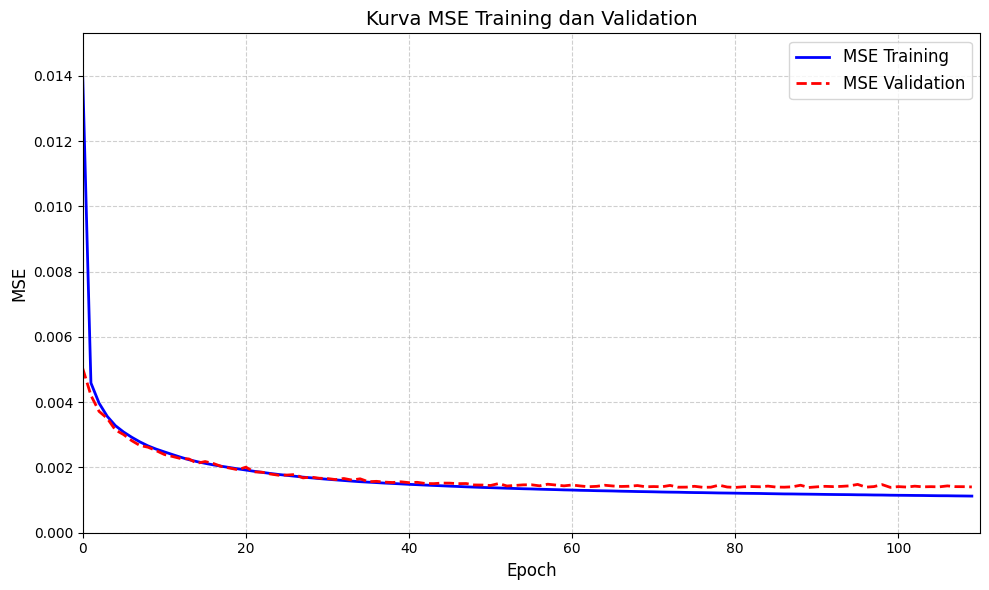

In [ ]:
# Ambil data MSE dari riwayat training
mse_training = history.history['loss']
mse_validation = history.history['val_loss']

# Buat plot
plt.figure(figsize=(10, 6))  # Adjust figure size for better visualization
plt.plot(mse_training, label='MSE Training', color='blue', linewidth=2)  # Customize line style
plt.plot(mse_validation, label='MSE Validation', color='red', linestyle='--', linewidth=2)  # Customize line style
plt.title('Kurva MSE Training dan Validation', fontsize=14)  # Increase title font size
plt.xlabel('Epoch', fontsize=12)  # Increase label font size
plt.ylabel('MSE', fontsize=12)  # Increase label font size
plt.xlim(0, len(mse_training))  # Set x-axis limit to the number of epochs
plt.ylim(0, max(max(mse_training), max(mse_validation)) * 1.1)  # Adjust y-axis limit for better visualization
plt.grid(True, linestyle='--', alpha=0.6)  # Add grid for better readability
plt.legend(fontsize=12)  # Increase legend font size
plt.tight_layout()  # Adjust layout to prevent labels from overlapping
plt.show()

In [ ]:
# ... (your model training code) ...
model.save('/content/drive/MyDrive/Tugas Akhir/Model/CNN_GRU_Model_Scratch_takhingga_2.h5')  # Save the model

#Deploy model dan Prediksi

In [ ]:
model = tf.keras.models.load_model('/content/drive/MyDrive/Tugas Akhir/Model/CNN_GRU_Model_Scratch_takhingga_2.h5')

In [ ]:

# Forward modelling untuk data input
resis_true= np.array([5000,8000])
ketebalan_true = np.array([1000])
frequencies = np.array(np.logspace(-4,4, num=69))
period = 1/frequencies
resistivitas_semu, fasa = forward_modelling(resis_true, ketebalan_true, frequencies)

resistivitas_semu = np.array([resistivitas_semu])
fasa = np.array([fasa])

#Reshape sebelum normalisasi
resistivitas_semu = resistivitas_semu[0].reshape(1, X_input_res.shape[1]) # Corrected reshape syntax
fasa = fasa.reshape(1, X_input_phase.shape[1])

#Logaritmik
resistivitas_semu_log = np.log10(resistivitas_semu)
fasa_log = np.log10(fasa)

# Normalisasi data input
resistivitas_semu_normalized = input_res_scaler.transform(resistivitas_semu_log)
fasa_normalized = input_phase_scaler.transform(fasa_log)

# Reshape jika perlu (misalnya, untuk input CNN)
resistivitas_semu_normalized = resistivitas_semu_normalized.reshape(1, X_input_res.shape[1], 1)
fasa_normalized = fasa_normalized.reshape(1, X_input_phase.shape[1], 1)

# Prediksi
predictions = model.predict([resistivitas_semu_normalized, fasa_normalized])

# Denormalisasi hasil prediksi, apply to the predictions, not hasil
predictions_denormalized = output_model_scaler.inverse_transform(predictions)
predictions_denormalized = np.power(10, predictions_denormalized)

# Accessing the values from predictions_denormalized
resis_predict = predictions_denormalized[0]
ketebalan_predict = np.full(jumlah_layer-1,layer_thickness)#Access elements from index 4 onwards

#Forward Modelling from prediction model
resistivitas_semu_predict, fasa_predict = forward_modelling(resis_predict, ketebalan_predict, frequencies)

resistivitas_semu_predict = np.array([resistivitas_semu_predict])
fasa_predict = np.array([fasa_predict])


#print(hasil) #No need to print hasil as it's not used

print("Nilai Resis_True", resis_true)
print("Nilai ketebalan_True",ketebalan_true)
print("Nilai resis_predict",resis_predict)
print("Nilai ketebalan_predict",ketebalan_predict)

1/1 ━━━━━━━━━━━━━━━━━━━━ 1s 986ms/step
Nilai Resis_True [5000 8000]
Nilai ketebalan_True [1000]
Nilai resis_predict [5025.061  5147.024  5004.076  4588.663  5485.167  7282.106  8222.851
 8433.637  8169.5757 8036.178  7652.173  7852.3647 8051.7886 7839.684
 8233.903  7438.1343 8045.1963 7606.52   7993.1343 7856.3486]
Nilai ketebalan_predict [200. 200. 200. 200. 200. 200. 200. 200. 200. 200. 200. 200. 200. 200.
 200. 200. 200. 200. 200.]


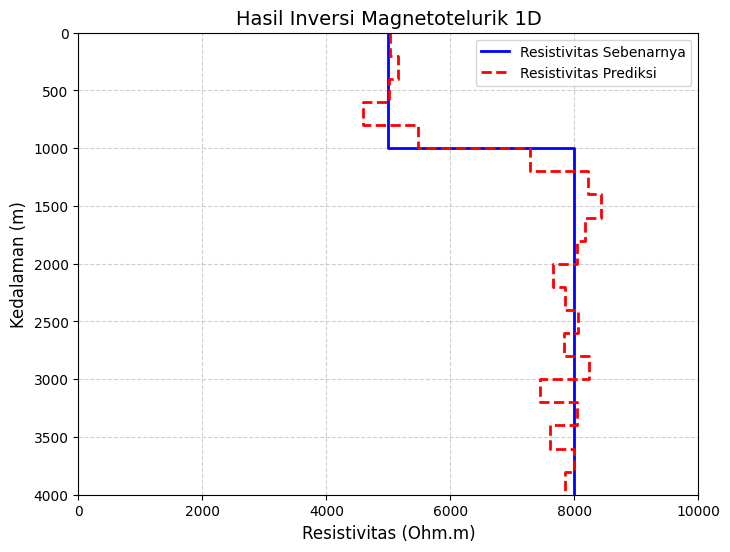

In [ ]:
plot_model_compare(resis_true, ketebalan_true, resis_predict, ketebalan_predict, total_depth)

#Grafik

In [ ]:
plt.style.use('default')

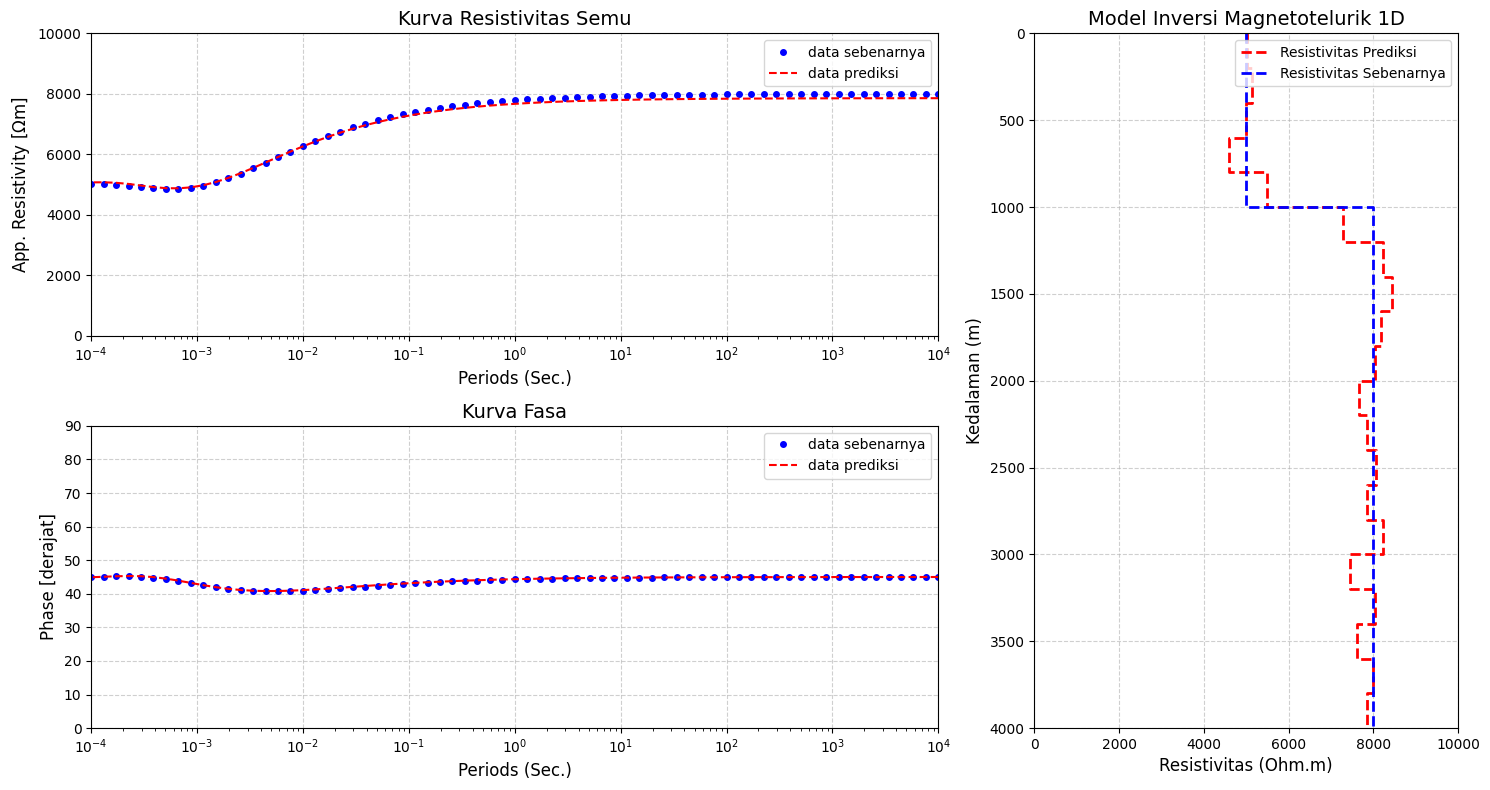

In [ ]:
plot_MT_compare(resis_true, ketebalan_true, resis_predict, ketebalan_predict, period, fasa, resistivitas_semu, fasa_predict,resistivitas_semu_predict, total_depth)

#Perhitungan Error

In [ ]:
measure_MSE(resistivitas_semu, fasa, resistivitas_semu_predict, fasa_predict)

MSE Resistivitas Semu: 11729.09
MSE Fasa: 0.01


In [ ]:
measure_MAPE(resistivitas_semu, fasa, resistivitas_semu_predict, fasa_predict)

MAPE resistivitas semu: 1.27%
MAPE fasa: 0.00%


[Interpolated] MSE model resistivitas: 96455.2322
[Interpolated] MAPE model resistivitas: 3.37%


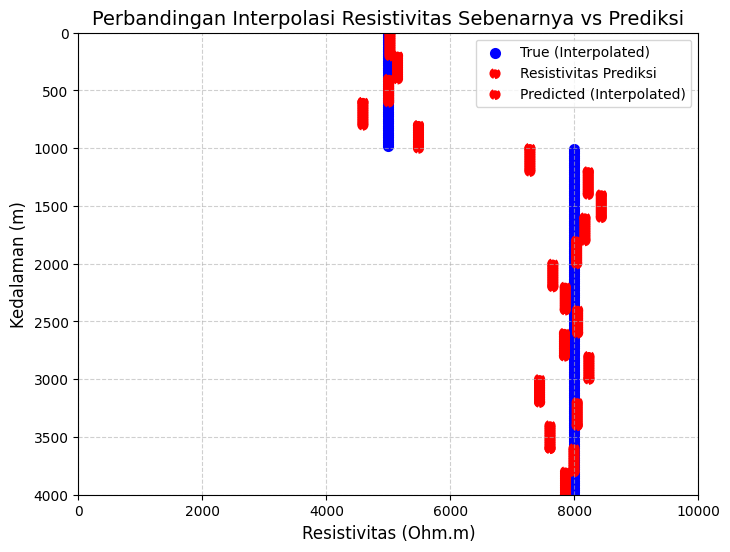

In [ ]:
measure_interpolated_resistivities(resis_true, ketebalan_true, resis_predict, ketebalan_predict, total_depth)

#Prediksi Data Training

##Prediksi

In [ ]:
# Ambil ground truth untuk sample ke-0
resis_true = y_train[149].reshape(1, -1)
resis_true = output_model_scaler.inverse_transform(resis_true)  # Undo MinMax
resis_true = np.power(10, resis_true)  # Undo log10

ketebalan_true = np.full(jumlah_layer-1, layer_thickness)

# Ambil input data asli sample ke-0 dan inverse normalisasi
resistivitas_semu = X_train_res[149].reshape(1, -1)
fasa = X_train_phase[149].reshape(1, -1)

# Undo normalisasi (hasilnya masih log10)
resistivitas_semu_log = input_res_scaler.inverse_transform(resistivitas_semu)
fasa_log = input_phase_scaler.inverse_transform(fasa)

# Undo logaritma → dapat nilai asli
resistivitas_semu = np.power(10, resistivitas_semu_log)
fasa = np.power(10, fasa_log)

# Sekarang: jika kamu ingin **prediksi ulang**, maka:
# 1. Ambil resistivitas_semu & fasa (asli), lalu
# 2. log10 lagi → normalisasi lagi

resistivitas_semu_log = np.log10(resistivitas_semu)
fasa_log = np.log10(fasa)

resistivitas_semu_normalized = input_res_scaler.transform(resistivitas_semu_log)
fasa_normalized = input_phase_scaler.transform(fasa_log)

# Reshape untuk CNN-GRU input
resistivitas_semu_normalized = resistivitas_semu_normalized.reshape(1, X_input_res.shape[1], 1)
fasa_normalized = fasa_normalized.reshape(1, X_input_phase.shape[1], 1)

# Prediksi model
predictions = model.predict([resistivitas_semu_normalized, fasa_normalized])

# Undo normalisasi dan log10 dari output
predictions_denormalized = output_model_scaler.inverse_transform(predictions)
predictions_denormalized = np.power(10, predictions_denormalized)

# Split hasil prediksi
resis_predict = predictions_denormalized[0]  # jika output hanya resistivitas saja
ketebalan_predict = np.full(jumlah_layer-1, layer_thickness)

# Forward modelling
resistivitas_semu_predict, fasa_predict = forward_modelling(resis_predict, ketebalan_predict, frequencies)

resistivitas_semu_predict = np.array([resistivitas_semu_predict])
fasa_predict = np.array([fasa_predict])

#print(hasil) #No need to print hasil as it's not used


print("Nilai resis_predict",resis_predict)
print("Nilai ketebalan_predict",ketebalan_predict)

1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 43ms/step
Nilai resis_predict [1080.6207  2495.1677  2849.6626  3554.294    935.50366  882.74567
  980.7037   532.73004 1041.0505  2415.1367  3708.2585  3802.6929
 3687.0984  2939.7466   663.02747  193.25455 1834.1653  3809.519
 3511.9336  2611.4792 ]
Nilai ketebalan_predict [200. 200. 200. 200. 200. 200. 200. 200. 200. 200. 200. 200. 200. 200.
 200. 200. 200. 200. 200.]


##Grafik

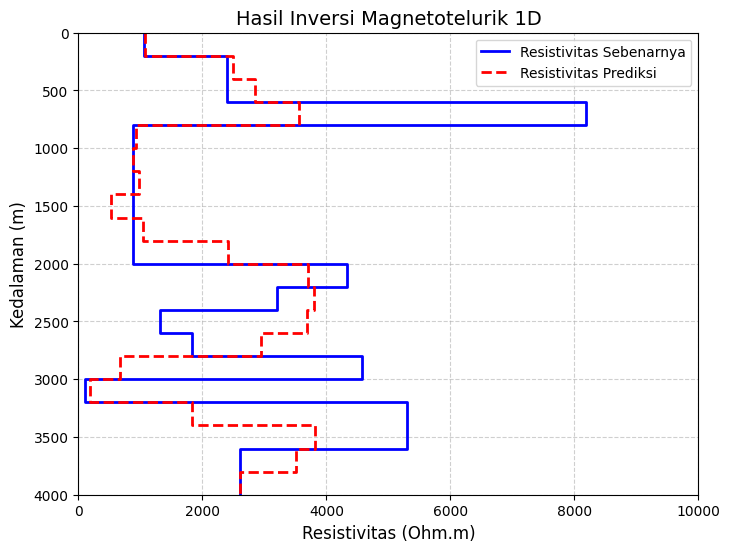

In [ ]:

plot_model_compare(resis_predict,ketebalan_predict, resis_true, ketebalan_true, total_depth)

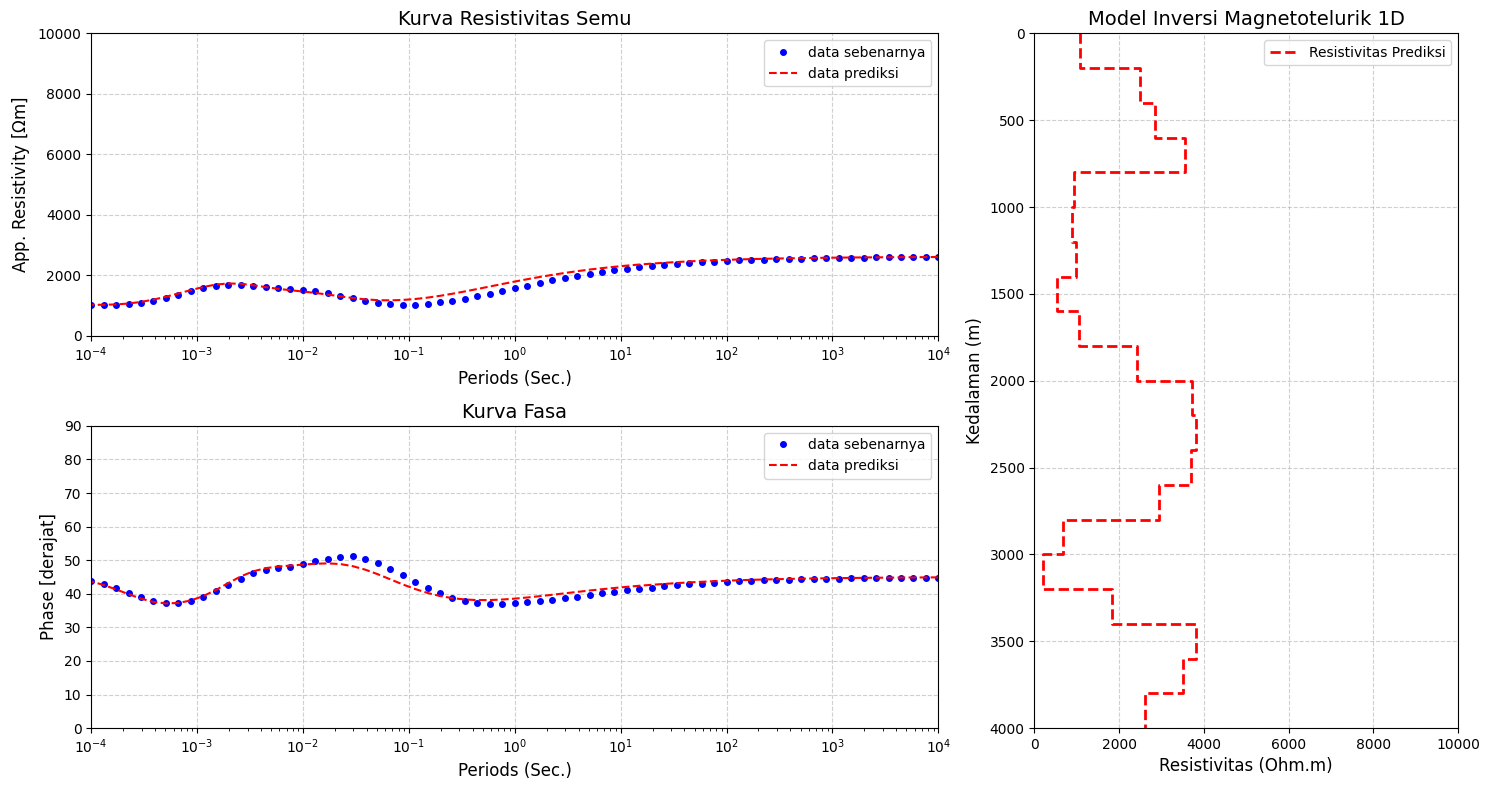

In [ ]:
plot_MT(resis_predict,ketebalan_predict, period, fasa, resistivitas_semu, fasa_predict,resistivitas_semu_predict, total_depth)

##Error

In [ ]:
measure_MSE(resistivitas_semu, fasa, resistivitas_semu_predict, fasa_predict)

MSE Resistivitas Semu: 11484.14
MSE Fasa: 1.32


In [ ]:
measure_MAPE(resistivitas_semu, fasa, resistivitas_semu_predict, fasa_predict)

MAPE resistivitas semu: 5.10%
MAPE fasa: 0.06%


#Prediksi Data Validasi

##Prediksi

In [ ]:
# Ambil ground truth untuk sample ke-0
resis_true = y_val[2].reshape(1, -1)
resis_true = output_model_scaler.inverse_transform(resis_true)  # Undo MinMax
resis_true = np.power(10, resis_true)  # Undo log10

ketebalan_true = np.full(jumlah_layer-1, layer_thickness)

# Ambil input data asli sample ke-0 dan inverse normalisasi
resistivitas_semu = X_val_res[2].reshape(1, -1)
fasa = X_val_phase[2].reshape(1, -1)

# Undo normalisasi (hasilnya masih log10)
resistivitas_semu_log = input_res_scaler.inverse_transform(resistivitas_semu)
fasa_log = input_phase_scaler.inverse_transform(fasa)

# Undo logaritma → dapat nilai asli
resistivitas_semu = np.power(10, resistivitas_semu_log)
fasa = np.power(10, fasa_log)

# Sekarang: jika kamu ingin **prediksi ulang**, maka:
# 1. Ambil resistivitas_semu & fasa (asli), lalu
# 2. log10 lagi → normalisasi lagi

resistivitas_semu_log = np.log10(resistivitas_semu)
fasa_log = np.log10(fasa)

resistivitas_semu_normalized = input_res_scaler.transform(resistivitas_semu_log)
fasa_normalized = input_phase_scaler.transform(fasa_log)

# Reshape untuk CNN-GRU input
resistivitas_semu_normalized = resistivitas_semu_normalized.reshape(1, X_input_res.shape[1], 1)
fasa_normalized = fasa_normalized.reshape(1, X_input_phase.shape[1], 1)

# Prediksi model
predictions = model.predict([resistivitas_semu_normalized, fasa_normalized])

# Undo normalisasi dan log10 dari output
predictions_denormalized = output_model_scaler.inverse_transform(predictions)
predictions_denormalized = np.power(10, predictions_denormalized)

# Split hasil prediksi
resis_predict = predictions_denormalized[0]  # jika output hanya resistivitas saja
ketebalan_predict = np.full(jumlah_layer-1, layer_thickness)

# Forward modelling
resistivitas_semu_predict, fasa_predict = forward_modelling(resis_predict, ketebalan_predict, frequencies)

resistivitas_semu_predict = np.array([resistivitas_semu_predict])
fasa_predict = np.array([fasa_predict])

#print(hasil) #No need to print hasil as it's not used


print("Nilai resis_predict",resis_predict)
print("Nilai ketebalan_predict",ketebalan_predict)

1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 43ms/step
Nilai resis_predict [5839.46    6082.367   6283.889   5421.797   6380.2886  5788.04
 5095.479   1162.3545  2713.8638  4391.2617  4490.9824  3025.1704
 2776.329   2993.162   1779.4279   143.6132   163.85895 5912.5493
 5979.485   9108.161  ]
Nilai ketebalan_predict [200. 200. 200. 200. 200. 200. 200. 200. 200. 200. 200. 200. 200. 200.
 200. 200. 200. 200. 200.]


##Grafik

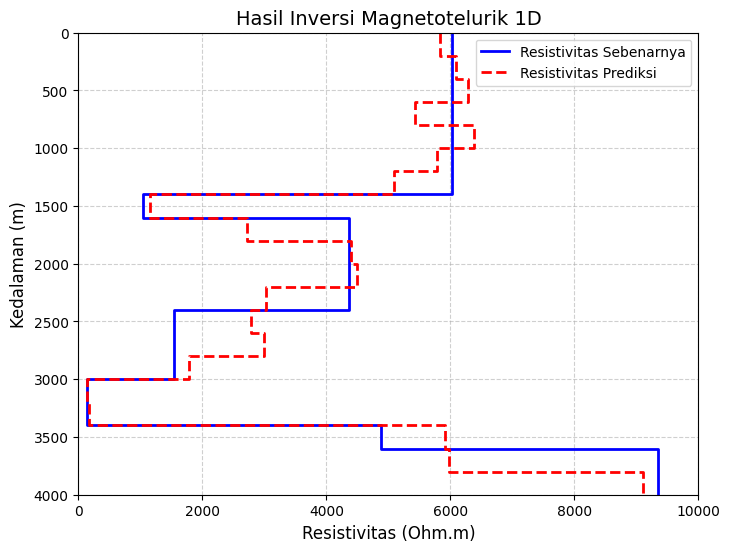

In [ ]:
plot_model_compare(resis_predict,ketebalan_predict, resis_true, ketebalan_predict, total_depth)

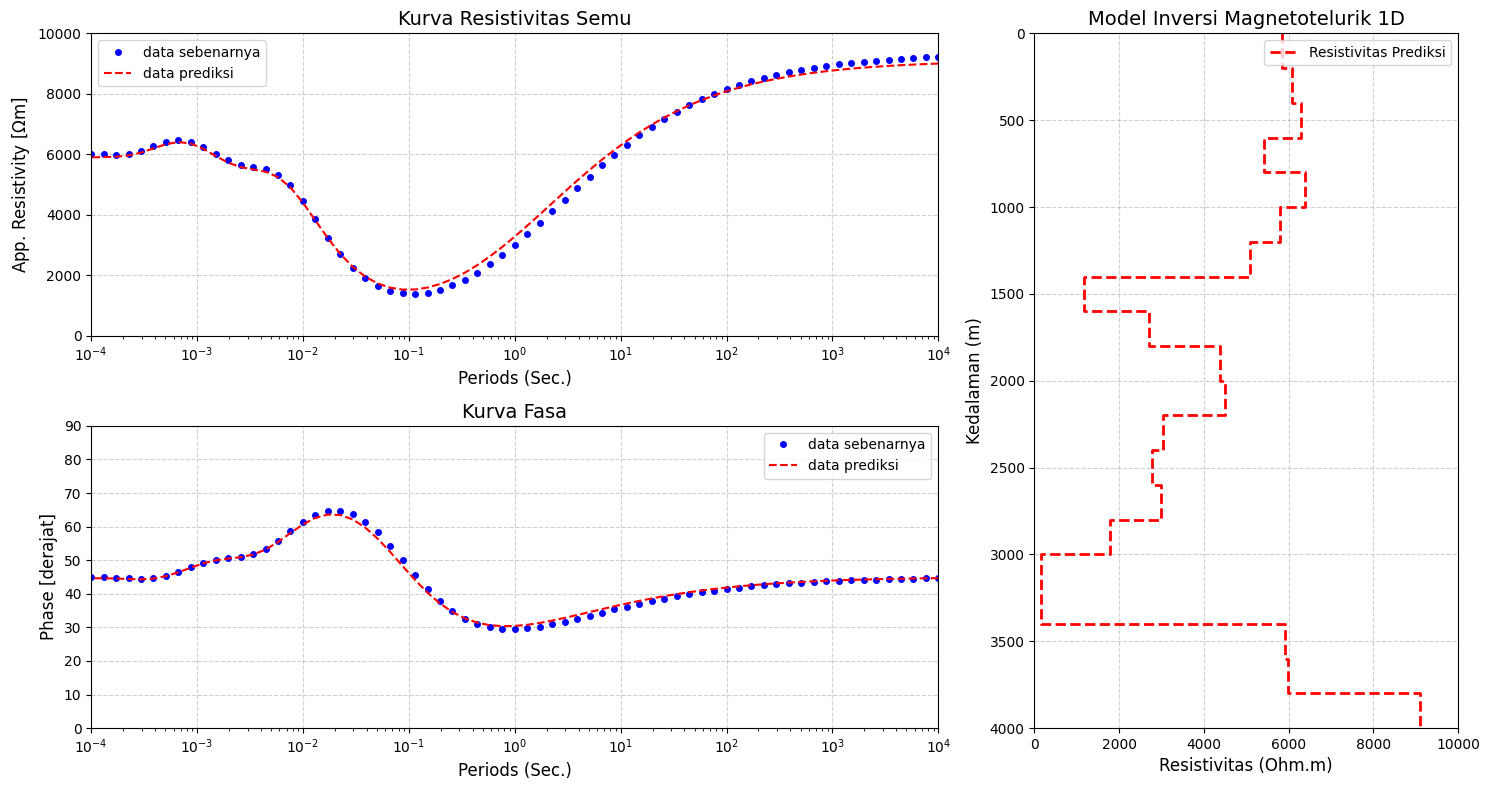

In [ ]:
plot_MT(resis_predict,ketebalan_predict, period, fasa, resistivitas_semu, fasa_predict,resistivitas_semu_predict, total_depth)

##Error

In [ ]:
measure_MSE(resistivitas_semu, fasa, resistivitas_semu_predict, fasa_predict)

MSE Resistivitas Semu: 8973619.01
MSE Fasa: 1.65


In [ ]:
measure_MAPE(resistivitas_semu, fasa, resistivitas_semu_predict, fasa_predict)

MAPE resistivitas semu: 99.85%
MAPE fasa: 0.03%


#Prediksi Model bumi Homogen

##Model Bumi Homogen 1

###Prediksi

In [ ]:

# Forward modelling untuk data input
resis_true= np.array([3000,3000])
ketebalan_true = np.array([2000])
frequencies = np.array(np.logspace(-4,4, num=69))
period = 1/frequencies
resistivitas_semu, fasa = forward_modelling(resis_true, ketebalan_true, frequencies)

resistivitas_semu = np.array([resistivitas_semu])
fasa = np.array([fasa])

#Reshape sebelum normalisasi
resistivitas_semu = resistivitas_semu[0].reshape(1, X_input_res.shape[1]) # Corrected reshape syntax
fasa = fasa.reshape(1, X_input_phase.shape[1])

#Logaritmik
resistivitas_semu_log = np.log10(resistivitas_semu)
fasa_log = np.log10(fasa)

# Normalisasi data input
resistivitas_semu_normalized = input_res_scaler.transform(resistivitas_semu_log)
fasa_normalized = input_phase_scaler.transform(fasa_log)

# Reshape jika perlu (misalnya, untuk input CNN)
resistivitas_semu_normalized = resistivitas_semu_normalized.reshape(1, X_input_res.shape[1], 1)
fasa_normalized = fasa_normalized.reshape(1, X_input_phase.shape[1], 1)

# Prediksi
predictions = model.predict([resistivitas_semu_normalized, fasa_normalized])

# Denormalisasi hasil prediksi, apply to the predictions, not hasil
predictions_denormalized = output_model_scaler.inverse_transform(predictions)
predictions_denormalized = np.power(10, predictions_denormalized)

# Accessing the values from predictions_denormalized
resis_predict = predictions_denormalized[0]
ketebalan_predict = np.full(jumlah_layer-1,layer_thickness)#Access elements from index 4 onwards

#Forward Modelling from prediction model
resistivitas_semu_predict, fasa_predict = forward_modelling(resis_predict, ketebalan_predict, frequencies)

resistivitas_semu_predict = np.array([resistivitas_semu_predict])
fasa_predict = np.array([fasa_predict])


#print(hasil) #No need to print hasil as it's not used

print("Nilai Resis_True", resis_true)
print("Nilai ketebalan_True",ketebalan_true)
print("Nilai resis_predict",resis_predict)
print("Nilai ketebalan_predict",ketebalan_predict)

1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 45ms/step
Nilai Resis_True [3000 3000]
Nilai ketebalan_True [2000]
Nilai resis_predict [3020.3066 3058.8774 3075.5457 2861.2644 2967.4897 3167.563  3031.318
 2909.4773 2849.0322 3171.3684 3092.4524 2963.4783 3023.8901 2957.0413
 3046.9346 2867.5386 3087.7925 2809.8848 2775.2761 2988.8684]
Nilai ketebalan_predict [200. 200. 200. 200. 200. 200. 200. 200. 200. 200. 200. 200. 200. 200.
 200. 200. 200. 200. 200.]


###Grafik

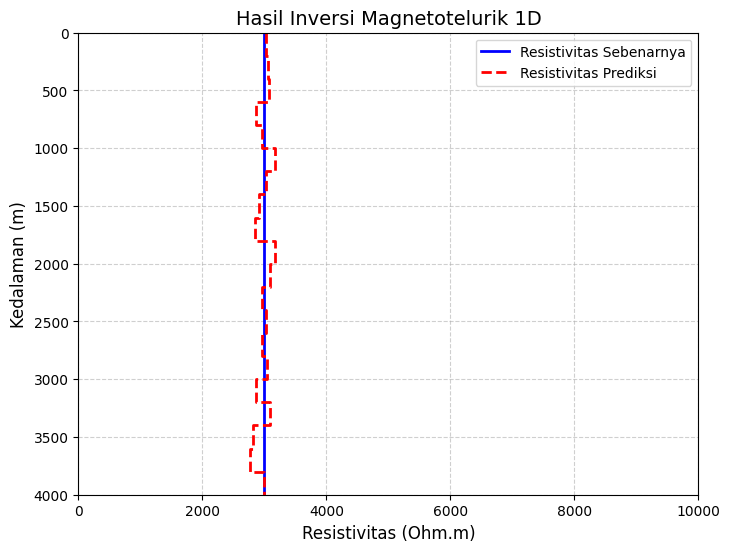

In [ ]:


plot_model_compare(resis_true, ketebalan_true, resis_predict, ketebalan_predict, total_depth)


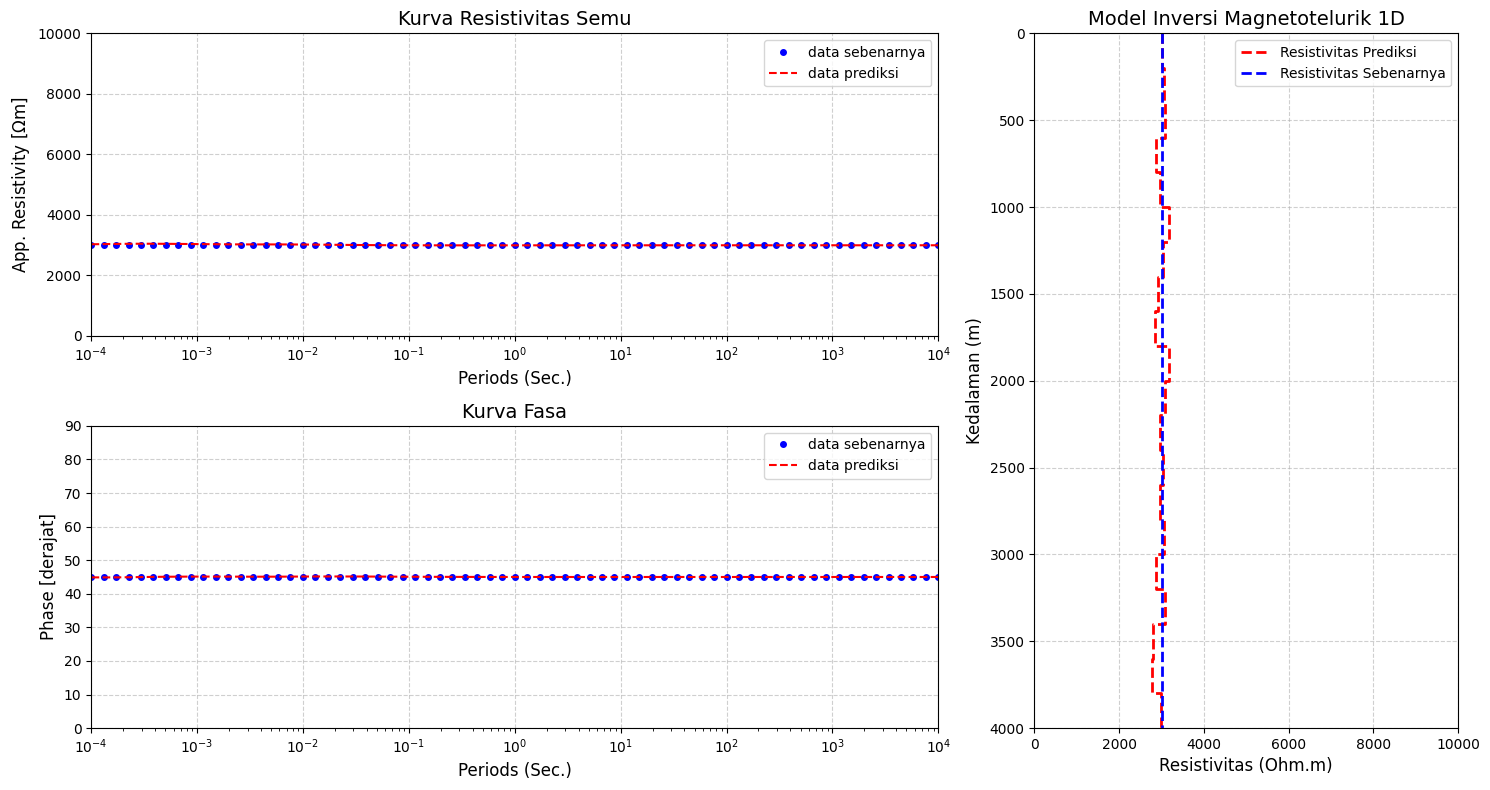

In [ ]:
plot_MT_compare(resis_true, ketebalan_true, resis_predict, ketebalan_predict, period, fasa, resistivitas_semu, fasa_predict,resistivitas_semu_predict, total_depth)

###Error

In [ ]:
measure_MSE(resistivitas_semu, fasa, resistivitas_semu_predict, fasa_predict)

MSE Resistivitas Semu: 288.84
MSE Fasa: 0.00


In [ ]:
measure_MAPE(resistivitas_semu, fasa, resistivitas_semu_predict, fasa_predict)

MAPE resistivitas semu: 0.50%
MAPE fasa: 0.00%


[Interpolated] MSE model resistivitas: 12291.1946
[Interpolated] MAPE model resistivitas: 3.04%


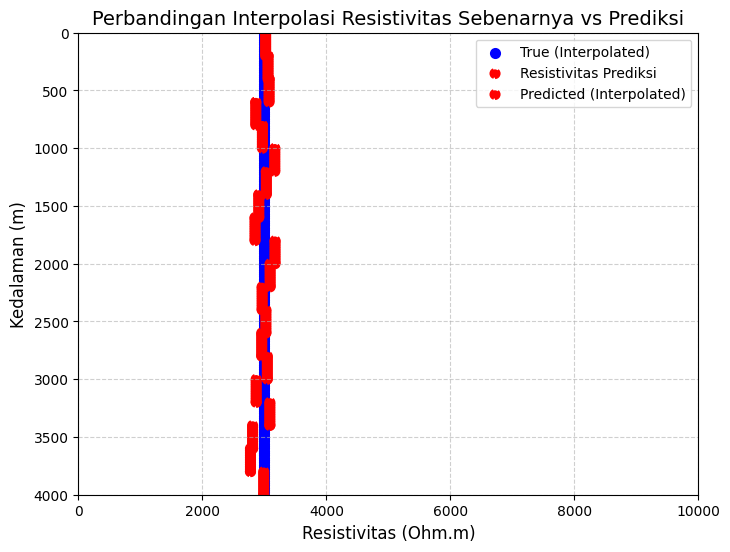

In [ ]:
measure_interpolated_resistivities(resis_true, ketebalan_true, resis_predict, ketebalan_predict, total_depth)

##Model Bumi Homogen 2

###Prediksi

In [ ]:
# Forward modelling untuk data input
resis_true= np.array([5000,5000])
ketebalan_true = np.array([2000])
frequencies = np.array(np.logspace(-4,4, num=69))
period = 1/frequencies
resistivitas_semu, fasa = forward_modelling(resis_true, ketebalan_true, frequencies)

resistivitas_semu = np.array([resistivitas_semu])
fasa = np.array([fasa])

#Reshape sebelum normalisasi
resistivitas_semu = resistivitas_semu[0].reshape(1, X_input_res.shape[1]) # Corrected reshape syntax
fasa = fasa.reshape(1, X_input_phase.shape[1])

#logaritmik Dataset
resistivitas_semu_log = np.log10(resistivitas_semu)
fasa_log = np.log10(fasa)

# Normalisasi data input
resistivitas_semu_normalized = input_res_scaler.transform(resistivitas_semu_log)
fasa_normalized = input_phase_scaler.transform(fasa_log)

# Reshape jika perlu (misalnya, untuk input CNN)
resistivitas_semu_normalized = resistivitas_semu_normalized.reshape(1, X_input_res.shape[1], 1)
fasa_normalized = fasa_normalized.reshape(1, X_input_phase.shape[1], 1)

# Prediksi
predictions = model.predict([resistivitas_semu_normalized, fasa_normalized])

# Denormalisasi hasil prediksi, apply to the predictions, not hasil
predictions_denormalized = output_model_scaler.inverse_transform(predictions)
predictions_denormalized = np.power(10, predictions_denormalized)

# Accessing the values from predictions_denormalized
resis_predict = predictions_denormalized[0]
ketebalan_predict = np.full(jumlah_layer-1,layer_thickness)#Access elements from index 4 onwards

#Forward Modelling from prediction model
resistivitas_semu_predict, fasa_predict = forward_modelling(resis_predict, ketebalan_predict, frequencies)

resistivitas_semu_predict = np.array([resistivitas_semu_predict])
fasa_predict = np.array([fasa_predict])


#print(hasil) #No need to print hasil as it's not used

print("Nilai Resis_True", resis_true)
print("Nilai ketebalan_True",ketebalan_true)
print("Nilai resis_predict",resis_predict)
print("Nilai ketebalan_predict",ketebalan_predict)

1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 81ms/step
Nilai Resis_True [5000 5000]
Nilai ketebalan_True [2000]
Nilai resis_predict [5020.991  5193.257  5013.323  4843.669  4950.518  5121.4004 5041.7124
 4971.2544 4903.42   5132.828  4994.4453 5015.484  4940.8877 4934.1953
 5081.5117 4783.0054 5132.693  4756.929  4683.2876 5021.1978]
Nilai ketebalan_predict [200. 200. 200. 200. 200. 200. 200. 200. 200. 200. 200. 200. 200. 200.
 200. 200. 200. 200. 200.]


###Grafik

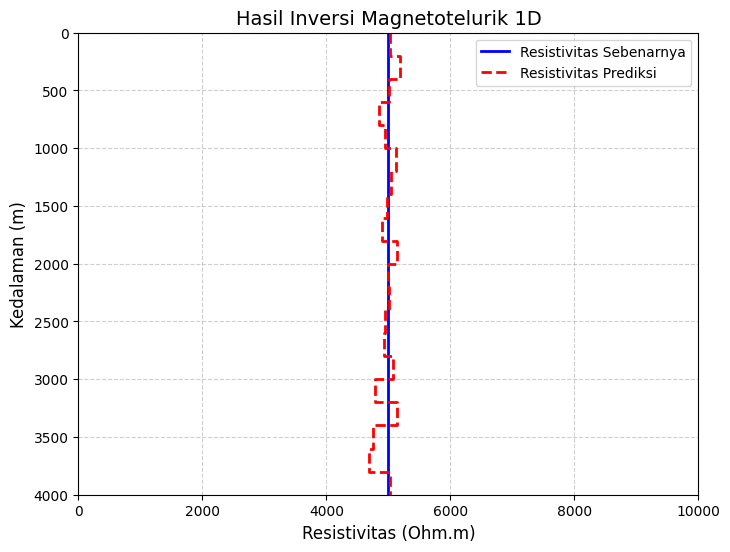

In [ ]:
plot_model_compare(resis_true, ketebalan_true, resis_predict, ketebalan_predict, total_depth)

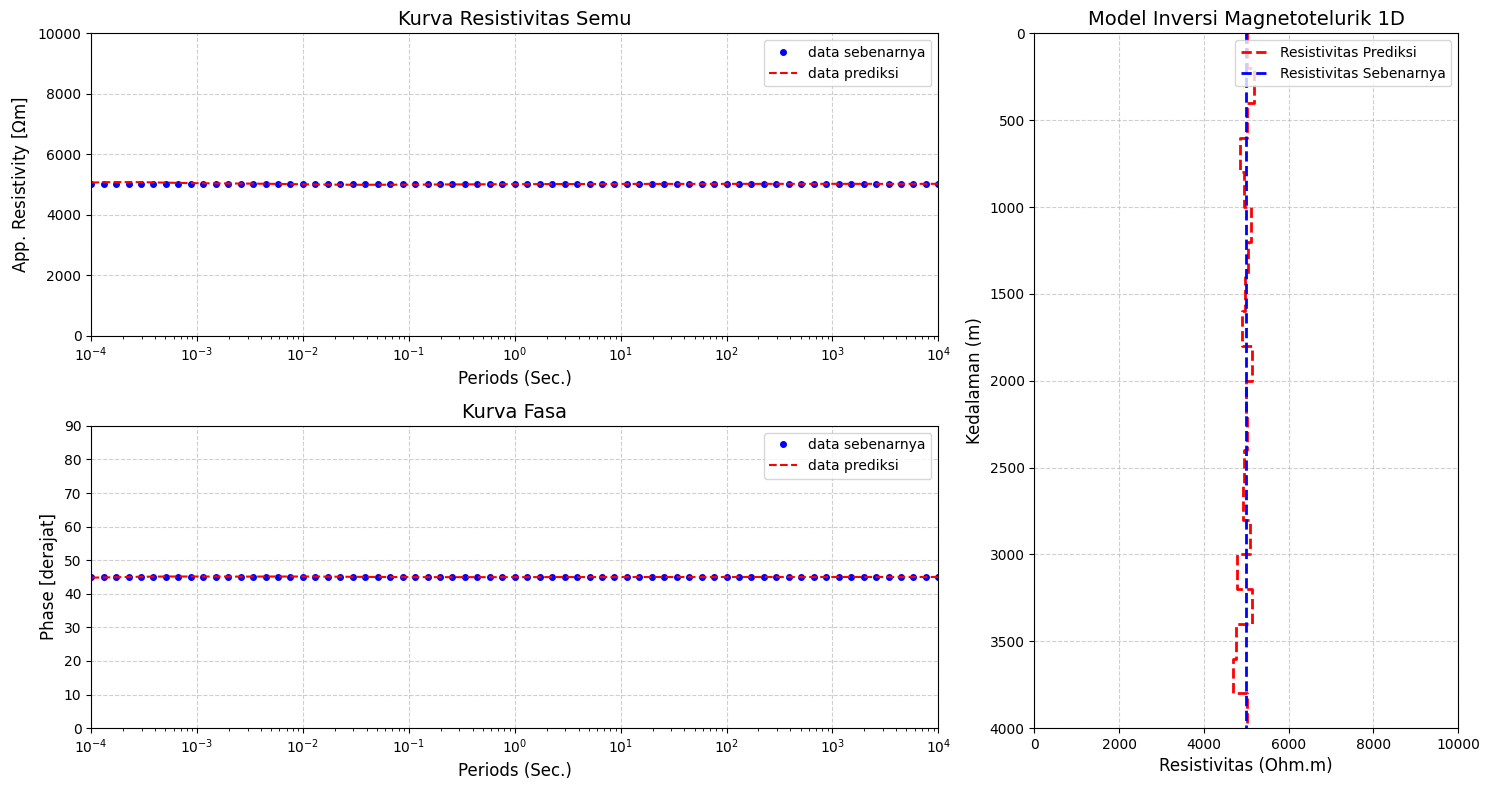

In [ ]:
plot_MT_compare(resis_true, ketebalan_true, resis_predict, ketebalan_predict, period, fasa, resistivitas_semu, fasa_predict,resistivitas_semu_predict, total_depth)

###Error

In [ ]:
measure_MSE(resistivitas_semu, fasa, resistivitas_semu_predict, fasa_predict)

MSE Resistivitas Semu: 878.46
MSE Fasa: 0.00


In [ ]:
measure_MAPE(resistivitas_semu, fasa, resistivitas_semu_predict, fasa_predict)

MAPE resistivitas semu: 0.46%
MAPE fasa: 0.00%


[Interpolated] MSE model resistivitas: 17420.1188
[Interpolated] MAPE model resistivitas: 2.01%


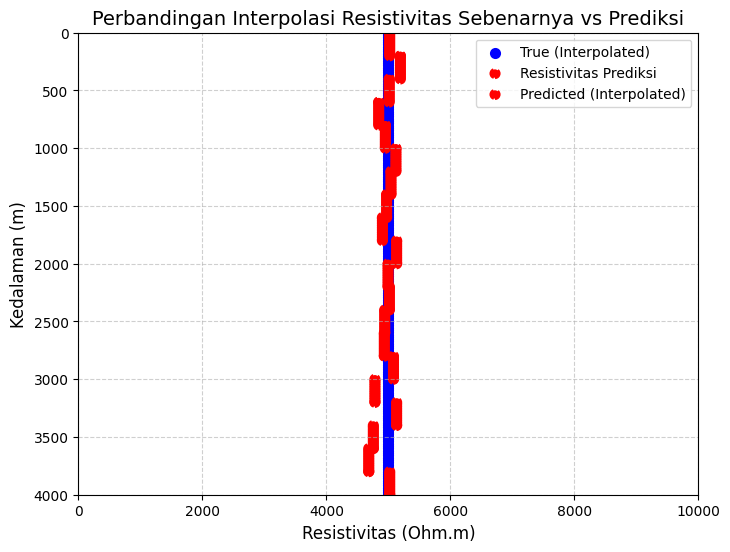

In [ ]:
measure_interpolated_resistivities(resis_true, ketebalan_true, resis_predict, ketebalan_predict, total_depth)

##Model Bumi Homogen 3

###Prediksi

In [ ]:
# Forward modelling untuk data input
resis_true= np.array([9000,9000])
ketebalan_true = np.array([2000])
frequencies = np.array(np.logspace(-4,4, num=69))
period = 1/frequencies
resistivitas_semu, fasa = forward_modelling(resis_true, ketebalan_true, frequencies)

resistivitas_semu = np.array([resistivitas_semu])
fasa = np.array([fasa])

#Reshape sebelum normalisasi
resistivitas_semu = resistivitas_semu[0].reshape(1, X_input_res.shape[1]) # Corrected reshape syntax
fasa = fasa.reshape(1, X_input_phase.shape[1])

#Logaritmik
resistivitas_semu_log = np.log10(resistivitas_semu)
fasa_log = np.log10(fasa)

# Normalisasi data input
resistivitas_semu_normalized = input_res_scaler.transform(resistivitas_semu_log)
fasa_normalized = input_phase_scaler.transform(fasa_log)

# Reshape jika perlu (misalnya, untuk input CNN)
resistivitas_semu_normalized = resistivitas_semu_normalized.reshape(1, X_input_res.shape[1], 1)
fasa_normalized = fasa_normalized.reshape(1, X_input_phase.shape[1], 1)

# Prediksi
predictions = model.predict([resistivitas_semu_normalized, fasa_normalized])

# Denormalisasi hasil prediksi, apply to the predictions, not hasil
predictions_denormalized = output_model_scaler.inverse_transform(predictions)
predictions_denormalized = np.power(10, predictions_denormalized)

# Accessing the values from predictions_denormalized
resis_predict = predictions_denormalized[0]
ketebalan_predict = np.full(jumlah_layer-1,layer_thickness)#Access elements from index 4 onwards

#Forward Modelling from prediction model
resistivitas_semu_predict, fasa_predict = forward_modelling(resis_predict, ketebalan_predict, frequencies)

resistivitas_semu_predict = np.array([resistivitas_semu_predict])
fasa_predict = np.array([fasa_predict])


#print(hasil) #No need to print hasil as it's not used

print("Nilai Resis_True", resis_true)
print("Nilai ketebalan_True",ketebalan_true)
print("Nilai resis_predict",resis_predict)
print("Nilai ketebalan_predict",ketebalan_predict)

1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 57ms/step
Nilai Resis_True [9000 9000]
Nilai ketebalan_True [2000]
Nilai resis_predict [8862.019  9250.391  8622.102  8569.27   9048.778  9357.348  9065.405
 8987.981  9042.402  9235.7    8793.541  8867.883  8946.875  8545.56
 9176.383  8488.345  9190.3125 8678.918  9044.423  8734.401 ]
Nilai ketebalan_predict [200. 200. 200. 200. 200. 200. 200. 200. 200. 200. 200. 200. 200. 200.
 200. 200. 200. 200. 200.]


###Grafik

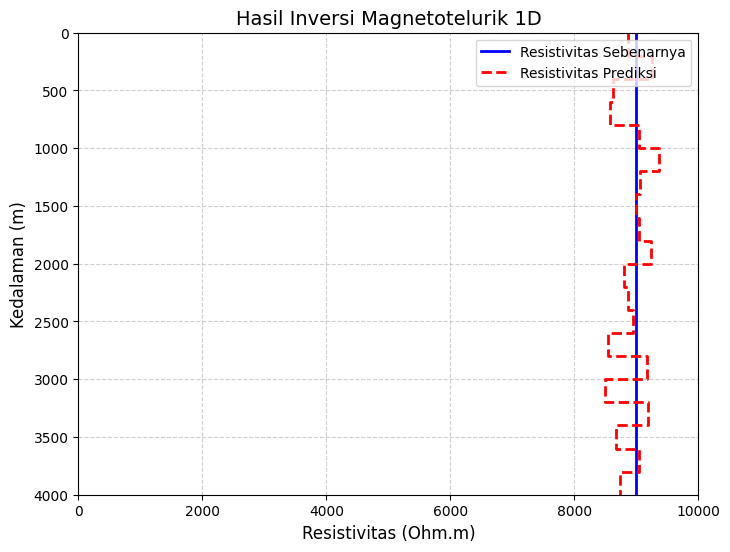

In [ ]:
plot_model_compare(resis_true, ketebalan_true, resis_predict, ketebalan_predict, total_depth)

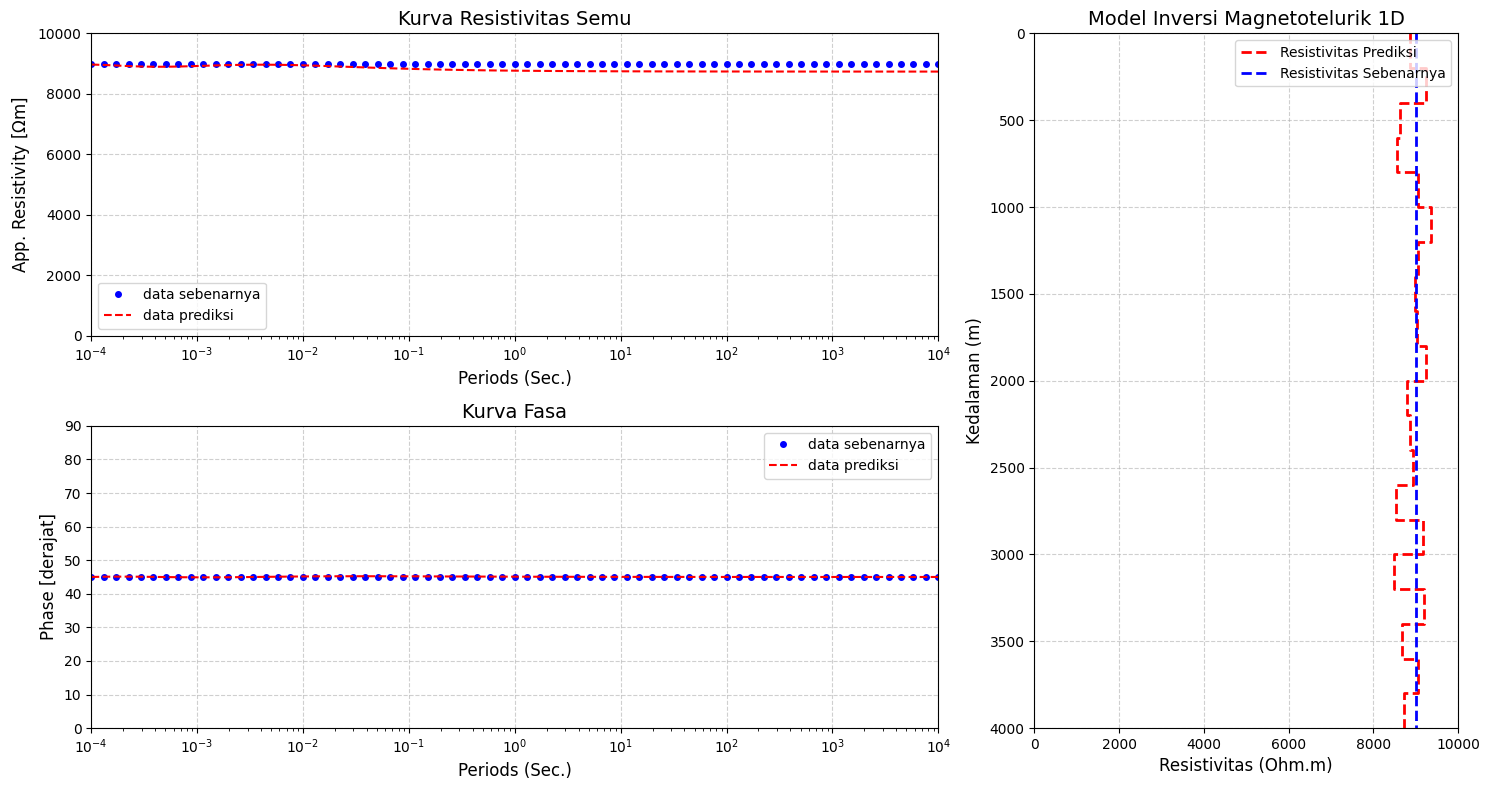

In [ ]:
plot_MT_compare(resis_true, ketebalan_true, resis_predict, ketebalan_predict, period, fasa, resistivitas_semu, fasa_predict,resistivitas_semu_predict, total_depth)

###Error

In [ ]:
measure_MSE(resistivitas_semu, fasa, resistivitas_semu_predict, fasa_predict)

MSE Resistivitas Semu: 42099.94
MSE Fasa: 0.01


In [ ]:
measure_MAPE(resistivitas_semu, fasa, resistivitas_semu_predict, fasa_predict)

MAPE resistivitas semu: 2.07%
MAPE fasa: 0.00%


[Interpolated] MSE model resistivitas: 68803.5504
[Interpolated] MAPE model resistivitas: 2.40%


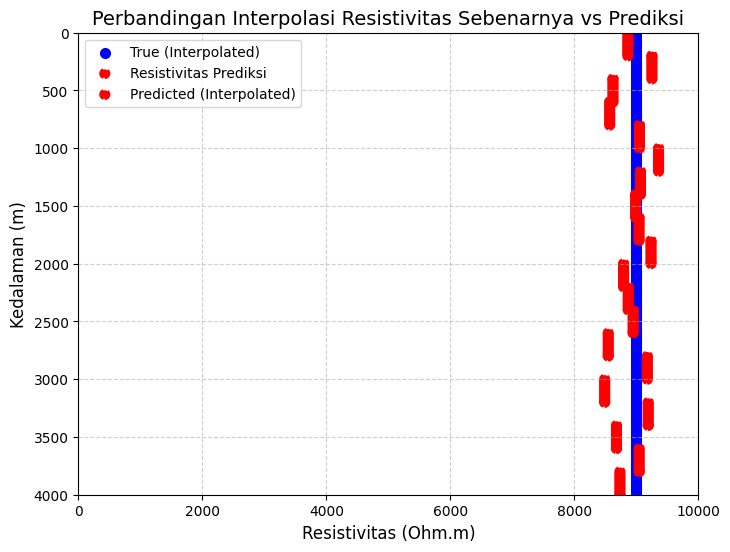

In [ ]:
measure_interpolated_resistivities(resis_true, ketebalan_true, resis_predict, ketebalan_predict, total_depth)

# Prediksi Model Bumi 2 lapis

## Model Bumi 2 lapis I

### Prediksi

In [ ]:
# Forward modelling untuk data input
resis_true= np.array([200,8000])
ketebalan_true = np.array([2000])
frequencies = np.array(np.logspace(-4,4, num=69))
period = 1/frequencies
resistivitas_semu, fasa = forward_modelling(resis_true, ketebalan_true, frequencies)

resistivitas_semu = np.array([resistivitas_semu])
fasa = np.array([fasa])

#Reshape sebelum normalisasi
resistivitas_semu = resistivitas_semu[0].reshape(1, X_input_res.shape[1]) # Corrected reshape syntax
fasa = fasa.reshape(1, X_input_phase.shape[1])

#Logaritmik
resistivitas_semu_log = np.log10(resistivitas_semu)
fasa_log = np.log10(fasa)

# Normalisasi data input
resistivitas_semu_normalized = input_res_scaler.transform(resistivitas_semu_log)
fasa_normalized = input_phase_scaler.transform(fasa_log)

# Reshape jika perlu (misalnya, untuk input CNN)
resistivitas_semu_normalized = resistivitas_semu_normalized.reshape(1, X_input_res.shape[1], 1)
fasa_normalized = fasa_normalized.reshape(1, X_input_phase.shape[1], 1)

# Prediksi
predictions = model.predict([resistivitas_semu_normalized, fasa_normalized])

# Denormalisasi hasil prediksi, apply to the predictions, not hasil
predictions_denormalized = output_model_scaler.inverse_transform(predictions)
predictions_denormalized = np.power(10, predictions_denormalized)

# Accessing the values from predictions_denormalized
resis_predict = predictions_denormalized[0]
ketebalan_predict = np.full(jumlah_layer-1,layer_thickness)#Access elements from index 4 onwards

#Forward Modelling from prediction model
resistivitas_semu_predict, fasa_predict = forward_modelling(resis_predict, ketebalan_predict, frequencies)

resistivitas_semu_predict = np.array([resistivitas_semu_predict])
fasa_predict = np.array([fasa_predict])


#print(hasil) #No need to print hasil as it's not used

print("Nilai Resis_True", resis_true)
print("Nilai ketebalan_True",ketebalan_true)
print("Nilai resis_predict",resis_predict)
print("Nilai ketebalan_predict",ketebalan_predict)

1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 44ms/step
Nilai Resis_True [ 200 8000]
Nilai ketebalan_True [2000]
Nilai resis_predict [ 185.08752  201.23402  194.7709   176.4308   177.42715  174.01952
  197.05917  209.6593   117.11276  629.5453  6249.7266  5463.145
 6029.222   5984.109   6849.965   6708.1855  7004.974   7216.576
 8231.463   7203.3916 ]
Nilai ketebalan_predict [200. 200. 200. 200. 200. 200. 200. 200. 200. 200. 200. 200. 200. 200.
 200. 200. 200. 200. 200.]


### Grafik

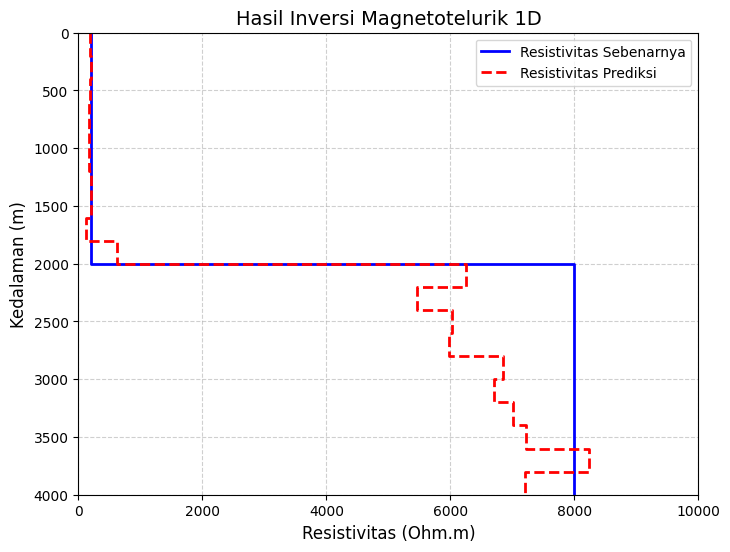

In [ ]:
plot_model_compare(resis_true, ketebalan_true, resis_predict, ketebalan_predict, total_depth)

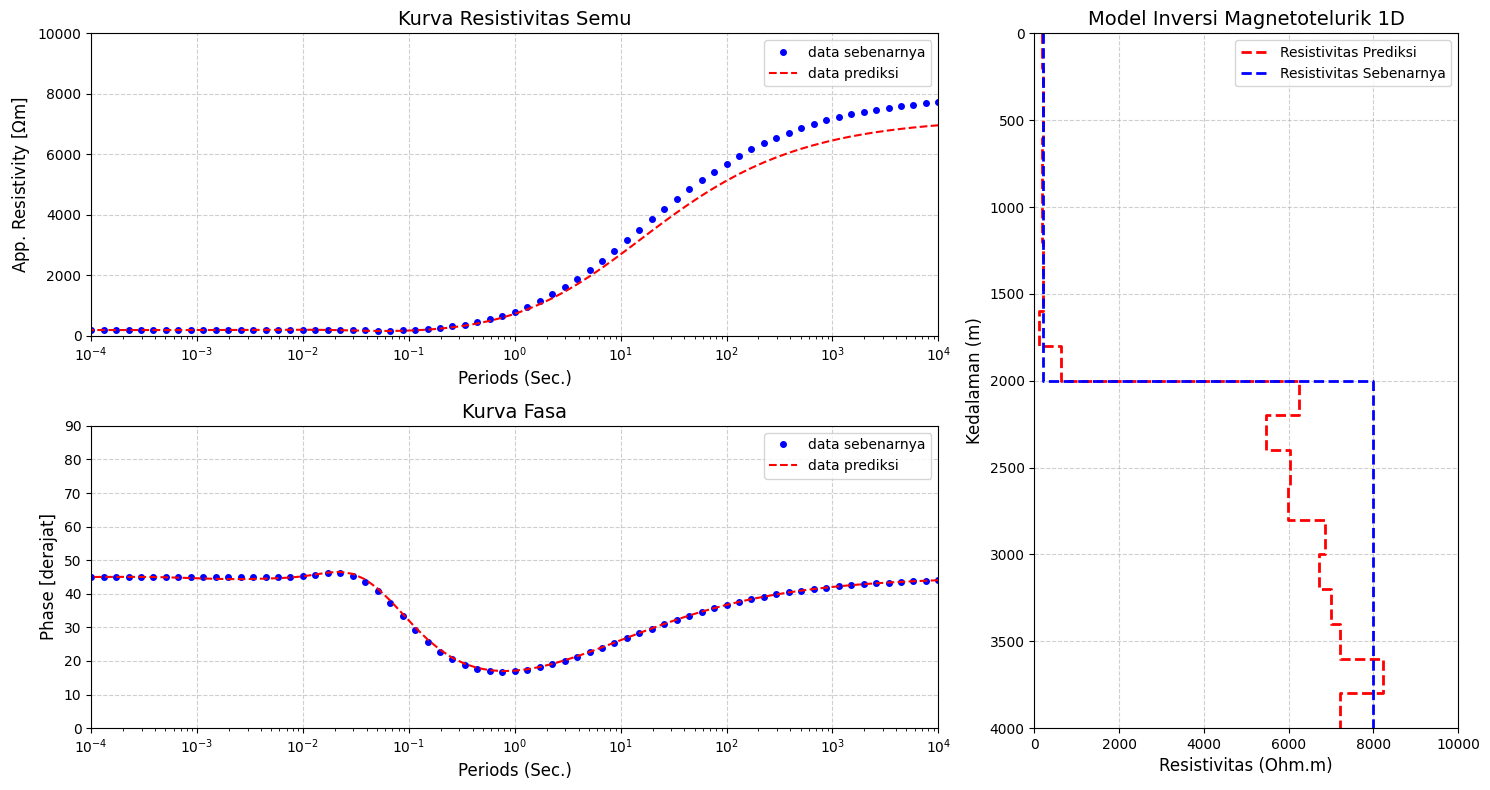

In [ ]:
plot_MT_compare(resis_true, ketebalan_true, resis_predict, ketebalan_predict, period, fasa, resistivitas_semu, fasa_predict,resistivitas_semu_predict, total_depth)

### Error

In [ ]:
measure_MSE(resistivitas_semu, fasa, resistivitas_semu_predict, fasa_predict)

MSE Resistivitas Semu: 153060.62
MSE Fasa: 0.10


In [ ]:
measure_MAPE(resistivitas_semu, fasa, resistivitas_semu_predict, fasa_predict)

MAPE resistivitas semu: 8.39%
MAPE fasa: 0.09%


[Interpolated] MSE model resistivitas: 1146185.0031
[Interpolated] MAPE model resistivitas: 23.91%


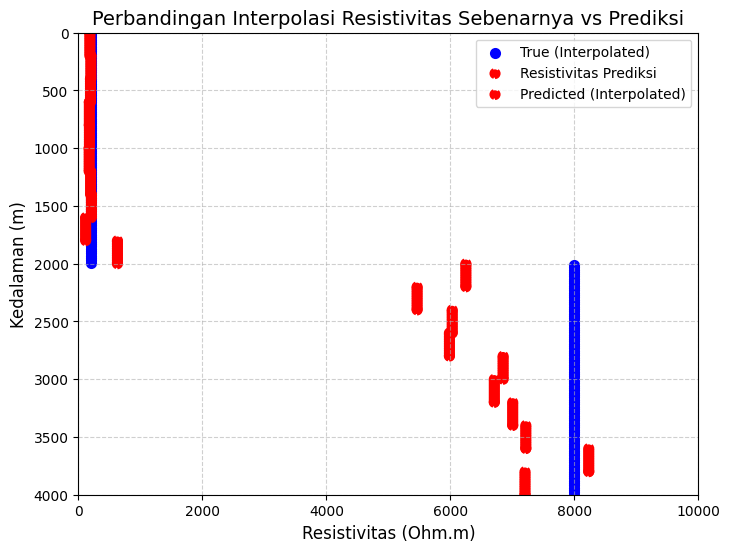

In [ ]:
measure_interpolated_resistivities(resis_true, ketebalan_true, resis_predict, ketebalan_predict, total_depth)

## Model Bumi 2 lapis II

### Prediksi

In [ ]:
# Forward modelling untuk data input
resis_true= np.array([9000,200])
ketebalan_true = np.array([2000])
frequencies = np.array(np.logspace(-4,4, num=69))
period = 1/frequencies
resistivitas_semu, fasa = forward_modelling(resis_true, ketebalan_true, frequencies)

resistivitas_semu = np.array([resistivitas_semu])
fasa = np.array([fasa])

#Reshape sebelum normalisasi
resistivitas_semu = resistivitas_semu[0].reshape(1, X_input_res.shape[1]) # Corrected reshape syntax
fasa = fasa.reshape(1, X_input_phase.shape[1])

#Logaritmik
resistivitas_semu_log = np.log10(resistivitas_semu)
fasa_log = np.log10(fasa)

# Normalisasi data input
resistivitas_semu_normalized = input_res_scaler.transform(resistivitas_semu_log)
fasa_normalized = input_phase_scaler.transform(fasa_log)

# Reshape jika perlu (misalnya, untuk input CNN)
resistivitas_semu_normalized = resistivitas_semu_normalized.reshape(1, X_input_res.shape[1], 1)
fasa_normalized = fasa_normalized.reshape(1, X_input_phase.shape[1], 1)

# Prediksi
predictions = model.predict([resistivitas_semu_normalized, fasa_normalized])

# Denormalisasi hasil prediksi, apply to the predictions, not hasil
predictions_denormalized = output_model_scaler.inverse_transform(predictions)
predictions_denormalized = np.power(10, predictions_denormalized)

# Accessing the values from predictions_denormalized
resis_predict = predictions_denormalized[0]
ketebalan_predict = np.full(jumlah_layer-1,layer_thickness)#Access elements from index 4 onwards

#Forward Modelling from prediction model
resistivitas_semu_predict, fasa_predict = forward_modelling(resis_predict, ketebalan_predict, frequencies)

resistivitas_semu_predict = np.array([resistivitas_semu_predict])
fasa_predict = np.array([fasa_predict])


#print(hasil) #No need to print hasil as it's not used

print("Nilai Resis_True", resis_true)
print("Nilai ketebalan_True",ketebalan_true)
print("Nilai resis_predict",resis_predict)
print("Nilai ketebalan_predict",ketebalan_predict)

1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 51ms/step
Nilai Resis_True [9000  200]
Nilai ketebalan_True [2000]
Nilai resis_predict [8320.662   9115.419   8839.348   8310.587   8838.173   8945.264
 9619.429   8631.716   7559.3755  9473.393    190.51907  184.50865
  246.53311  195.77107  181.53864  233.87433  189.25792  137.357
  158.40096  181.28926]
Nilai ketebalan_predict [200. 200. 200. 200. 200. 200. 200. 200. 200. 200. 200. 200. 200. 200.
 200. 200. 200. 200. 200.]


### Grafik

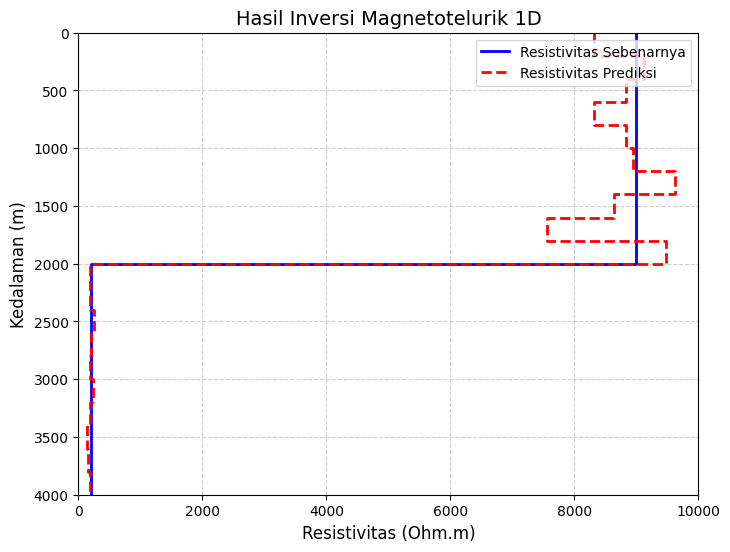

In [ ]:
plot_model_compare(resis_true, ketebalan_true, resis_predict, ketebalan_predict, total_depth)

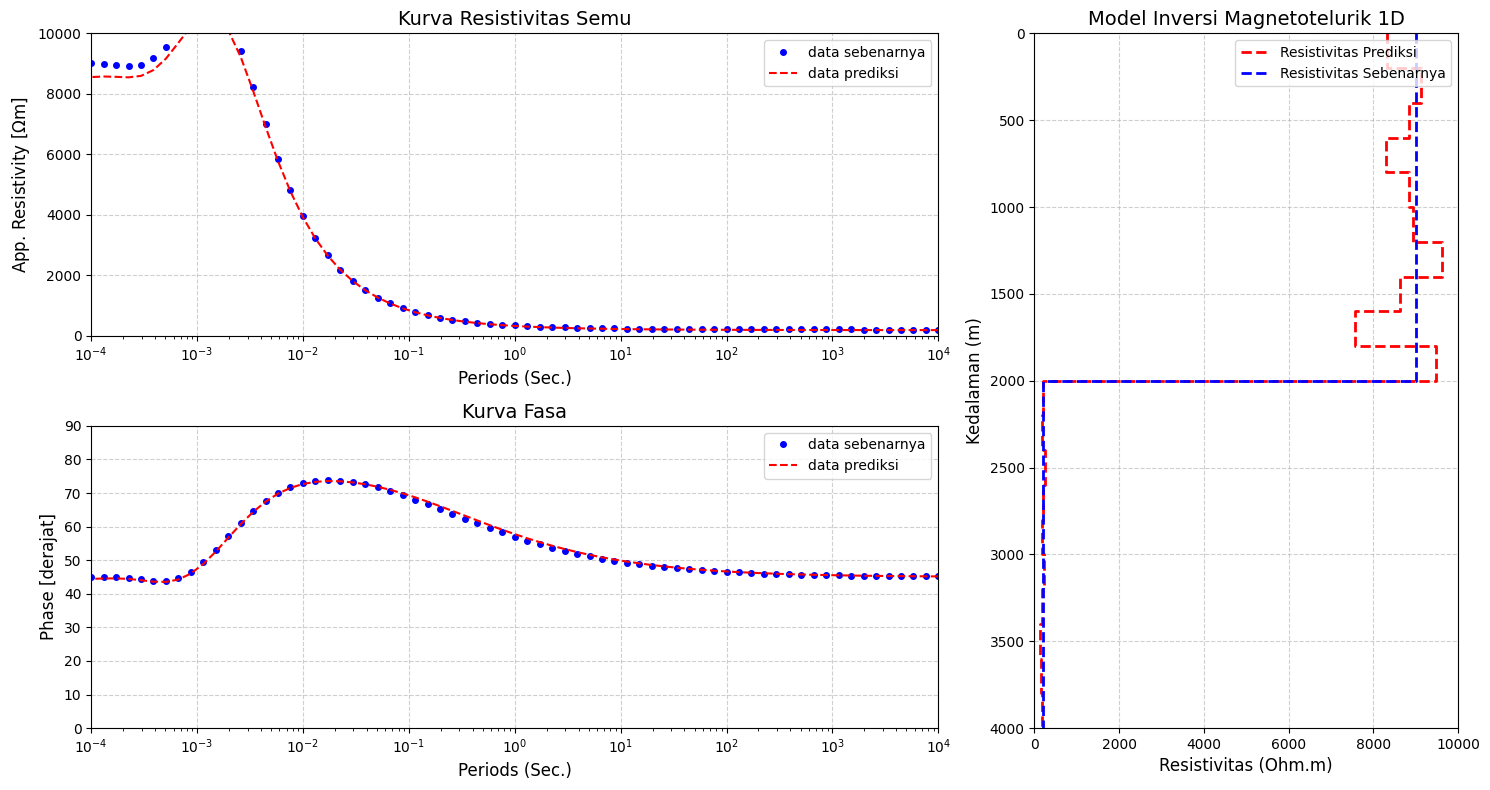

In [ ]:
plot_MT_compare(resis_true, ketebalan_true, resis_predict, ketebalan_predict, period, fasa, resistivitas_semu, fasa_predict,resistivitas_semu_predict, total_depth)

### Error

In [ ]:
measure_MSE(resistivitas_semu, fasa, resistivitas_semu_predict, fasa_predict)

MSE Resistivitas Semu: 26349.45
MSE Fasa: 0.18


In [ ]:
measure_MAPE(resistivitas_semu, fasa, resistivitas_semu_predict, fasa_predict)

MAPE resistivitas semu: 5.54%
MAPE fasa: 0.06%


[Interpolated] MSE model resistivitas: 191702.5671
[Interpolated] MAPE model resistivitas: 9.19%


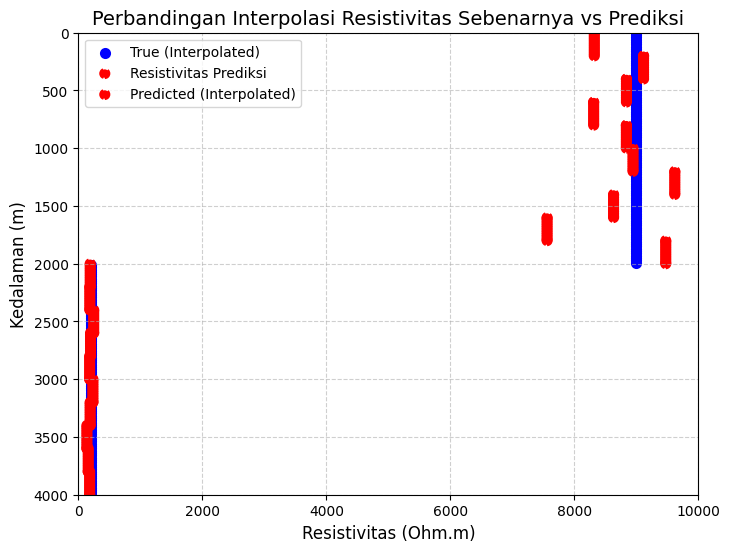

In [ ]:
measure_interpolated_resistivities(resis_true, ketebalan_true, resis_predict, ketebalan_predict, total_depth)

## Model Bumi 2 Lapis III

### Prediksi

In [ ]:
# Forward modelling untuk data input
resis_true= np.array([7000, 5000])
ketebalan_true = np.array([1000])
frequencies = np.array(np.logspace(-4,4, num=69))
period = 1/frequencies
resistivitas_semu, fasa = forward_modelling(resis_true, ketebalan_true, frequencies)

resistivitas_semu = np.array([resistivitas_semu])
fasa = np.array([fasa])

#Reshape sebelum normalisasi
resistivitas_semu = resistivitas_semu[0].reshape(1, X_input_res.shape[1]) # Corrected reshape syntax
fasa = fasa.reshape(1, X_input_phase.shape[1])

#Logaritmik
resistivitas_semu_log = np.log10(resistivitas_semu)
fasa_log = np.log10(fasa)

# Normalisasi data input
resistivitas_semu_normalized = input_res_scaler.transform(resistivitas_semu_log)
fasa_normalized = input_phase_scaler.transform(fasa_log)

# Reshape jika perlu (misalnya, untuk input CNN)
resistivitas_semu_normalized = resistivitas_semu_normalized.reshape(1, X_input_res.shape[1], 1)
fasa_normalized = fasa_normalized.reshape(1, X_input_phase.shape[1], 1)

# Prediksi
predictions = model.predict([resistivitas_semu_normalized, fasa_normalized])

# Denormalisasi hasil prediksi, apply to the predictions, not hasil
predictions_denormalized = output_model_scaler.inverse_transform(predictions)
predictions_denormalized = np.power(10, predictions_denormalized)

# Accessing the values from predictions_denormalized
resis_predict = predictions_denormalized[0]
ketebalan_predict = np.full(jumlah_layer-1,layer_thickness)#Access elements from index 4 onwards

#Forward Modelling from prediction model
resistivitas_semu_predict, fasa_predict = forward_modelling(resis_predict, ketebalan_predict, frequencies)

resistivitas_semu_predict = np.array([resistivitas_semu_predict])
fasa_predict = np.array([fasa_predict])


#print(hasil) #No need to print hasil as it's not used

print("Nilai Resis_True", resis_true)
print("Nilai ketebalan_True",ketebalan_true)
print("Nilai resis_predict",resis_predict)
print("Nilai ketebalan_predict",ketebalan_predict)

1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 45ms/step
Nilai Resis_True [7000 5000]
Nilai ketebalan_True [1000]
Nilai resis_predict [6923.9736 7280.2593 6912.739  6876.173  6956.2666 5441.307  4769.3574
 4912.5215 5064.799  5206.654  4925.897  4966.145  5033.2    4967.964
 5189.791  4842.3345 5060.8574 4746.917  4717.483  4960.6304]
Nilai ketebalan_predict [200. 200. 200. 200. 200. 200. 200. 200. 200. 200. 200. 200. 200. 200.
 200. 200. 200. 200. 200.]


### Grafik

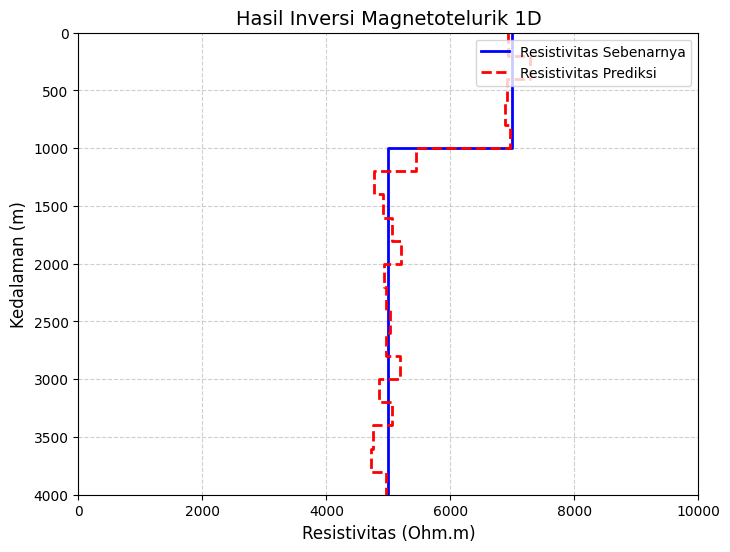

In [ ]:
plot_model_compare(resis_true, ketebalan_true, resis_predict, ketebalan_predict, total_depth)

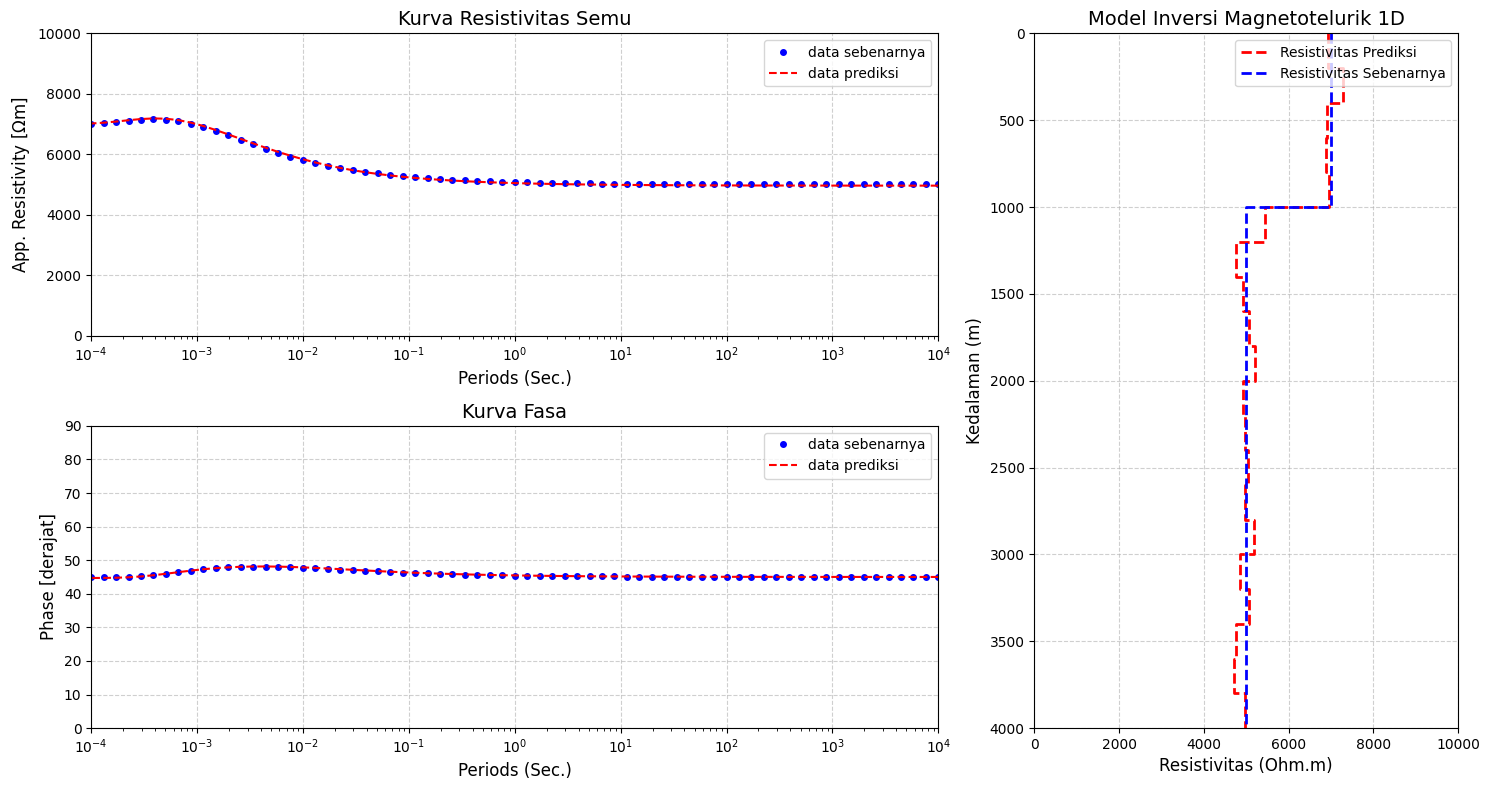

In [ ]:
plot_MT_compare(resis_true, ketebalan_true, resis_predict, ketebalan_predict, period, fasa, resistivitas_semu, fasa_predict,resistivitas_semu_predict, total_depth)

### Error

In [ ]:
measure_MSE(resistivitas_semu, fasa, resistivitas_semu_predict, fasa_predict)

MSE Resistivitas Semu: 1090.50
MSE Fasa: 0.00


In [ ]:
measure_MAPE(resistivitas_semu, fasa, resistivitas_semu_predict, fasa_predict)

MAPE resistivitas semu: 0.59%
MAPE fasa: 0.00%


[Interpolated] MSE model resistivitas: 31522.8132
[Interpolated] MAPE model resistivitas: 2.62%


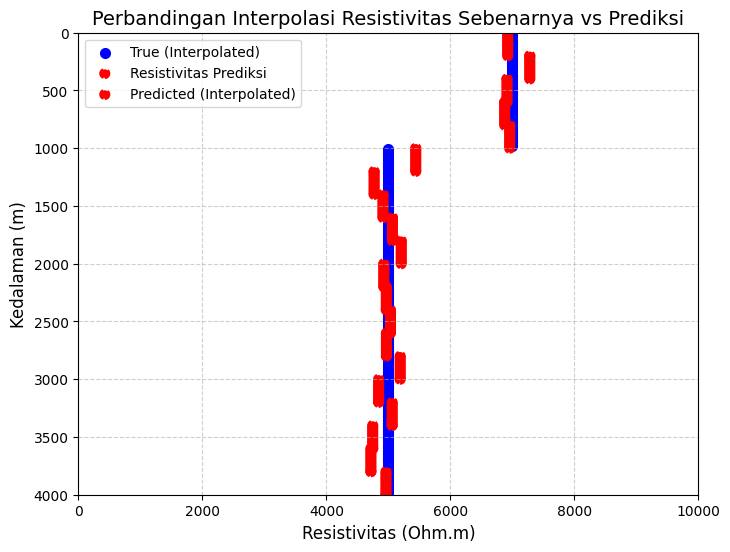

In [ ]:
measure_interpolated_resistivities(resis_true, ketebalan_true, resis_predict, ketebalan_predict, total_depth )

## Model Bumi 2 Lapis IV




### Prediksi

In [ ]:
# Forward modelling untuk data input
resis_true= np.array([7000, 5000])
ketebalan_true = np.array([3000])
frequencies = np.array(np.logspace(-4,4, num=69))
period = 1/frequencies
resistivitas_semu, fasa = forward_modelling(resis_true, ketebalan_true, frequencies)

resistivitas_semu = np.array([resistivitas_semu])
fasa = np.array([fasa])

#Reshape sebelum normalisasi
resistivitas_semu = resistivitas_semu[0].reshape(1, X_input_res.shape[1]) # Corrected reshape syntax
fasa = fasa.reshape(1, X_input_phase.shape[1])

#Logaritmik
resistivitas_semu_log = np.log10(resistivitas_semu)
fasa_log = np.log10(fasa)

# Normalisasi data input
resistivitas_semu_normalized = input_res_scaler.transform(resistivitas_semu_log)
fasa_normalized = input_phase_scaler.transform(fasa_log)

# Reshape jika perlu (misalnya, untuk input CNN)
resistivitas_semu_normalized = resistivitas_semu_normalized.reshape(1, X_input_res.shape[1], 1)
fasa_normalized = fasa_normalized.reshape(1, X_input_phase.shape[1], 1)

# Prediksi
predictions = model.predict([resistivitas_semu_normalized, fasa_normalized])

# Denormalisasi hasil prediksi, apply to the predictions, not hasil
predictions_denormalized = output_model_scaler.inverse_transform(predictions)
predictions_denormalized = np.power(10, predictions_denormalized)

# Accessing the values from predictions_denormalized
resis_predict = predictions_denormalized[0]
ketebalan_predict = np.full(jumlah_layer-1,layer_thickness)#Access elements from index 4 onwards

#Forward Modelling from prediction model
resistivitas_semu_predict, fasa_predict = forward_modelling(resis_predict, ketebalan_predict, frequencies)

resistivitas_semu_predict = np.array([resistivitas_semu_predict])
fasa_predict = np.array([fasa_predict])


#print(hasil) #No need to print hasil as it's not used

print("Nilai Resis_True", resis_true)
print("Nilai ketebalan_True",ketebalan_true)
print("Nilai resis_predict",resis_predict)
print("Nilai ketebalan_predict",ketebalan_predict)

1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 41ms/step
Nilai Resis_True [7000 5000]
Nilai ketebalan_True [3000]
Nilai resis_predict [6900.727  7208.7046 6804.203  6788.093  6891.3384 7197.502  6997.74
 6843.6543 6754.7964 6909.609  6928.3765 7240.529  7063.447  6578.154
 6565.62   5382.0146 5189.23   4569.977  4702.9507 4919.017 ]
Nilai ketebalan_predict [200. 200. 200. 200. 200. 200. 200. 200. 200. 200. 200. 200. 200. 200.
 200. 200. 200. 200. 200.]


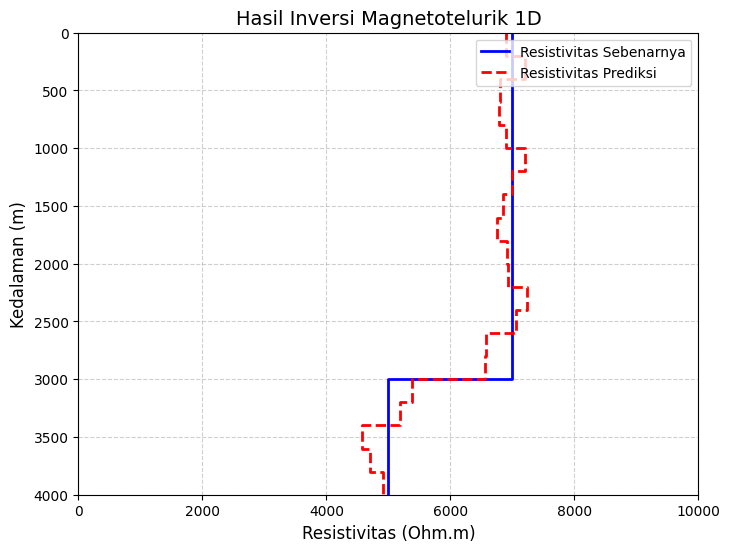

In [ ]:
plot_model_compare(resis_true, ketebalan_true, resis_predict, ketebalan_predict, total_depth)

### Grafik

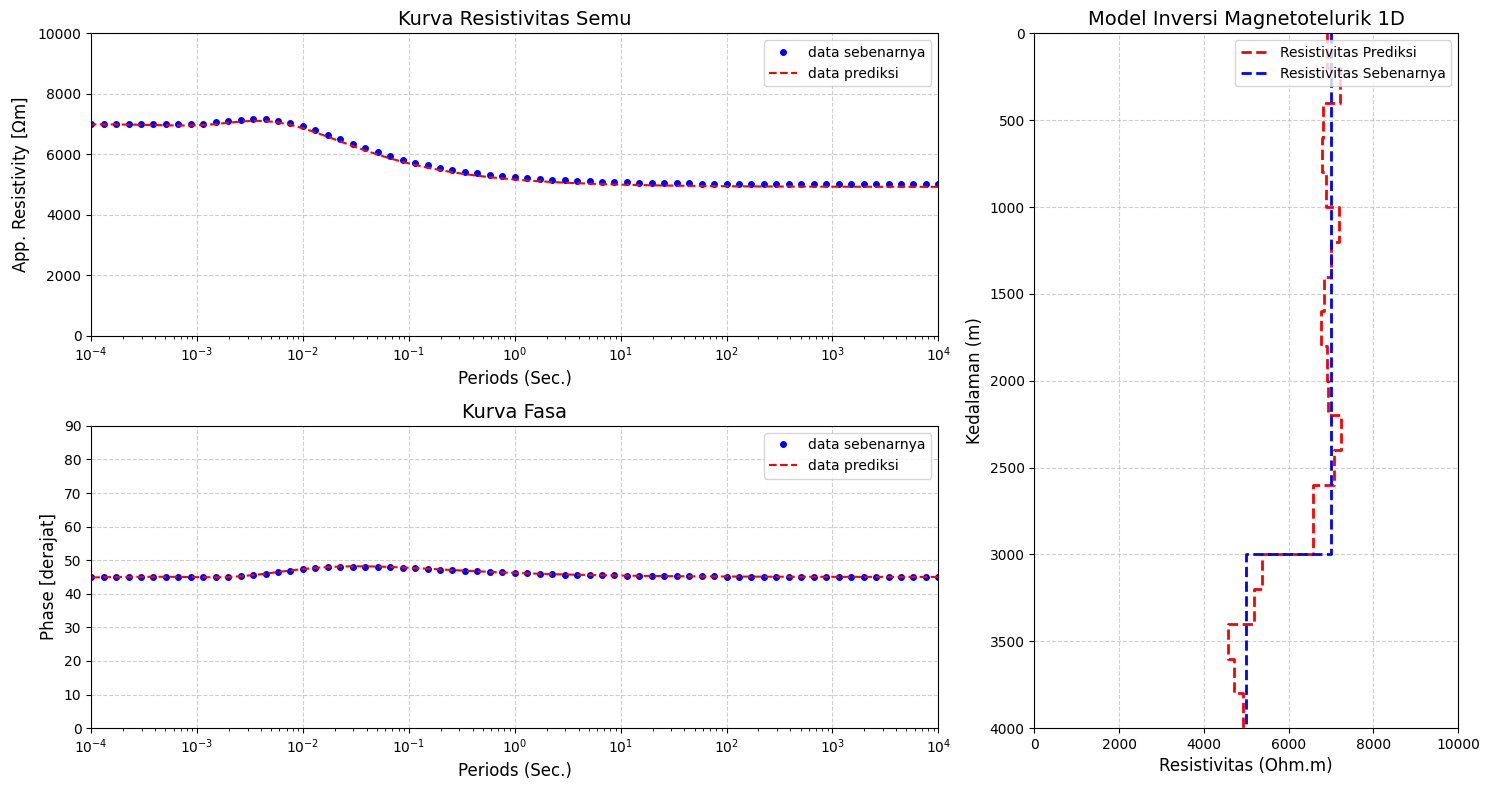

In [ ]:
plot_MT_compare(resis_true, ketebalan_true, resis_predict, ketebalan_predict, period, fasa, resistivitas_semu, fasa_predict,resistivitas_semu_predict, total_depth)

### Error

In [ ]:
measure_MSE(resistivitas_semu, fasa, resistivitas_semu_predict, fasa_predict)

MSE Resistivitas Semu: 5073.23
MSE Fasa: 0.00


In [ ]:
measure_MAPE(resistivitas_semu, fasa, resistivitas_semu_predict, fasa_predict)

MAPE resistivitas semu: 1.25%
MAPE fasa: 0.00%


[Interpolated] MSE model resistivitas: 58766.0850
[Interpolated] MAPE model resistivitas: 3.34%


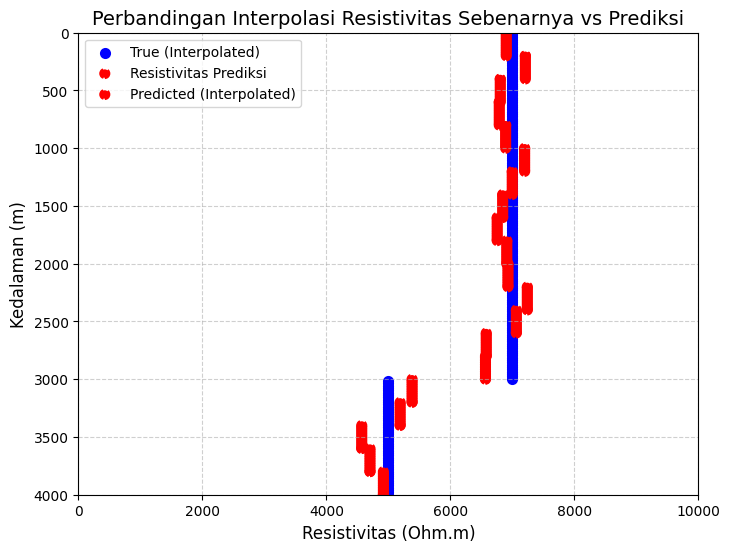

In [ ]:
measure_interpolated_resistivities(resis_true, ketebalan_true, resis_predict, ketebalan_predict, total_depth)


#Prediksi Bumi 3 lapis

## Model Bumi 3 lapis I

### Prediksi

In [ ]:
# Forward modelling untuk data input
resis_true= np.array([8000,200, 1000])
ketebalan_true = np.array([800, 1500])
frequencies = np.array(np.logspace(-4,4, num=69))
period = 1/frequencies
resistivitas_semu, fasa = forward_modelling(resis_true, ketebalan_true, frequencies)

resistivitas_semu = np.array([resistivitas_semu])
fasa = np.array([fasa])

#Reshape sebelum normalisasi
resistivitas_semu = resistivitas_semu[0].reshape(1, X_input_res.shape[1]) # Corrected reshape syntax
fasa = fasa.reshape(1, X_input_phase.shape[1])

resistivitas_semu = np.array([resistivitas_semu])
fasa = np.array([fasa])

#Reshape sebelum normalisasi
resistivitas_semu = resistivitas_semu[0].reshape(1, X_input_res.shape[1]) # Corrected reshape syntax
fasa = fasa.reshape(1, X_input_phase.shape[1])

#Logaritmik
resistivitas_semu_log = np.log10(resistivitas_semu)
fasa_log = np.log10(fasa)

# Normalisasi data input
resistivitas_semu_normalized = input_res_scaler.transform(resistivitas_semu_log)
fasa_normalized = input_phase_scaler.transform(fasa_log)

# Reshape jika perlu (misalnya, untuk input CNN)
resistivitas_semu_normalized = resistivitas_semu_normalized.reshape(1, X_input_res.shape[1], 1)
fasa_normalized = fasa_normalized.reshape(1, X_input_phase.shape[1], 1)

# Prediksi
predictions = model.predict([resistivitas_semu_normalized, fasa_normalized])

# Denormalisasi hasil prediksi, apply to the predictions, not hasil
predictions_denormalized = output_model_scaler.inverse_transform(predictions)
predictions_denormalized = np.power(10, predictions_denormalized)

# Accessing the values from predictions_denormalized
resis_predict = predictions_denormalized[0]
ketebalan_predict = np.full(jumlah_layer-1,layer_thickness)#Access elements from index 4 onwards

#Forward Modelling from prediction model
resistivitas_semu_predict, fasa_predict = forward_modelling(resis_predict, ketebalan_predict, frequencies)

resistivitas_semu_predict = np.array([resistivitas_semu_predict])
fasa_predict = np.array([fasa_predict])


#print(hasil) #No need to print hasil as it's not used

print("Nilai Resis_True", resis_true)
print("Nilai ketebalan_True",ketebalan_true)
print("Nilai resis_predict",resis_predict)
print("Nilai ketebalan_predict",ketebalan_predict)

1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 46ms/step
Nilai Resis_True [8000  200 1000]
Nilai ketebalan_True [ 800 1500]
Nilai resis_predict [8478.201   9650.2705  7174.8496  7347.783    199.61441  222.66426
  196.20015  260.87823  228.77579  198.60027  263.59842  438.94397
 1183.2363  1246.0405  1100.8932  1288.8704  1438.2291  1382.1978
 1113.1791  1024.1196 ]
Nilai ketebalan_predict [200. 200. 200. 200. 200. 200. 200. 200. 200. 200. 200. 200. 200. 200.
 200. 200. 200. 200. 200.]


### Grafik

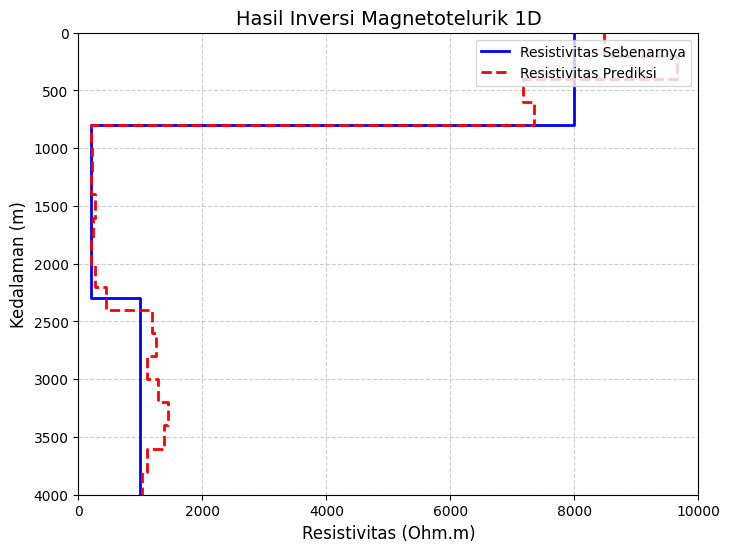

In [ ]:
plot_model_compare(resis_true, ketebalan_true, resis_predict, ketebalan_predict, total_depth)

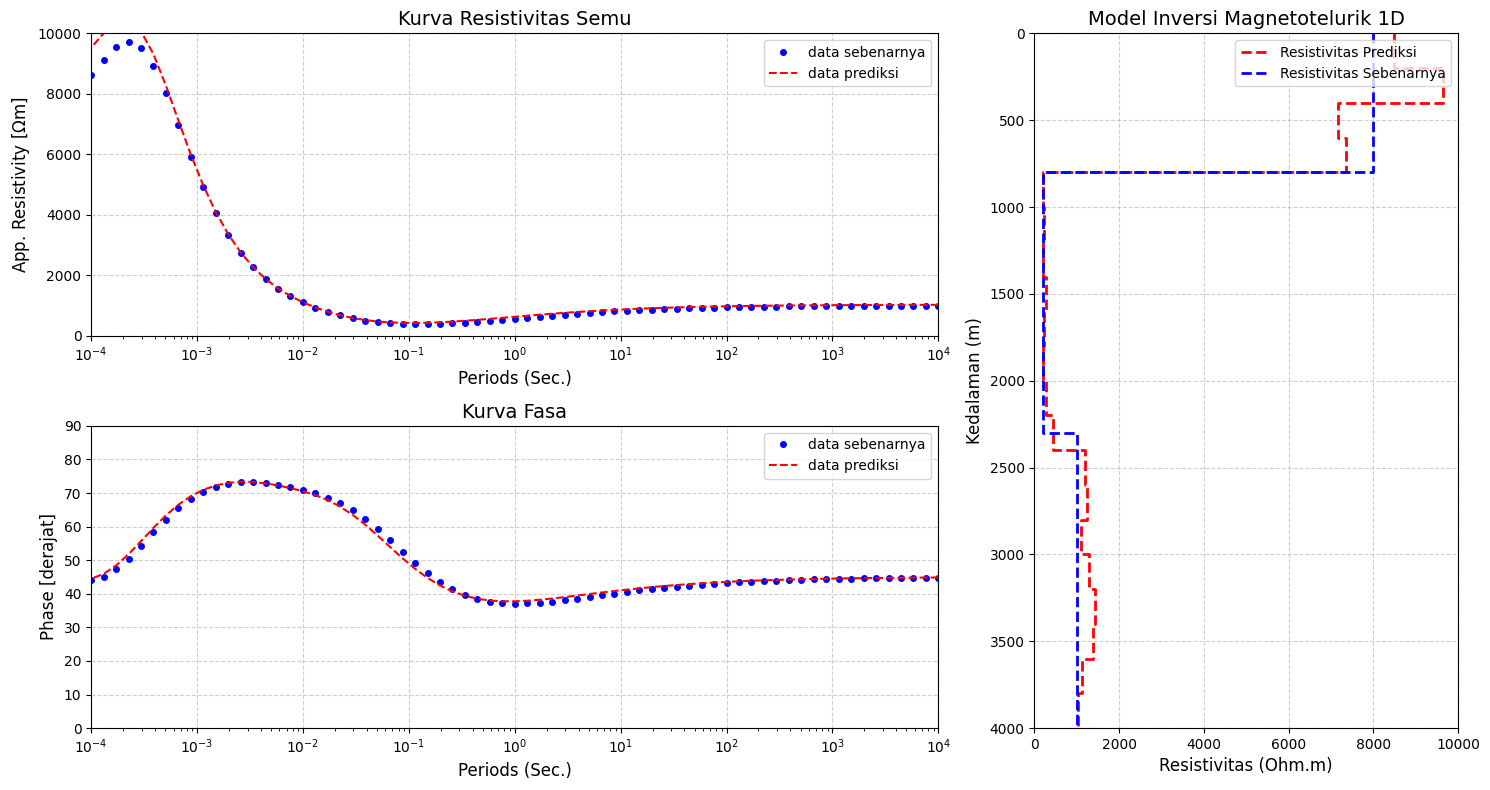

In [ ]:
plot_MT_compare(resis_true, ketebalan_true, resis_predict, ketebalan_predict, period, fasa, resistivitas_semu, fasa_predict,resistivitas_semu_predict, total_depth)


### Error

In [ ]:
measure_MAPE(resistivitas_semu, fasa, resistivitas_semu_predict, fasa_predict)

MAPE resistivitas semu: 5.26%
MAPE fasa: 0.09%


In [ ]:
measure_MSE(resistivitas_semu, fasa, resistivitas_semu_predict, fasa_predict)

MSE Resistivitas Semu: 49056.27
MSE Fasa: 0.68


[Interpolated] MSE model resistivitas: 239631.2708
[Interpolated] MAPE model resistivitas: 20.06%


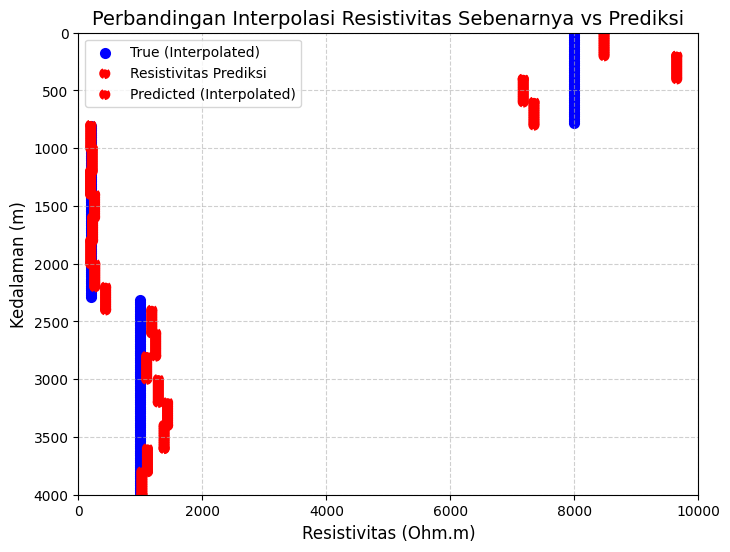

In [ ]:
measure_interpolated_resistivities(resis_true, ketebalan_true, resis_predict, ketebalan_predict, total_depth)


## Model Bumi 3 lapis II

### Prediksi

In [ ]:
# Forward modelling untuk data input
resis_true= np.array([200,8000,100])
ketebalan_true = np.array([800, 1500])
frequencies = np.array(np.logspace(-4,4, num=69))
period = 1/frequencies
resistivitas_semu, fasa = forward_modelling(resis_true, ketebalan_true, frequencies)

resistivitas_semu = np.array([resistivitas_semu])
fasa = np.array([fasa])

#Reshape sebelum normalisasi
resistivitas_semu = resistivitas_semu[0].reshape(1, X_input_res.shape[1]) # Corrected reshape syntax
fasa = fasa.reshape(1, X_input_phase.shape[1])

#Logaritmik
resistivitas_semu_log = np.log10(resistivitas_semu)
fasa_log = np.log10(fasa)

# Normalisasi data input
resistivitas_semu_normalized = input_res_scaler.transform(resistivitas_semu_log)
fasa_normalized = input_phase_scaler.transform(fasa_log)

# Reshape jika perlu (misalnya, untuk input CNN)
resistivitas_semu_normalized = resistivitas_semu_normalized.reshape(1, X_input_res.shape[1], 1)
fasa_normalized = fasa_normalized.reshape(1, X_input_phase.shape[1], 1)

# Prediksi
predictions = model.predict([resistivitas_semu_normalized, fasa_normalized])

# Denormalisasi hasil prediksi, apply to the predictions, not hasil
predictions_denormalized = output_model_scaler.inverse_transform(predictions)
predictions_denormalized = np.power(10, predictions_denormalized)

# Accessing the values from predictions_denormalized
resis_predict = predictions_denormalized[0]
ketebalan_predict = np.full(jumlah_layer-1,layer_thickness)#Access elements from index 4 onwards

#Forward Modelling from prediction model
resistivitas_semu_predict, fasa_predict = forward_modelling(resis_predict, ketebalan_predict, frequencies)

resistivitas_semu_predict = np.array([resistivitas_semu_predict])
fasa_predict = np.array([fasa_predict])


#print(hasil) #No need to print hasil as it's not used

print("Nilai Resis_True", resis_true)
print("Nilai ketebalan_True",ketebalan_true)
print("Nilai resis_predict",resis_predict)
print("Nilai ketebalan_predict",ketebalan_predict)

1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 43ms/step
Nilai Resis_True [ 200 8000  100]
Nilai ketebalan_True [ 800 1500]
Nilai resis_predict [ 197.86938  243.30342  164.21951  983.679   4403.535   5620.8794
 5842.0957  4123.8     4386.226   5056.989   1877.6366   841.78455
  253.14351  145.90306   66.5977   113.72651   84.54217  184.51706
  133.80548   97.29724]
Nilai ketebalan_predict [200. 200. 200. 200. 200. 200. 200. 200. 200. 200. 200. 200. 200. 200.
 200. 200. 200. 200. 200.]


### Grafik

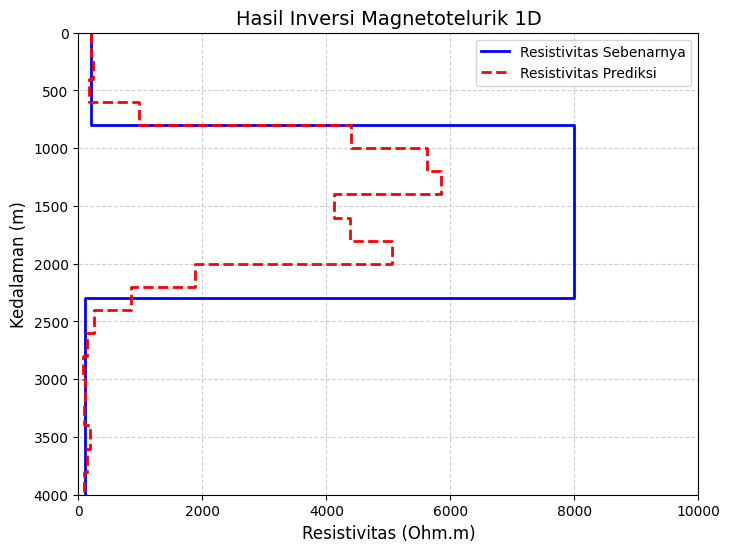

In [ ]:
plot_model_compare(resis_true, ketebalan_true, resis_predict, ketebalan_predict, total_depth)

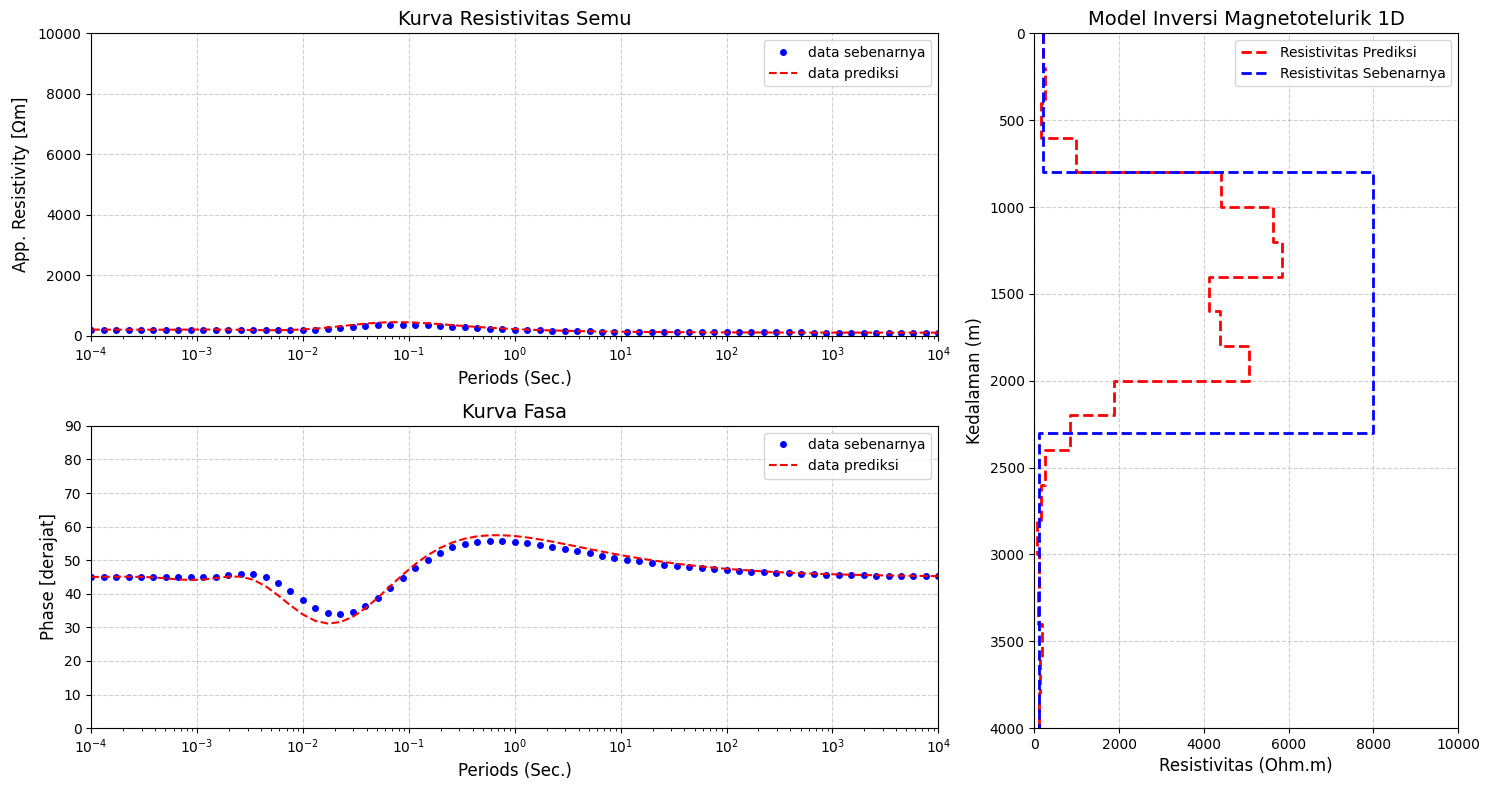

In [ ]:
plot_MT_compare(resis_true, ketebalan_true, resis_predict, ketebalan_predict, period, fasa, resistivitas_semu, fasa_predict,resistivitas_semu_predict, total_depth)

### Error

In [ ]:
measure_MSE(resistivitas_semu, fasa, resistivitas_semu_predict, fasa_predict)

MSE Resistivitas Semu: 897.22
MSE Fasa: 2.02


In [ ]:
measure_MAPE(resistivitas_semu, fasa, resistivitas_semu_predict, fasa_predict)

MAPE resistivitas semu: 6.60%
MAPE fasa: 0.55%


[Interpolated] MSE model resistivitas: 6201405.9693
[Interpolated] MAPE model resistivitas: 76.97%


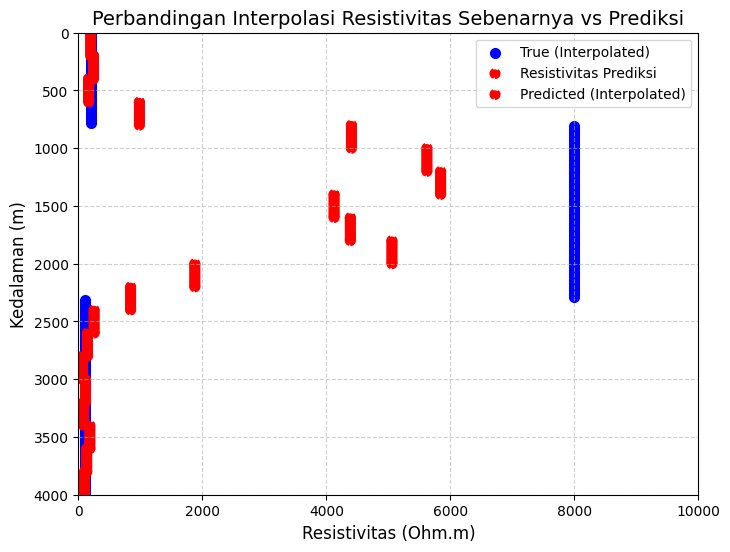

In [ ]:
measure_interpolated_resistivities(resis_true, ketebalan_true, resis_predict, ketebalan_predict, total_depth)

## Model Bumi 3 lapis III

### Prediksi

In [ ]:
# Forward modelling untuk data input
resis_true= np.array([1000,200, 8000])
ketebalan_true = np.array([800, 1500])
frequencies = np.array(np.logspace(-4,4, num=69))
period = 1/frequencies
resistivitas_semu, fasa = forward_modelling(resis_true, ketebalan_true, frequencies)

resistivitas_semu = np.array([resistivitas_semu])
fasa = np.array([fasa])

#Reshape sebelum normalisasi
resistivitas_semu = resistivitas_semu[0].reshape(1, X_input_res.shape[1]) # Corrected reshape syntax
fasa = fasa.reshape(1, X_input_phase.shape[1])

#Logaritmik
resistivitas_semu_log = np.log10(resistivitas_semu)
fasa_log = np.log10(fasa)

# Normalisasi data input
resistivitas_semu_normalized = input_res_scaler.transform(resistivitas_semu_log)
fasa_normalized = input_phase_scaler.transform(fasa_log)

# Reshape jika perlu (misalnya, untuk input CNN)
resistivitas_semu_normalized = resistivitas_semu_normalized.reshape(1, X_input_res.shape[1], 1)
fasa_normalized = fasa_normalized.reshape(1, X_input_phase.shape[1], 1)

# Prediksi
predictions = model.predict([resistivitas_semu_normalized, fasa_normalized])

# Denormalisasi hasil prediksi, apply to the predictions, not hasil
predictions_denormalized = output_model_scaler.inverse_transform(predictions)
predictions_denormalized = np.power(10, predictions_denormalized)

# Accessing the values from predictions_denormalized
resis_predict = predictions_denormalized[0]
ketebalan_predict = np.full(jumlah_layer-1,layer_thickness)#Access elements from index 4 onwards

#Forward Modelling from prediction model
resistivitas_semu_predict, fasa_predict = forward_modelling(resis_predict, ketebalan_predict, frequencies)

resistivitas_semu_predict = np.array([resistivitas_semu_predict])
fasa_predict = np.array([fasa_predict])


#print(hasil) #No need to print hasil as it's not used

print("Nilai Resis_True", resis_true)
print("Nilai ketebalan_True",ketebalan_true)
print("Nilai resis_predict",resis_predict)
print("Nilai ketebalan_predict",ketebalan_predict)

1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 45ms/step
Nilai Resis_True [1000  200 8000]
Nilai ketebalan_True [ 800 1500]
Nilai resis_predict [1014.6398   968.5794   926.26526 1181.906    136.04886  163.68857
  231.45226  214.03046  191.28969  224.60526  179.48349 1463.9432
 7751.452   6973.8823  7339.1562  7566.8613  8594.522   7724.8975
 7880.374   6695.217  ]
Nilai ketebalan_predict [200. 200. 200. 200. 200. 200. 200. 200. 200. 200. 200. 200. 200. 200.
 200. 200. 200. 200. 200.]


### Grafik

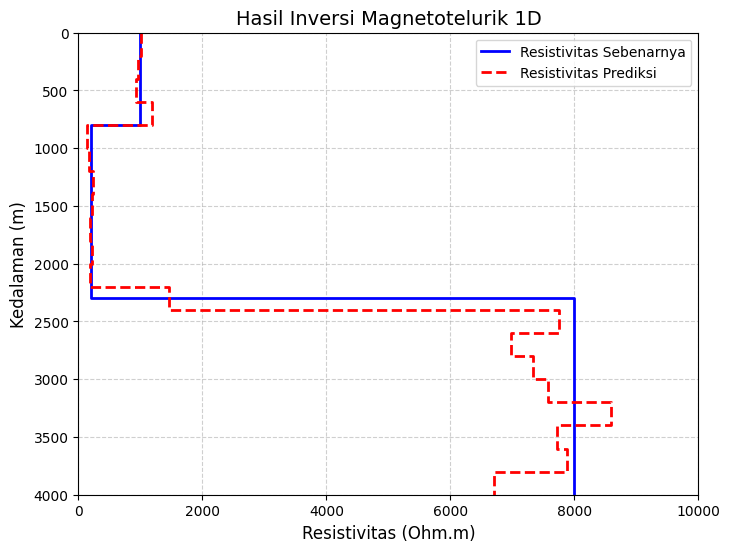

In [ ]:
plot_model_compare(resis_true, ketebalan_true, resis_predict, ketebalan_predict, total_depth)

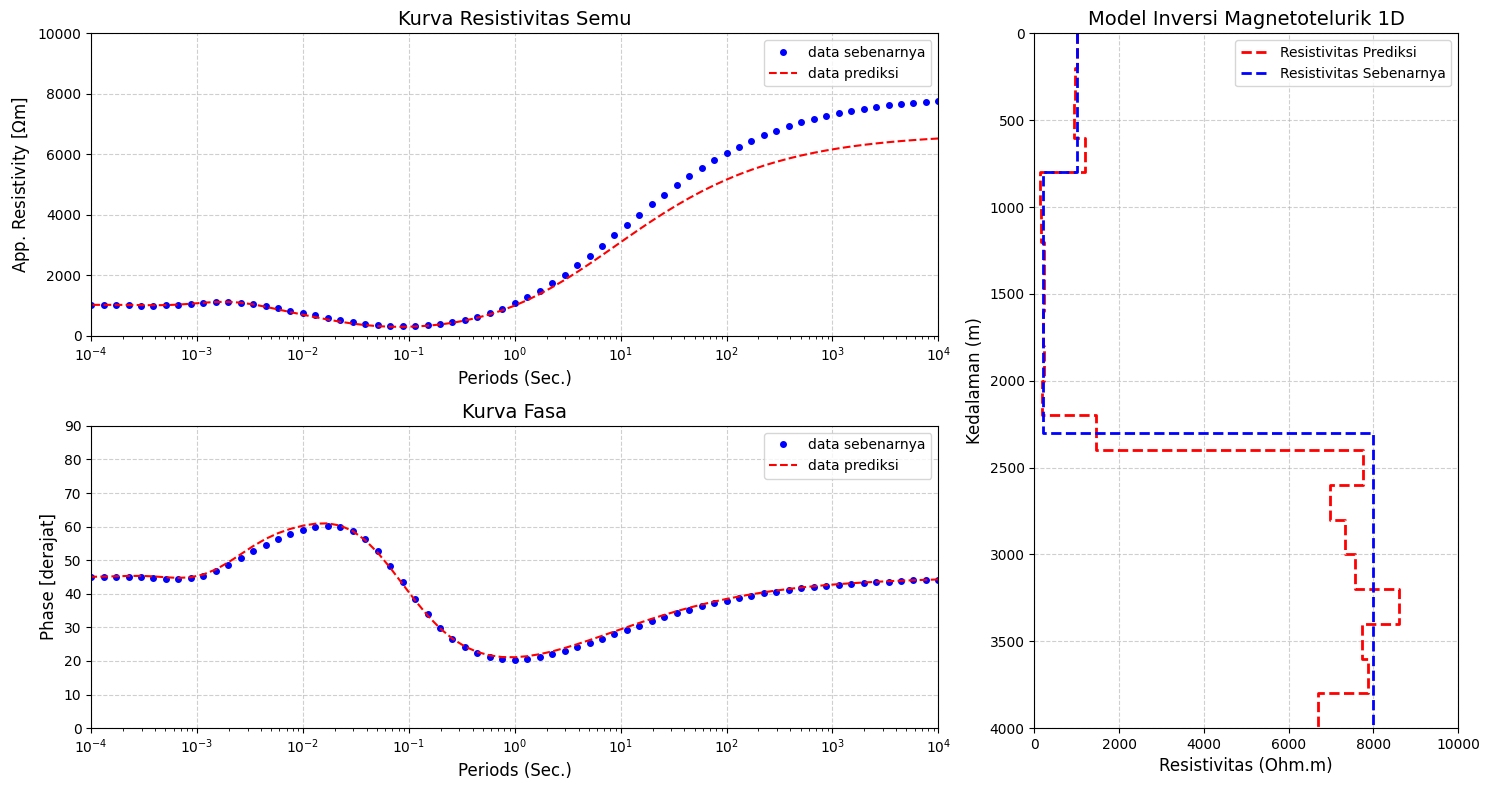

In [ ]:
plot_MT_compare(resis_true, ketebalan_true, resis_predict, ketebalan_predict, period, fasa, resistivitas_semu, fasa_predict,resistivitas_semu_predict, total_depth)

### Error

In [ ]:
measure_MSE(resistivitas_semu, fasa, resistivitas_semu_predict, fasa_predict)

MSE Resistivitas Semu: 384364.20
MSE Fasa: 0.46


In [ ]:
measure_MAPE(resistivitas_semu, fasa, resistivitas_semu_predict, fasa_predict)

MAPE resistivitas semu: 8.85%
MAPE fasa: 0.05%


[Interpolated] MSE model resistivitas: 1304557.2528
[Interpolated] MAPE model resistivitas: 27.25%


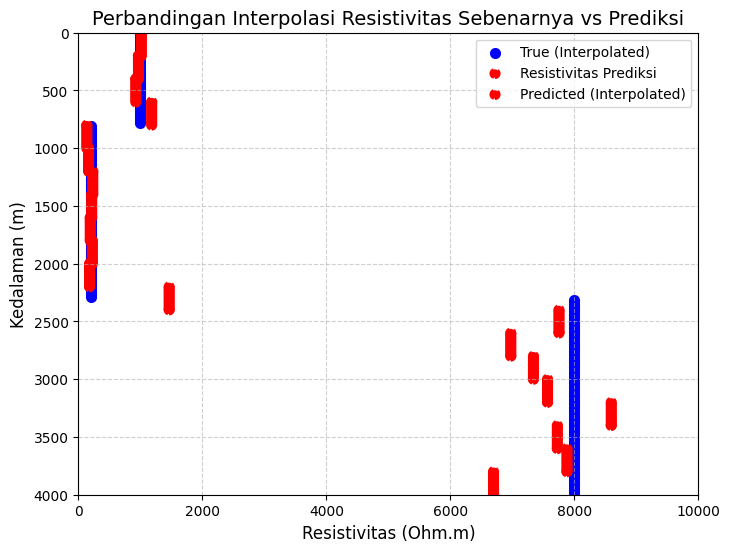

In [ ]:
measure_interpolated_resistivities(resis_true, ketebalan_true, resis_predict, ketebalan_predict, total_depth)


## Model Bumi 3 lapis IV

### Prediksi

In [ ]:
# Forward modelling untuk data input
resis_true= np.array([1000, 8000, 200 ])
ketebalan_true = np.array([800, 1500])
frequencies = np.array(np.logspace(-4,4, num=69))
period = 1/frequencies
resistivitas_semu, fasa = forward_modelling(resis_true, ketebalan_true, frequencies)

resistivitas_semu = np.array([resistivitas_semu])
fasa = np.array([fasa])

#Reshape sebelum normalisasi
resistivitas_semu = resistivitas_semu[0].reshape(1, X_input_res.shape[1]) # Corrected reshape syntax
fasa = fasa.reshape(1, X_input_phase.shape[1])

#Logaritmik
resistivitas_semu_log = np.log10(resistivitas_semu)
fasa_log = np.log10(fasa)

# Normalisasi data input
resistivitas_semu_normalized = input_res_scaler.transform(resistivitas_semu_log)
fasa_normalized = input_phase_scaler.transform(fasa_log)

# Reshape jika perlu (misalnya, untuk input CNN)
resistivitas_semu_normalized = resistivitas_semu_normalized.reshape(1, X_input_res.shape[1], 1)
fasa_normalized = fasa_normalized.reshape(1, X_input_phase.shape[1], 1)

# Prediksi
predictions = model.predict([resistivitas_semu_normalized, fasa_normalized])

# Denormalisasi hasil prediksi, apply to the predictions, not hasil
predictions_denormalized = output_model_scaler.inverse_transform(predictions)
predictions_denormalized = np.power(10, predictions_denormalized)

# Accessing the values from predictions_denormalized
resis_predict = predictions_denormalized[0]
ketebalan_predict = np.full(jumlah_layer-1,layer_thickness)#Access elements from index 4 onwards

#Forward Modelling from prediction model
resistivitas_semu_predict, fasa_predict = forward_modelling(resis_predict, ketebalan_predict, frequencies)

resistivitas_semu_predict = np.array([resistivitas_semu_predict])
fasa_predict = np.array([fasa_predict])


#print(hasil) #No need to print hasil as it's not used

print("Nilai Resis_True", resis_true)
print("Nilai ketebalan_True",ketebalan_true)
print("Nilai resis_predict",resis_predict)
print("Nilai ketebalan_predict",ketebalan_predict)

1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 47ms/step
Nilai Resis_True [1000 8000  200]
Nilai ketebalan_True [ 800 1500]
Nilai resis_predict [  942.8673    1102.1588    1038.1154     996.6689    7717.2637
  8363.913     8427.542     8580.003     7921.1104    8397.38
 10021.643     1721.1204      99.353424   353.1883     287.48666
   193.23036    130.39368    102.88374    199.61452    190.23627 ]
Nilai ketebalan_predict [200. 200. 200. 200. 200. 200. 200. 200. 200. 200. 200. 200. 200. 200.
 200. 200. 200. 200. 200.]


### Grafik

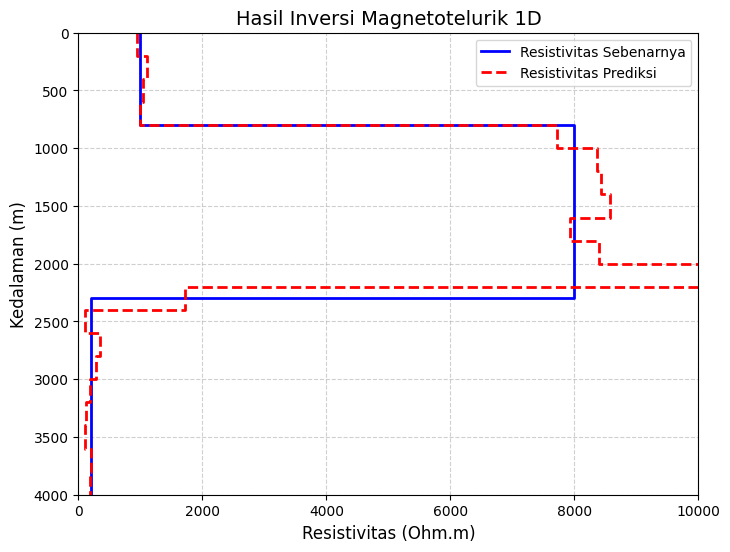

In [ ]:
plot_model_compare(resis_true, ketebalan_true, resis_predict, ketebalan_predict, total_depth)

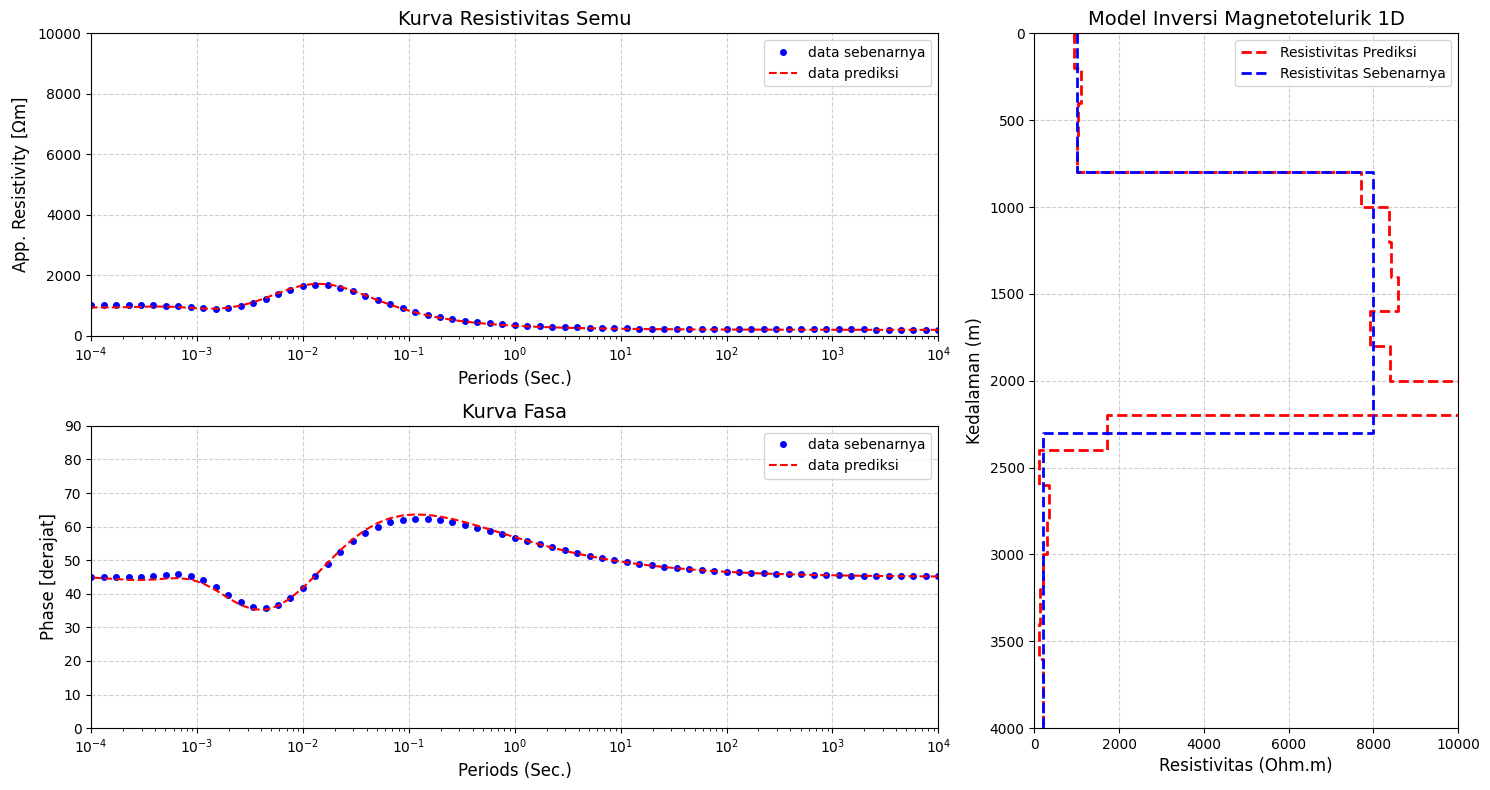

In [ ]:
plot_MT_compare(resis_true, ketebalan_true, resis_predict, ketebalan_predict, period, fasa, resistivitas_semu, fasa_predict,resistivitas_semu_predict, total_depth)

### Error

In [ ]:
measure_MSE(resistivitas_semu, fasa, resistivitas_semu_predict, fasa_predict)

MSE Resistivitas Semu: 670.28
MSE Fasa: 0.34


In [ ]:
measure_MAPE(resistivitas_semu, fasa, resistivitas_semu_predict, fasa_predict)

MAPE resistivitas semu: 4.43%
MAPE fasa: 0.06%


[Interpolated] MSE model resistivitas: 1296132.1089
[Interpolated] MAPE model resistivitas: 37.70%


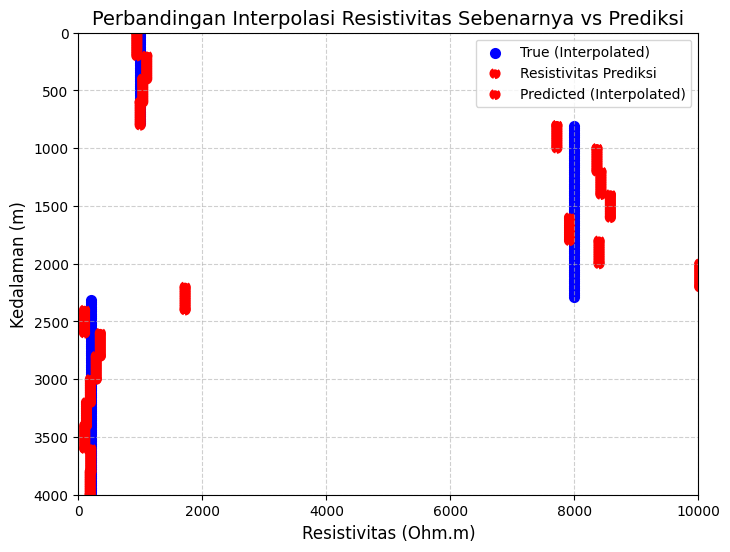

In [ ]:
measure_interpolated_resistivities(resis_true, ketebalan_true, resis_predict, ketebalan_predict, total_depth)


## Model Bumi 3 lapis V

### Prediksi

In [ ]:
# Forward modelling untuk data input
resis_true= np.array([200, 1000,8000])
ketebalan_true = np.array([800, 1500])
frequencies = np.array(np.logspace(-4,4, num=69))
period = 1/frequencies
resistivitas_semu, fasa = forward_modelling(resis_true, ketebalan_true, frequencies)

resistivitas_semu = np.array([resistivitas_semu])
fasa = np.array([fasa])

#Reshape sebelum normalisasi
resistivitas_semu = resistivitas_semu[0].reshape(1, X_input_res.shape[1]) # Corrected reshape syntax
fasa = fasa.reshape(1, X_input_phase.shape[1])

#Logaritmik
resistivitas_semu_log = np.log10(resistivitas_semu)
fasa_log = np.log10(fasa)

# Normalisasi data input
resistivitas_semu_normalized = input_res_scaler.transform(resistivitas_semu_log)
fasa_normalized = input_phase_scaler.transform(fasa_log)

# Reshape jika perlu (misalnya, untuk input CNN)
resistivitas_semu_normalized = resistivitas_semu_normalized.reshape(1, X_input_res.shape[1], 1)
fasa_normalized = fasa_normalized.reshape(1, X_input_phase.shape[1], 1)

# Prediksi
predictions = model.predict([resistivitas_semu_normalized, fasa_normalized])

# Denormalisasi hasil prediksi, apply to the predictions, not hasil
predictions_denormalized = output_model_scaler.inverse_transform(predictions)
predictions_denormalized = np.power(10, predictions_denormalized)

# Accessing the values from predictions_denormalized
resis_predict = predictions_denormalized[0]
ketebalan_predict = np.full(jumlah_layer-1,layer_thickness)#Access elements from index 4 onwards

#Forward Modelling from prediction model
resistivitas_semu_predict, fasa_predict = forward_modelling(resis_predict, ketebalan_predict, frequencies)

resistivitas_semu_predict = np.array([resistivitas_semu_predict])
fasa_predict = np.array([fasa_predict])


#print(hasil) #No need to print hasil as it's not used

print("Nilai Resis_True", resis_true)
print("Nilai ketebalan_True",ketebalan_true)
print("Nilai resis_predict",resis_predict)
print("Nilai ketebalan_predict",ketebalan_predict)

1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 96ms/step
Nilai Resis_True [ 200 1000 8000]
Nilai ketebalan_True [ 800 1500]
Nilai resis_predict [ 198.36687  209.03995  202.4758   241.33727 1000.21356 1532.3519
 1169.5946   880.6885  1028.471   1717.082   2294.4995  3799.3145
 4535.3916  5912.0366  6469.2114  7501.3506  7809.2505  7604.6577
 6857.765   8245.126  ]
Nilai ketebalan_predict [200. 200. 200. 200. 200. 200. 200. 200. 200. 200. 200. 200. 200. 200.
 200. 200. 200. 200. 200.]


### Grafik

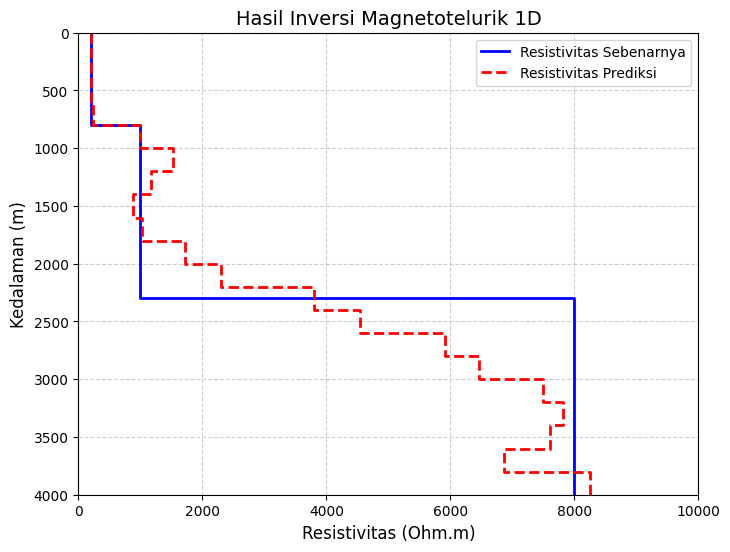

In [ ]:
plot_model_compare(resis_true, ketebalan_true, resis_predict, ketebalan_predict, total_depth)


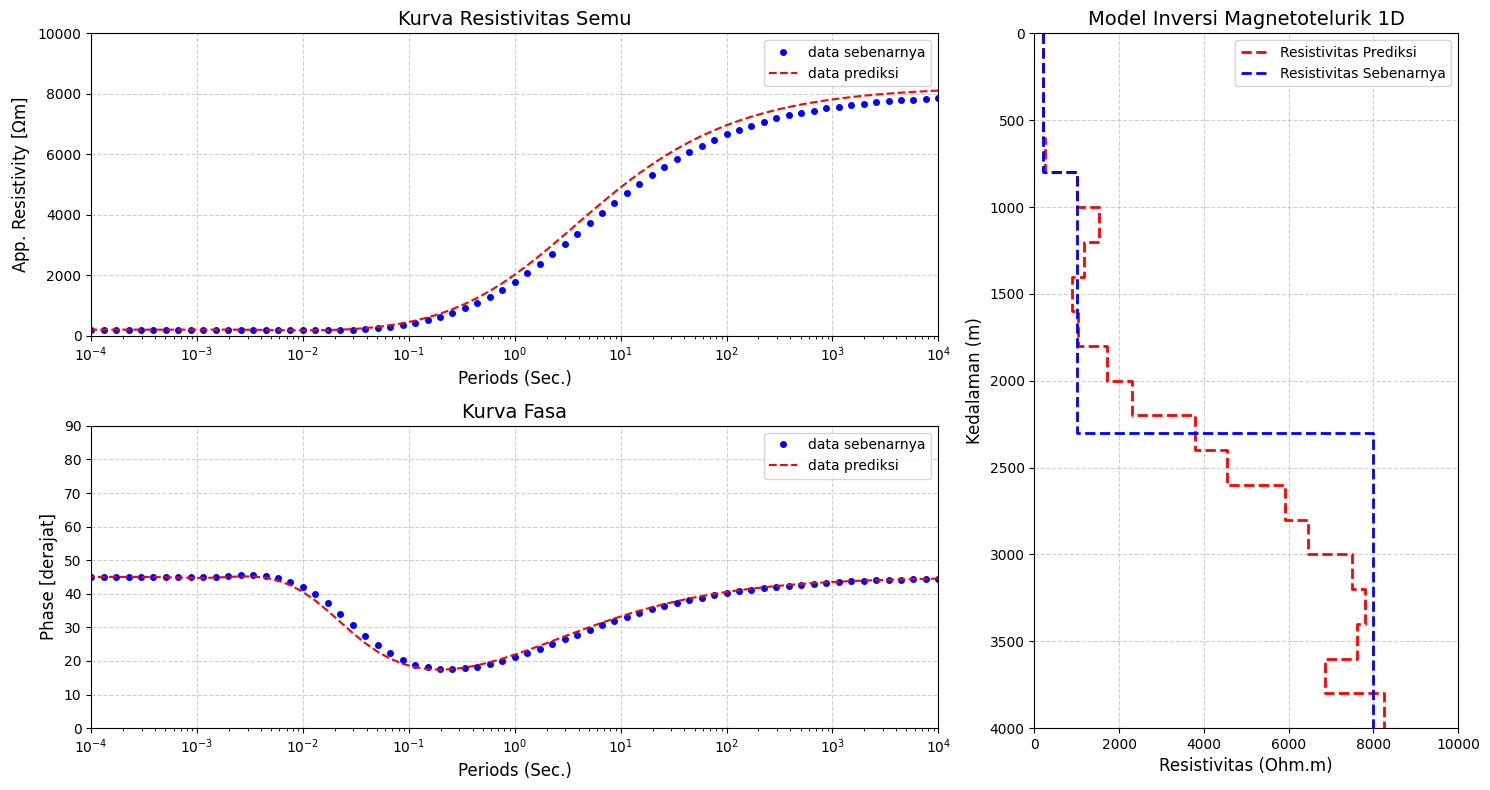

In [ ]:
plot_MT_compare(resis_true, ketebalan_true, resis_predict, ketebalan_predict, period, fasa, resistivitas_semu, fasa_predict,resistivitas_semu_predict, total_depth)


### Error

In [ ]:
measure_MSE(resistivitas_semu, fasa, resistivitas_semu_predict, fasa_predict)

MSE Resistivitas Semu: 46877.60
MSE Fasa: 0.71


In [ ]:
measure_MAPE(resistivitas_semu, fasa, resistivitas_semu_predict, fasa_predict)

MAPE resistivitas semu: 6.00%
MAPE fasa: 0.17%


[Interpolated] MSE model resistivitas: 1788621.8691
[Interpolated] MAPE model resistivitas: 29.95%


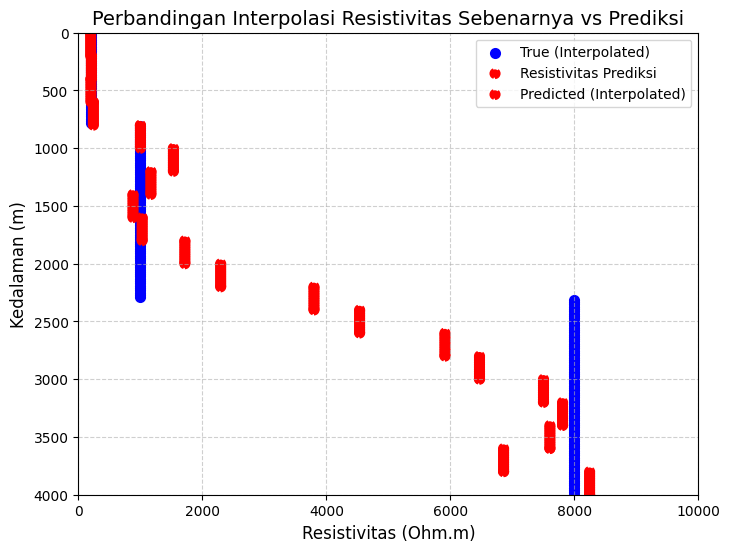

In [ ]:
measure_interpolated_resistivities(resis_true, ketebalan_true, resis_predict, ketebalan_predict, total_depth)

## Model Bumi 3 lapis VI

###Prediksi

In [ ]:
# Forward modelling untuk data input
resis_true= np.array([1000, 8000, 200])
ketebalan_true = np.array([1500, 800])
frequencies = np.array(np.logspace(-4,4, num=69))
period = 1/frequencies
resistivitas_semu, fasa = forward_modelling(resis_true, ketebalan_true, frequencies)

resistivitas_semu = np.array([resistivitas_semu])
fasa = np.array([fasa])

#Reshape sebelum normalisasi
resistivitas_semu = resistivitas_semu[0].reshape(1, X_input_res.shape[1]) # Corrected reshape syntax
fasa = fasa.reshape(1, X_input_phase.shape[1])

#Logaritmik
resistivitas_semu_log = np.log10(resistivitas_semu)
fasa_log = np.log10(fasa)

# Normalisasi data input
resistivitas_semu_normalized = input_res_scaler.transform(resistivitas_semu_log)
fasa_normalized = input_phase_scaler.transform(fasa_log)

# Reshape jika perlu (misalnya, untuk input CNN)
resistivitas_semu_normalized = resistivitas_semu_normalized.reshape(1, X_input_res.shape[1], 1)
fasa_normalized = fasa_normalized.reshape(1, X_input_phase.shape[1], 1)

# Prediksi
predictions = model.predict([resistivitas_semu_normalized, fasa_normalized])

# Denormalisasi hasil prediksi, apply to the predictions, not hasil
predictions_denormalized = output_model_scaler.inverse_transform(predictions)
predictions_denormalized = np.power(10, predictions_denormalized)

# Accessing the values from predictions_denormalized
resis_predict = predictions_denormalized[0]
ketebalan_predict = np.full(jumlah_layer-1,layer_thickness)#Access elements from index 4 onwards

#Forward Modelling from prediction model
resistivitas_semu_predict, fasa_predict = forward_modelling(resis_predict, ketebalan_predict, frequencies)

resistivitas_semu_predict = np.array([resistivitas_semu_predict])
fasa_predict = np.array([fasa_predict])


#print(hasil) #No need to print hasil as it's not used

print("Nilai Resis_True", resis_true)
print("Nilai ketebalan_True",ketebalan_true)
print("Nilai resis_predict",resis_predict)
print("Nilai ketebalan_predict",ketebalan_predict)

1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 43ms/step
Nilai Resis_True [1000 8000  200]
Nilai ketebalan_True [1500  800]
Nilai resis_predict [1118.5503    860.38367  1099.1383    909.9485   1065.143     671.6617
  713.95654  4224.834    5258.916    4927.782    3315.9426    853.2139
  249.95274   182.91003   164.08534   211.7417    148.22089   124.878044
  203.03857   199.87132 ]
Nilai ketebalan_predict [200. 200. 200. 200. 200. 200. 200. 200. 200. 200. 200. 200. 200. 200.
 200. 200. 200. 200. 200.]


### Grafik

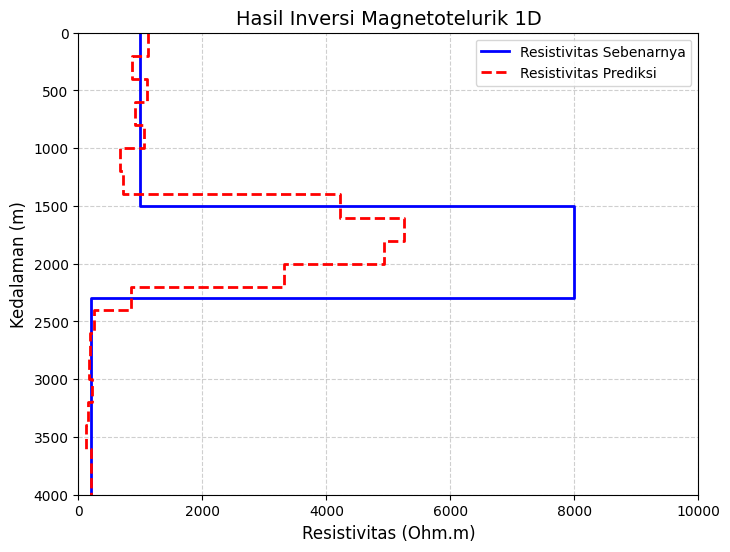

In [ ]:
plot_model_compare(resis_true, ketebalan_true, resis_predict, ketebalan_predict, total_depth)


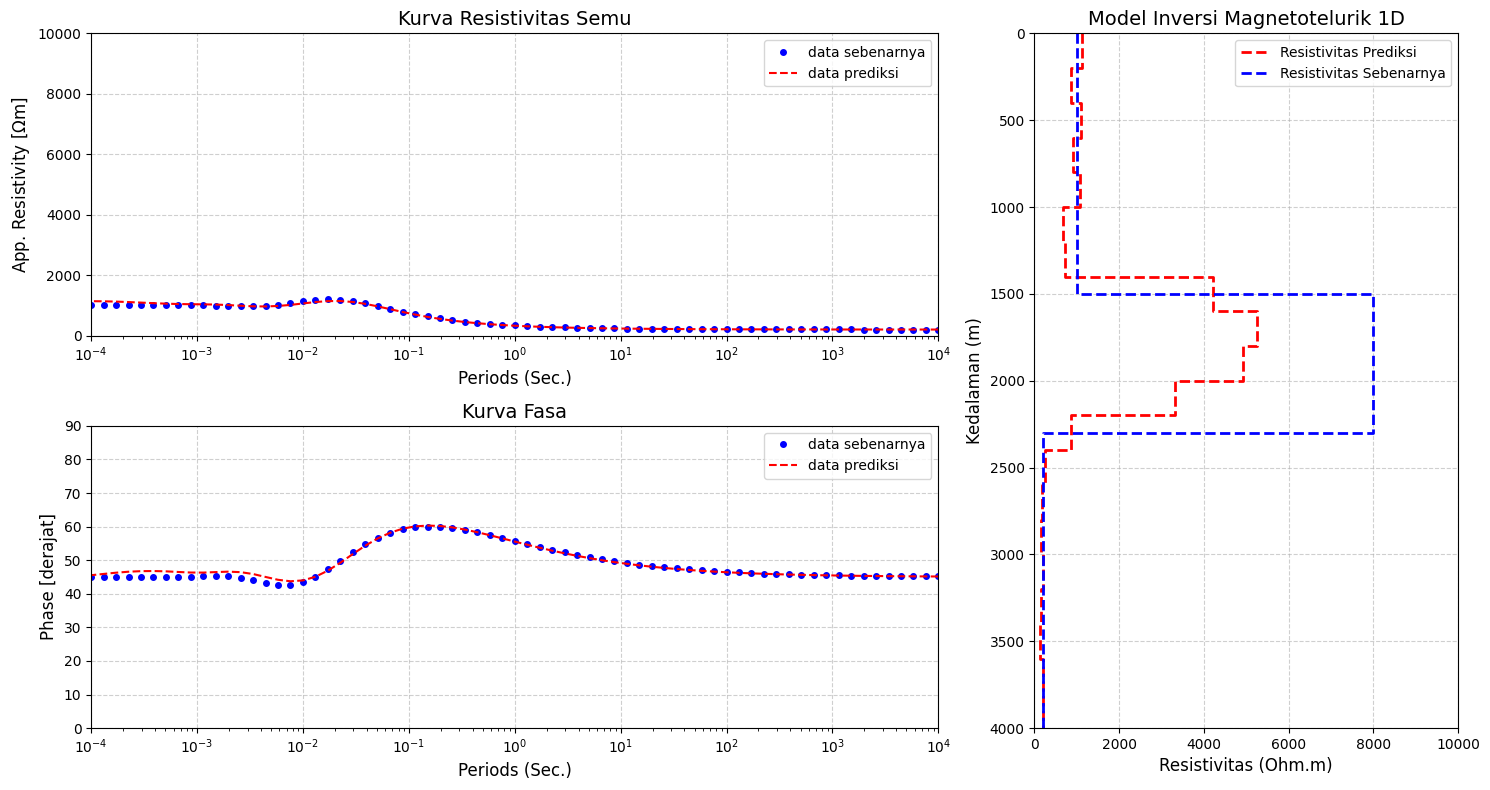

In [ ]:
plot_MT_compare(resis_true, ketebalan_true, resis_predict, ketebalan_predict, period, fasa, resistivitas_semu, fasa_predict,resistivitas_semu_predict, total_depth)

### Error

In [ ]:
measure_MSE(resistivitas_semu, fasa, resistivitas_semu_predict, fasa_predict)

MSE Resistivitas Semu: 1674.46
MSE Fasa: 0.57


In [ ]:
measure_MAPE(resistivitas_semu, fasa, resistivitas_semu_predict, fasa_predict)

MAPE resistivitas semu: 2.86%
MAPE fasa: 0.07%


[Interpolated] MSE model resistivitas: 3861384.8428
[Interpolated] MAPE model resistivitas: 37.95%


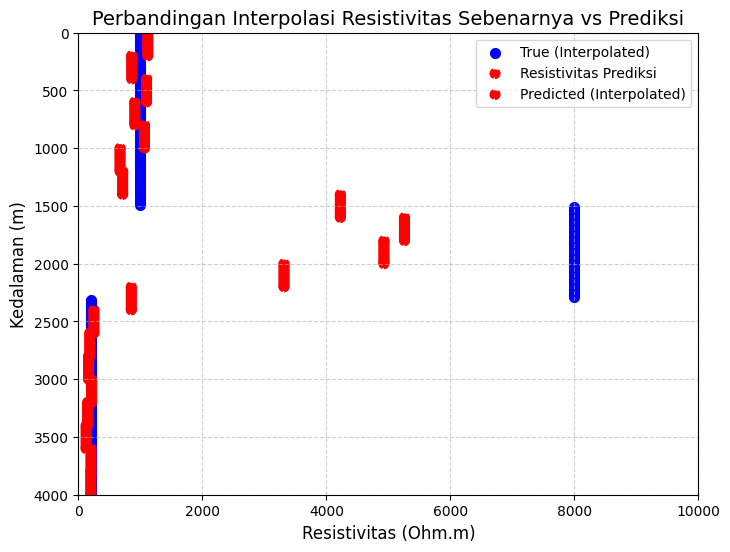

In [ ]:
measure_interpolated_resistivities(resis_true, ketebalan_true, resis_predict, ketebalan_predict, total_depth)
#

# Prediksi Bumi 4 lapis

## Model Bumi 4 lapis I

### Prediksi

In [ ]:
# Forward modelling untuk data input
resis_true= np.array([100, 5000, 3000, 8000])
ketebalan_true = np.array([500, 1200, 2000])
frequencies = np.array(np.logspace(-4,4, num=69))
period = 1/frequencies
resistivitas_semu, fasa = forward_modelling(resis_true, ketebalan_true, frequencies)

resistivitas_semu = np.array([resistivitas_semu])
fasa = np.array([fasa])

#Reshape sebelum normalisasi
resistivitas_semu = resistivitas_semu[0].reshape(1, X_input_res.shape[1]) # Corrected reshape syntax
fasa = fasa.reshape(1, X_input_phase.shape[1])

#Logaritmik
resistivitas_semu_log = np.log10(resistivitas_semu)
fasa_log = np.log10(fasa)

# Normalisasi data input
resistivitas_semu_normalized = input_res_scaler.transform(resistivitas_semu_log)
fasa_normalized = input_phase_scaler.transform(fasa_log)

# Reshape jika perlu (misalnya, untuk input CNN)
resistivitas_semu_normalized = resistivitas_semu_normalized.reshape(1, X_input_res.shape[1], 1)
fasa_normalized = fasa_normalized.reshape(1, X_input_phase.shape[1], 1)

# Prediksi
predictions = model.predict([resistivitas_semu_normalized, fasa_normalized])

# Denormalisasi hasil prediksi, apply to the predictions, not hasil
predictions_denormalized = output_model_scaler.inverse_transform(predictions)
predictions_denormalized = np.power(10, predictions_denormalized)

# Accessing the values from predictions_denormalized
resis_predict = predictions_denormalized[0]
ketebalan_predict = np.full(jumlah_layer-1,layer_thickness)#Access elements from index 4 onwards

#Forward Modelling from prediction model
resistivitas_semu_predict, fasa_predict = forward_modelling(resis_predict, ketebalan_predict, frequencies)

resistivitas_semu_predict = np.array([resistivitas_semu_predict])
fasa_predict = np.array([fasa_predict])


#print(hasil) #No need to print hasil as it's not used

print("Nilai Resis_True", resis_true)
print("Nilai ketebalan_True",ketebalan_true)
print("Nilai resis_predict",resis_predict)
print("Nilai ketebalan_predict",ketebalan_predict)

1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 44ms/step
Nilai Resis_True [ 100 5000 3000 8000]
Nilai ketebalan_True [ 500 1200 2000]
Nilai resis_predict [ 103.30947  109.48962  300.25958 7319.2515  5313.8525  4951.812
 4981.882   5500.582   4839.629   5043.548   4488.912   3762.3442
 3488.3167  3026.5293  2368.1018  2865.5935  4283.8315  4585.553
 6413.4395  8376.108  ]
Nilai ketebalan_predict [200. 200. 200. 200. 200. 200. 200. 200. 200. 200. 200. 200. 200. 200.
 200. 200. 200. 200. 200.]


### Grafik

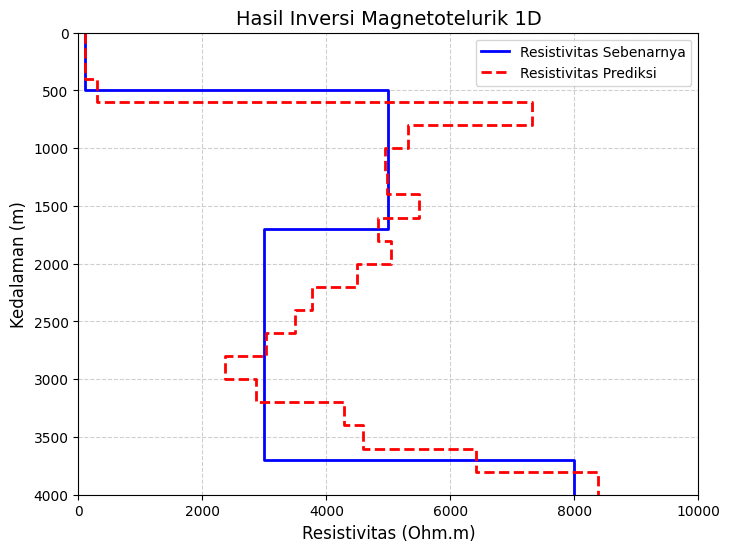

In [ ]:
plot_model_compare(resis_true, ketebalan_true, resis_predict, ketebalan_predict, total_depth)


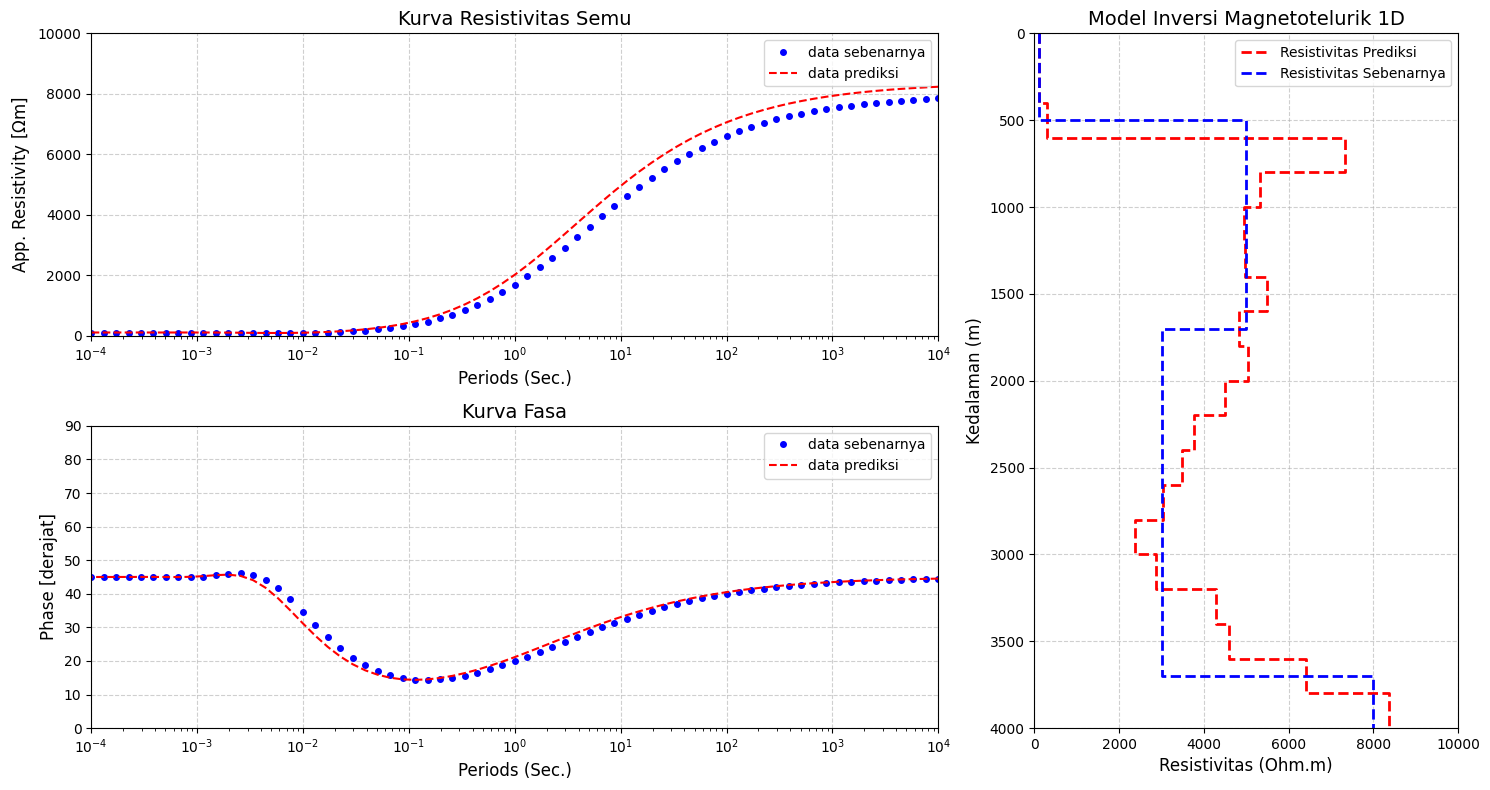

In [ ]:
plot_MT_compare(resis_true, ketebalan_true, resis_predict, ketebalan_predict, period, fasa, resistivitas_semu, fasa_predict,resistivitas_semu_predict, total_depth)

### Error

In [ ]:
measure_MSE(resistivitas_semu, fasa, resistivitas_semu_predict, fasa_predict)

MSE Resistivitas Semu: 101576.19
MSE Fasa: 1.43


In [ ]:
measure_MAPE(resistivitas_semu, fasa, resistivitas_semu_predict, fasa_predict)

MAPE resistivitas semu: 10.63%
MAPE fasa: 0.44%


[Interpolated] MSE model resistivitas: 1875911.8988
[Interpolated] MAPE model resistivitas: 30.46%


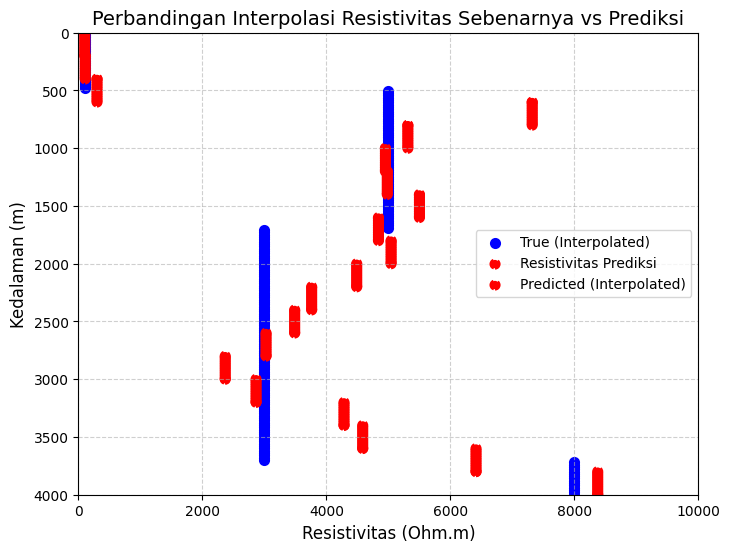

In [ ]:
measure_interpolated_resistivities(resis_true, ketebalan_true, resis_predict, ketebalan_predict, total_depth)

## Model Bumi 4 lapis II

### Prediksi

In [ ]:
# Forward modelling untuk data input
resis_true= np.array([500,3000, 8000, 100])
ketebalan_true = np.array([1200, 2000, 500])
frequencies = np.array(np.logspace(-4,4, num=69))
period = 1/frequencies
resistivitas_semu, fasa = forward_modelling(resis_true, ketebalan_true, frequencies)

resistivitas_semu = np.array([resistivitas_semu])
fasa = np.array([fasa])

#Reshape sebelum normalisasi
resistivitas_semu = resistivitas_semu[0].reshape(1, X_input_res.shape[1]) # Corrected reshape syntax
fasa = fasa.reshape(1, X_input_phase.shape[1])

#Logaritmik
resistivitas_semu_log = np.log10(resistivitas_semu)
fasa_log = np.log10(fasa)

# Normalisasi data input
resistivitas_semu_normalized = input_res_scaler.transform(resistivitas_semu_log)
fasa_normalized = input_phase_scaler.transform(fasa_log)

# Reshape jika perlu (misalnya, untuk input CNN)
resistivitas_semu_normalized = resistivitas_semu_normalized.reshape(1, X_input_res.shape[1], 1)
fasa_normalized = fasa_normalized.reshape(1, X_input_phase.shape[1], 1)

# Prediksi
predictions = model.predict([resistivitas_semu_normalized, fasa_normalized])

# Denormalisasi hasil prediksi, apply to the predictions, not hasil
predictions_denormalized = output_model_scaler.inverse_transform(predictions)
predictions_denormalized = np.power(10, predictions_denormalized)

# Accessing the values from predictions_denormalized
resis_predict = predictions_denormalized[0]
ketebalan_predict = np.full(jumlah_layer-1,layer_thickness)#Access elements from index 4 onwards

#Forward Modelling from prediction model
resistivitas_semu_predict, fasa_predict = forward_modelling(resis_predict, ketebalan_predict, frequencies)

resistivitas_semu_predict = np.array([resistivitas_semu_predict])
fasa_predict = np.array([fasa_predict])


#print(hasil) #No need to print hasil as it's not used

print("Nilai Resis_True", resis_true)
print("Nilai ketebalan_True",ketebalan_true)
print("Nilai resis_predict",resis_predict)
print("Nilai ketebalan_predict",ketebalan_predict)

1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 49ms/step
Nilai Resis_True [ 500 3000 8000  100]
Nilai ketebalan_True [1200 2000  500]
Nilai resis_predict [ 596.2669   498.69852  454.77078  567.1287   413.94638  451.70685
 1803.9426  6353.0195  3701.5405  4853.4297  4554.544   3947.274
 4243.9097  3223.688   3723.1494  4100.0186  4176.513   3138.0698
  574.7346    93.09409]
Nilai ketebalan_predict [200. 200. 200. 200. 200. 200. 200. 200. 200. 200. 200. 200. 200. 200.
 200. 200. 200. 200. 200.]


### Grafik

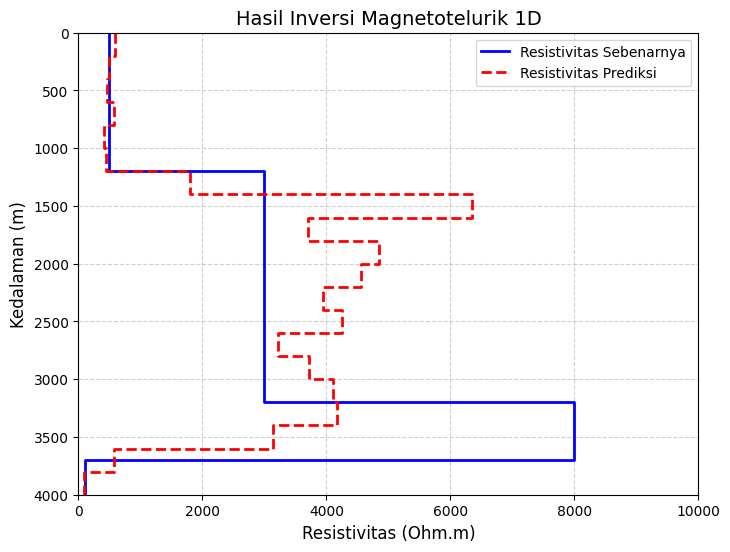

In [ ]:
plot_model_compare(resis_true, ketebalan_true, resis_predict, ketebalan_predict, total_depth)

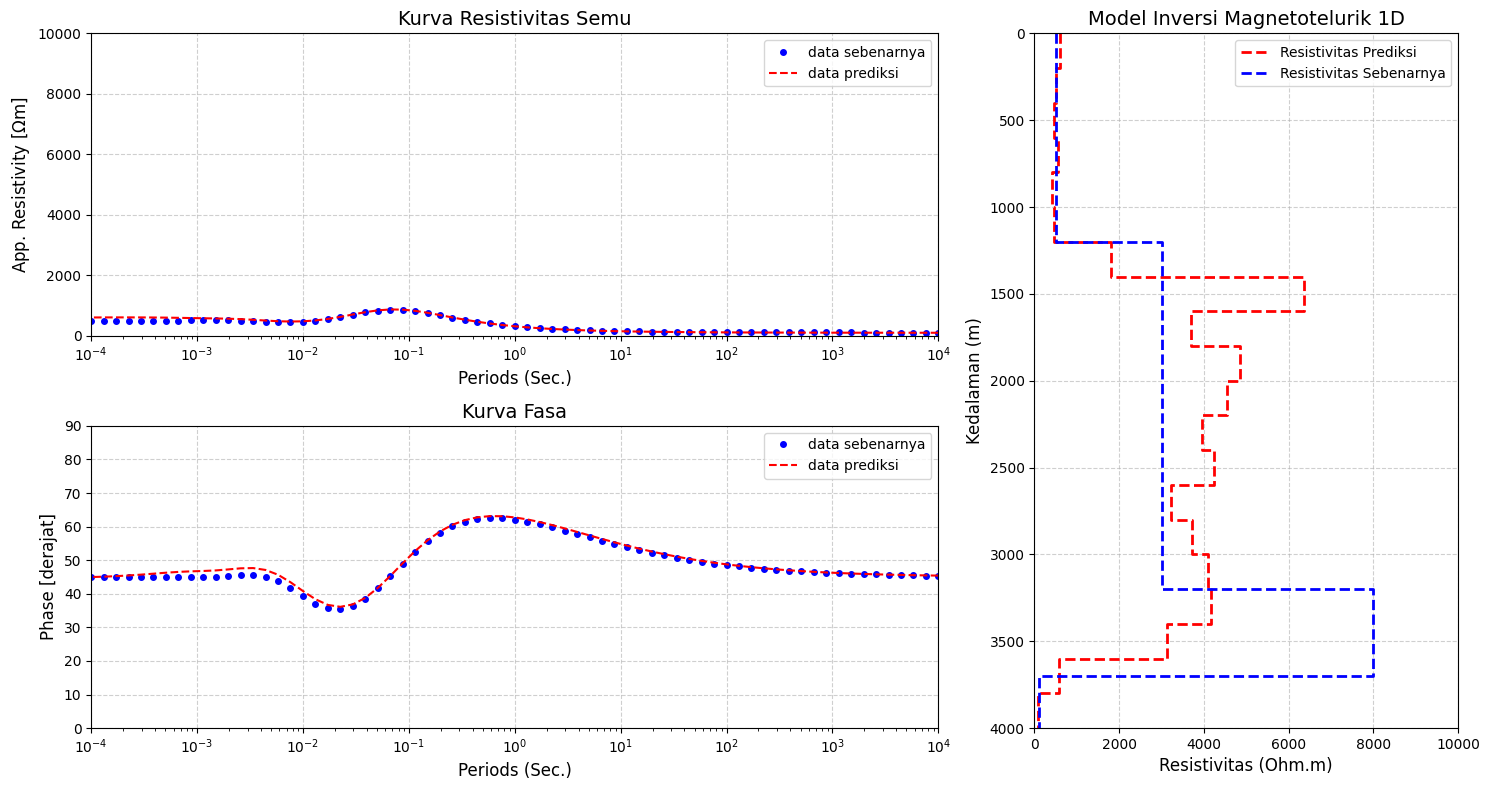

In [ ]:
plot_MT_compare(resis_true, ketebalan_true, resis_predict, ketebalan_predict, period, fasa, resistivitas_semu, fasa_predict,resistivitas_semu_predict, total_depth)


### Error

In [ ]:
measure_MSE(resistivitas_semu, fasa, resistivitas_semu_predict, fasa_predict)

MSE Resistivitas Semu: 1562.60
MSE Fasa: 0.72


In [ ]:
measure_MAPE(resistivitas_semu, fasa, resistivitas_semu_predict, fasa_predict)

MAPE resistivitas semu: 6.56%
MAPE fasa: 0.18%


[Interpolated] MSE model resistivitas: 4460395.7109
[Interpolated] MAPE model resistivitas: 44.90%


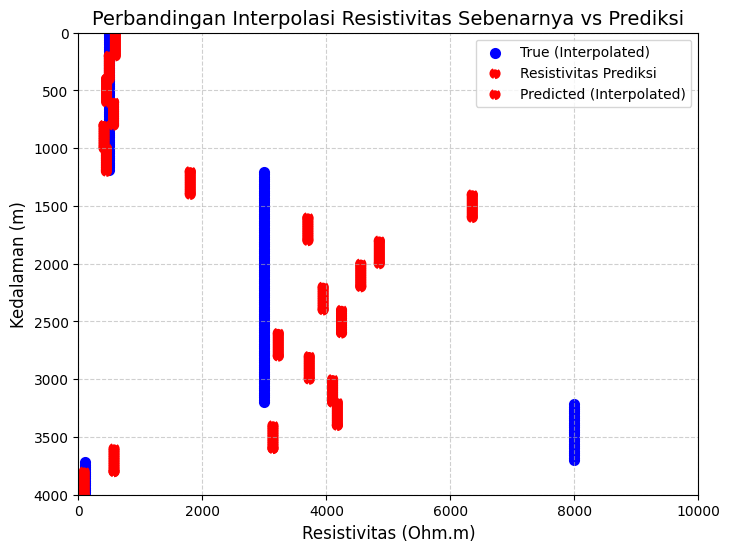

In [ ]:
measure_interpolated_resistivities(resis_true, ketebalan_true, resis_predict, ketebalan_predict, total_depth)


## Model Bumi 4 lapis III

### Prediksi

In [ ]:
# Forward modelling untuk data input
resis_true= np.array([3000,8000,100, 500])
ketebalan_true = np.array([2000, 500, 1200])
frequencies = np.array(np.logspace(-4,4, num=69))
period = 1/frequencies
resistivitas_semu, fasa = forward_modelling(resis_true, ketebalan_true, frequencies)

resistivitas_semu = np.array([resistivitas_semu])
fasa = np.array([fasa])

#Reshape sebelum normalisasi
resistivitas_semu = resistivitas_semu[0].reshape(1, X_input_res.shape[1]) # Corrected reshape syntax
fasa = fasa.reshape(1, X_input_phase.shape[1])

#Logaritmik
resistivitas_semu_log = np.log10(resistivitas_semu)
fasa_log = np.log10(fasa)

# Normalisasi data input
resistivitas_semu_normalized = input_res_scaler.transform(resistivitas_semu_log)
fasa_normalized = input_phase_scaler.transform(fasa_log)

# Reshape jika perlu (misalnya, untuk input CNN)
resistivitas_semu_normalized = resistivitas_semu_normalized.reshape(1, X_input_res.shape[1], 1)
fasa_normalized = fasa_normalized.reshape(1, X_input_phase.shape[1], 1)

# Prediksi
predictions = model.predict([resistivitas_semu_normalized, fasa_normalized])

# Denormalisasi hasil prediksi, apply to the predictions, not hasil
predictions_denormalized = output_model_scaler.inverse_transform(predictions)
predictions_denormalized = np.power(10, predictions_denormalized)

# Accessing the values from predictions_denormalized
resis_predict = predictions_denormalized[0]
ketebalan_predict = np.full(jumlah_layer-1,layer_thickness)#Access elements from index 4 onwards

#Forward Modelling from prediction model
resistivitas_semu_predict, fasa_predict = forward_modelling(resis_predict, ketebalan_predict, frequencies)

resistivitas_semu_predict = np.array([resistivitas_semu_predict])
fasa_predict = np.array([fasa_predict])


#print(hasil) #No need to print hasil as it's not used

print("Nilai Resis_True", resis_true)
print("Nilai ketebalan_True",ketebalan_true)
print("Nilai resis_predict",resis_predict)
print("Nilai ketebalan_predict",ketebalan_predict)

1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 44ms/step
Nilai Resis_True [3000 8000  100  500]
Nilai ketebalan_True [2000  500 1200]
Nilai resis_predict [2896.9102   3021.0994   3215.0156   3021.4395   2854.695    3335.7563
 2546.4465   2982.5037   3879.7693   4647.344    4727.952    6423.697
 1372.3805     68.021545  101.33517    87.75023    87.82098    65.851616
  379.6783    571.8948  ]
Nilai ketebalan_predict [200. 200. 200. 200. 200. 200. 200. 200. 200. 200. 200. 200. 200. 200.
 200. 200. 200. 200. 200.]


### Grafik

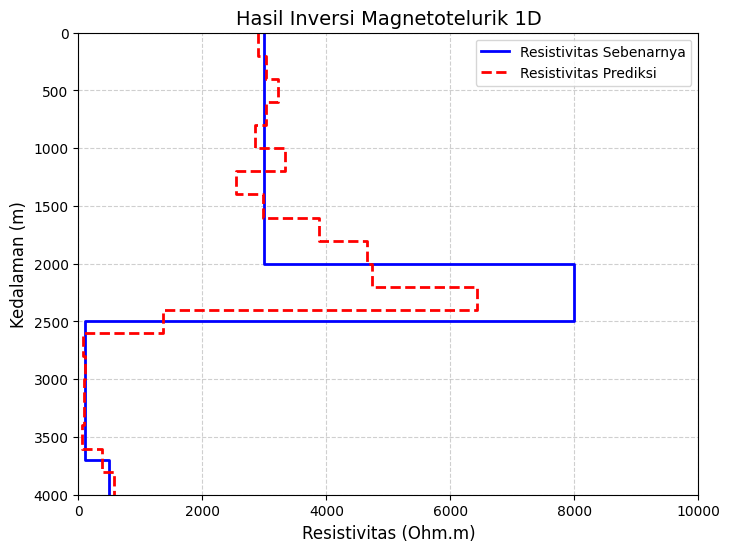

In [ ]:
plot_model_compare(resis_true, ketebalan_true, resis_predict, ketebalan_predict, total_depth)

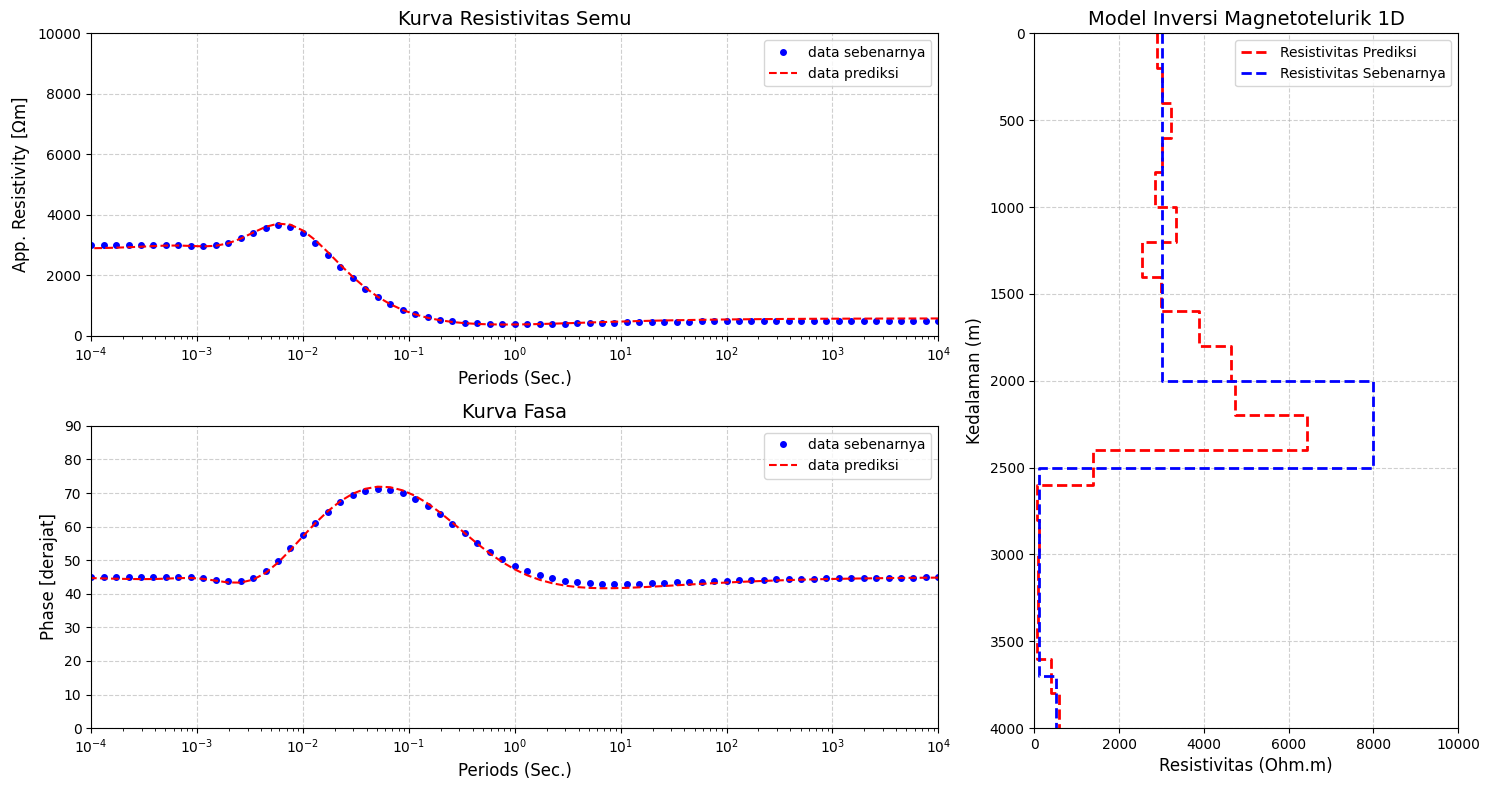

In [ ]:
plot_MT_compare(resis_true, ketebalan_true, resis_predict, ketebalan_predict, period, fasa, resistivitas_semu, fasa_predict,resistivitas_semu_predict, total_depth)

### Error

In [ ]:
measure_MSE(resistivitas_semu, fasa, resistivitas_semu_predict, fasa_predict)

MSE Resistivitas Semu: 2648.69
MSE Fasa: 0.50


In [ ]:
measure_MAPE(resistivitas_semu, fasa, resistivitas_semu_predict, fasa_predict)

MAPE resistivitas semu: 5.99%
MAPE fasa: 0.10%


[Interpolated] MSE model resistivitas: 1995127.2717
[Interpolated] MAPE model resistivitas: 56.22%


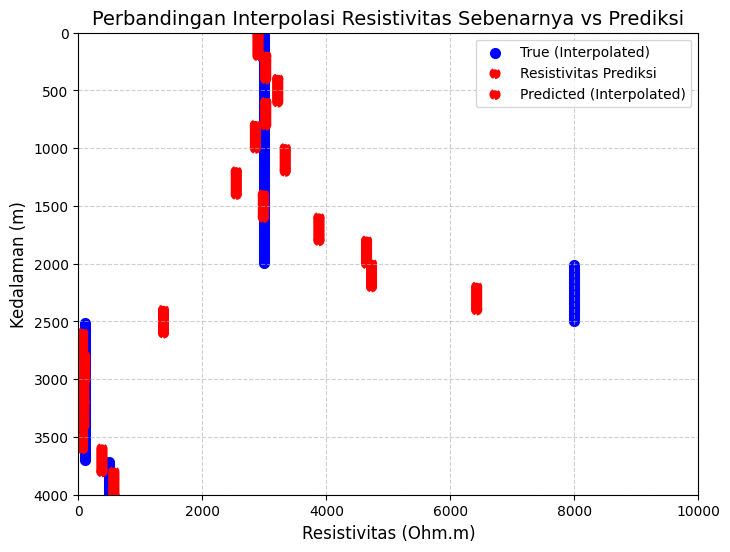

In [ ]:
measure_interpolated_resistivities(resis_true, ketebalan_true, resis_predict, ketebalan_predict, total_depth)

## Model Bumi 4 lapis IV

### Prediksi

In [ ]:
# Forward modelling untuk data input
resis_true= np.array([8000, 100, 500, 3000])
ketebalan_true = np.array([500, 1200, 2000])
frequencies = np.array(np.logspace(-4,4, num=69))
period = 1/frequencies
resistivitas_semu, fasa = forward_modelling(resis_true, ketebalan_true, frequencies)

resistivitas_semu = np.array([resistivitas_semu])
fasa = np.array([fasa])

#Reshape sebelum normalisasi
resistivitas_semu = resistivitas_semu[0].reshape(1, X_input_res.shape[1]) # Corrected reshape syntax
fasa = fasa.reshape(1, X_input_phase.shape[1])

#Logaritmik
resistivitas_semu_log = np.log10(resistivitas_semu)
fasa_log = np.log10(fasa)

# Normalisasi data input
resistivitas_semu_normalized = input_res_scaler.transform(resistivitas_semu_log)
fasa_normalized = input_phase_scaler.transform(fasa_log)

# Reshape jika perlu (misalnya, untuk input CNN)
resistivitas_semu_normalized = resistivitas_semu_normalized.reshape(1, X_input_res.shape[1], 1)
fasa_normalized = fasa_normalized.reshape(1, X_input_phase.shape[1], 1)

# Prediksi
predictions = model.predict([resistivitas_semu_normalized, fasa_normalized])

# Denormalisasi hasil prediksi, apply to the predictions, not hasil
predictions_denormalized = output_model_scaler.inverse_transform(predictions)
predictions_denormalized = np.power(10, predictions_denormalized)

# Accessing the values from predictions_denormalized
resis_predict = predictions_denormalized[0]
ketebalan_predict = np.full(jumlah_layer-1,layer_thickness)#Access elements from index 4 onwards

#Forward Modelling from prediction model
resistivitas_semu_predict, fasa_predict = forward_modelling(resis_predict, ketebalan_predict, frequencies)

resistivitas_semu_predict = np.array([resistivitas_semu_predict])
fasa_predict = np.array([fasa_predict])


#print(hasil) #No need to print hasil as it's not used

print("Nilai Resis_True", resis_true)
print("Nilai ketebalan_True",ketebalan_true)
print("Nilai resis_predict",resis_predict)
print("Nilai ketebalan_predict",ketebalan_predict)

1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 42ms/step
Nilai Resis_True [8000  100  500 3000]
Nilai ketebalan_True [ 500 1200 2000]
Nilai resis_predict [ 5566.963   11317.749     392.95468   151.27184   110.83277    91.50767
   107.62202   179.19296   433.31348   972.6045   1621.6295   1684.9094
  1095.6616    704.6378    476.49323   496.3207   1046.3688   1379.0614
  1683.2343   2531.4226 ]
Nilai ketebalan_predict [200. 200. 200. 200. 200. 200. 200. 200. 200. 200. 200. 200. 200. 200.
 200. 200. 200. 200. 200.]


### Grafik

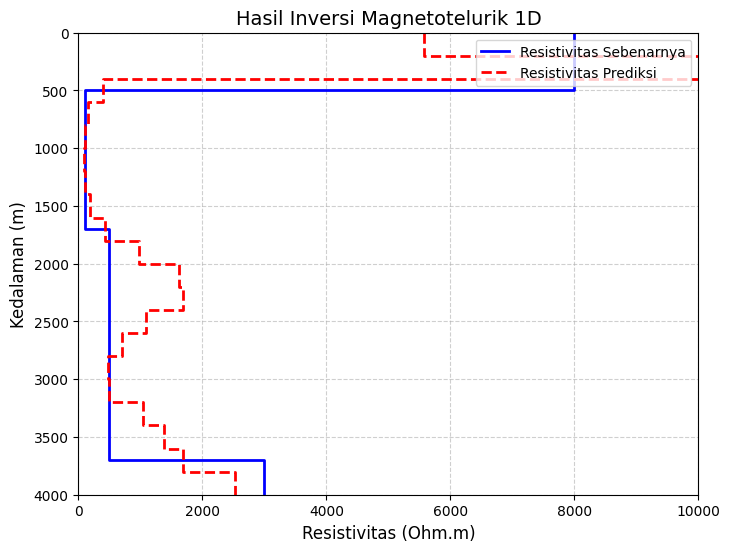

In [ ]:
plot_model_compare(resis_true, ketebalan_true, resis_predict, ketebalan_predict, total_depth)

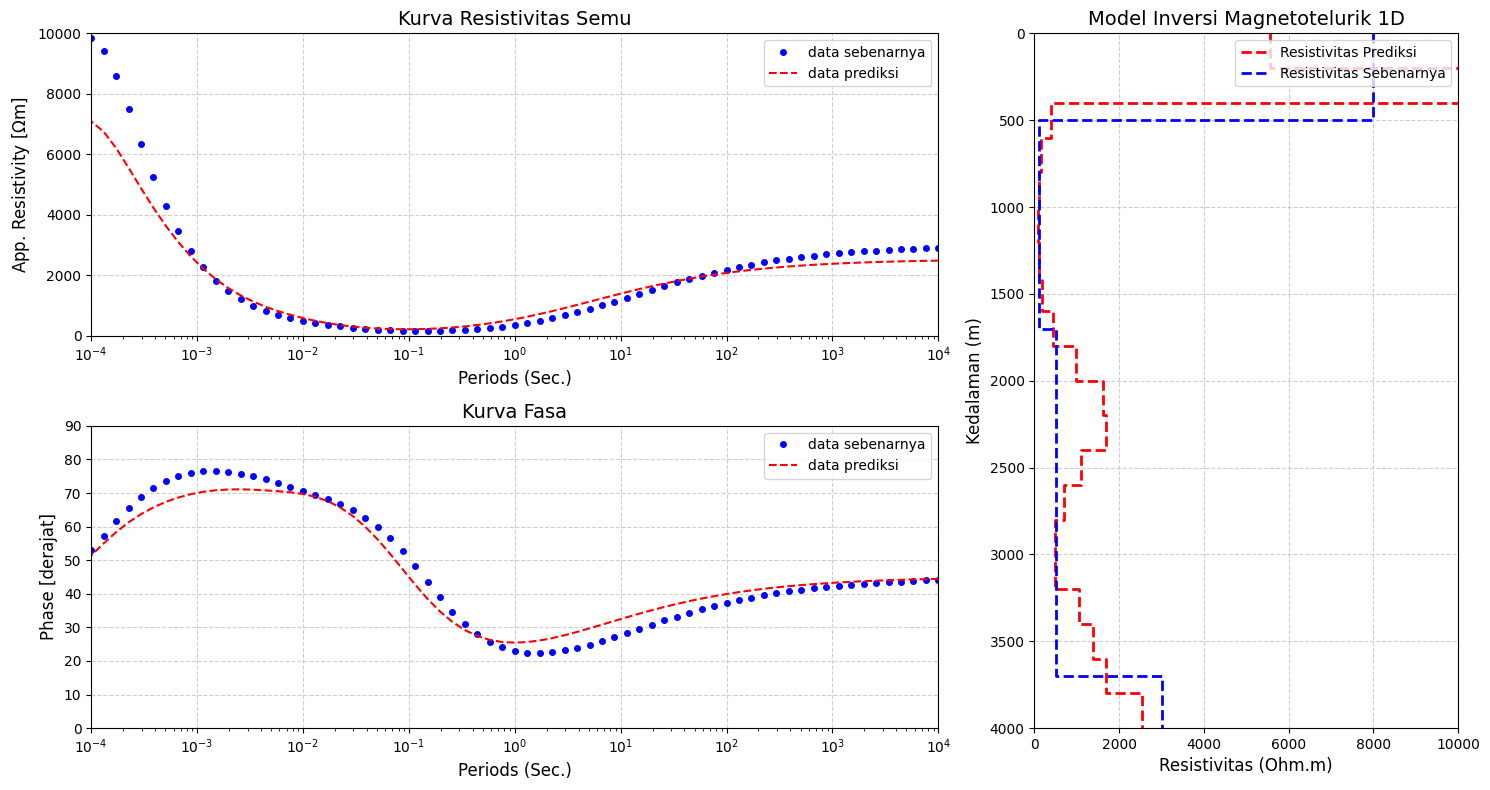

In [ ]:
plot_MT_compare(resis_true, ketebalan_true, resis_predict, ketebalan_predict, period, fasa, resistivitas_semu, fasa_predict,resistivitas_semu_predict, total_depth)


### Error

In [ ]:
measure_MSE(resistivitas_semu, fasa, resistivitas_semu_predict, fasa_predict)

MSE Resistivitas Semu: 446041.26
MSE Fasa: 12.40


In [ ]:
measure_MAPE(resistivitas_semu, fasa, resistivitas_semu_predict, fasa_predict)

MAPE resistivitas semu: 20.70%
MAPE fasa: 0.52%


[Interpolated] MSE model resistivitas: 2605549.6423
[Interpolated] MAPE model resistivitas: 87.95%


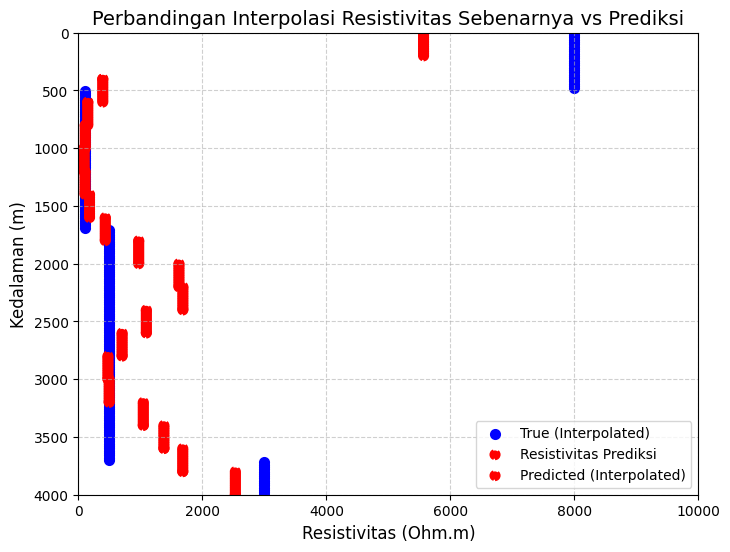

In [ ]:
measure_interpolated_resistivities(resis_true, ketebalan_true, resis_predict, ketebalan_predict, total_depth)
#

## Model Bumi 4 lapis V

### Prediksi

In [ ]:
# Forward modelling untuk data input
resis_true= np.array([100, 3000, 500, 8000])
ketebalan_true = np.array([2000, 1200, 500])
frequencies = np.array(np.logspace(-4,4, num=69))
period = 1/frequencies
resistivitas_semu, fasa = forward_modelling(resis_true, ketebalan_true, frequencies)
resistivitas_semu = np.array([resistivitas_semu])
fasa = np.array([fasa])

#Reshape sebelum normalisasi
resistivitas_semu = resistivitas_semu[0].reshape(1, X_input_res.shape[1]) # Corrected reshape syntax
fasa = fasa.reshape(1, X_input_phase.shape[1])

#Logaritmik
resistivitas_semu_log = np.log10(resistivitas_semu)
fasa_log = np.log10(fasa)

# Normalisasi data input
resistivitas_semu_normalized = input_res_scaler.transform(resistivitas_semu_log)
fasa_normalized = input_phase_scaler.transform(fasa_log)

# Reshape jika perlu (misalnya, untuk input CNN)
resistivitas_semu_normalized = resistivitas_semu_normalized.reshape(1, X_input_res.shape[1], 1)
fasa_normalized = fasa_normalized.reshape(1, X_input_phase.shape[1], 1)

# Prediksi
predictions = model.predict([resistivitas_semu_normalized, fasa_normalized])

# Denormalisasi hasil prediksi, apply to the predictions, not hasil
predictions_denormalized = output_model_scaler.inverse_transform(predictions)
predictions_denormalized = np.power(10, predictions_denormalized)

# Accessing the values from predictions_denormalized
resis_predict = predictions_denormalized[0]
ketebalan_predict = np.full(jumlah_layer-1,layer_thickness)#Access elements from index 4 onwards

#Forward Modelling from prediction model
resistivitas_semu_predict, fasa_predict = forward_modelling(resis_predict, ketebalan_predict, frequencies)

resistivitas_semu_predict = np.array([resistivitas_semu_predict])
fasa_predict = np.array([fasa_predict])


#print(hasil) #No need to print hasil as it's not used

print("Nilai Resis_True", resis_true)
print("Nilai ketebalan_True",ketebalan_true)
print("Nilai resis_predict",resis_predict)
print("Nilai ketebalan_predict",ketebalan_predict)

1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 65ms/step
Nilai Resis_True [ 100 3000  500 8000]
Nilai ketebalan_True [2000 1200  500]
Nilai resis_predict [  83.983246   87.131615   79.12262    81.454735   66.23677    80.119286
   91.56991   113.42467    83.70055   120.73664  1497.0842   1616.4388
 1758.261    2062.1638   2321.0017   2433.5967   2765.0688   3177.5776
 4223.225    8148.219   ]
Nilai ketebalan_predict [200. 200. 200. 200. 200. 200. 200. 200. 200. 200. 200. 200. 200. 200.
 200. 200. 200. 200. 200.]


### Grafik

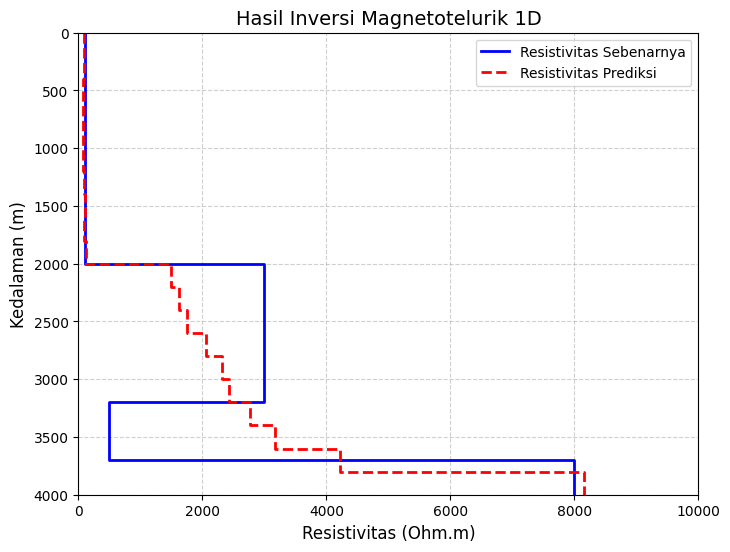

In [ ]:
plot_model_compare(resis_true, ketebalan_true, resis_predict, ketebalan_predict, total_depth)


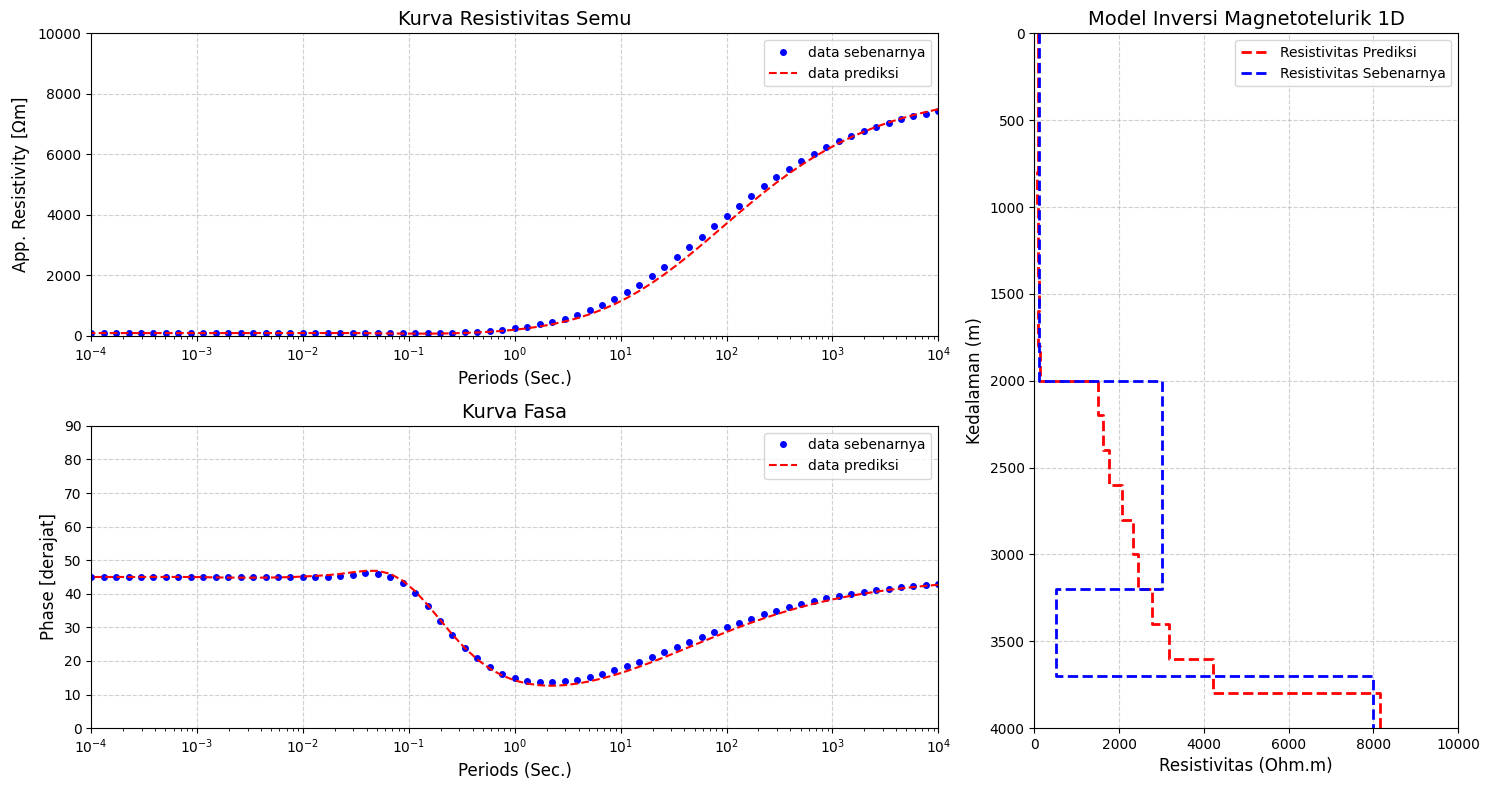

In [ ]:
plot_MT_compare(resis_true, ketebalan_true, resis_predict, ketebalan_predict, period, fasa, resistivitas_semu, fasa_predict,resistivitas_semu_predict, total_depth)

### Error

In [ ]:
measure_MSE(resistivitas_semu, fasa, resistivitas_semu_predict, fasa_predict)

MSE Resistivitas Semu: 13308.51
MSE Fasa: 0.67


In [ ]:
measure_MAPE(resistivitas_semu, fasa, resistivitas_semu_predict, fasa_predict)

MAPE resistivitas semu: 12.24%
MAPE fasa: 0.18%


[Interpolated] MSE model resistivitas: 1688256.4994
[Interpolated] MAPE model resistivitas: 88.88%


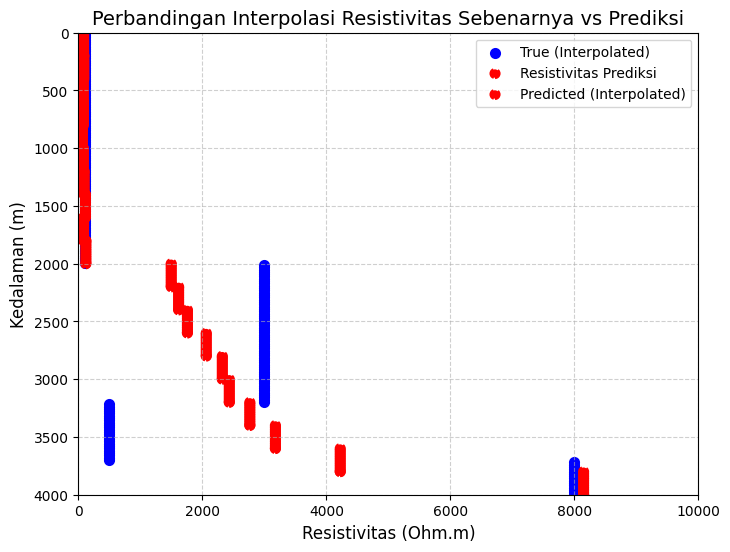

In [ ]:
measure_interpolated_resistivities(resis_true, ketebalan_true, resis_predict, ketebalan_predict, total_depth)


## Model Bumi 4 lapis VI

In [ ]:
# Forward modelling untuk data input
resis_true= np.array([500,8000,100, 3000])
ketebalan_true = np.array([2000, 1200, 500])
frequencies = np.array(np.logspace(-4,4, num=69))
period = 1/frequencies
resistivitas_semu, fasa = forward_modelling(resis_true, ketebalan_true, frequencies)

resistivitas_semu = np.array([resistivitas_semu])
fasa = np.array([fasa])

#Reshape sebelum normalisasi
resistivitas_semu = resistivitas_semu[0].reshape(1, X_input_res.shape[1]) # Corrected reshape syntax
fasa = fasa.reshape(1, X_input_phase.shape[1])

#Logaritmik
resistivitas_semu_log = np.log10(resistivitas_semu)
fasa_log = np.log10(fasa)

# Normalisasi data input
resistivitas_semu_normalized = input_res_scaler.transform(resistivitas_semu_log)
fasa_normalized = input_phase_scaler.transform(fasa_log)

# Reshape jika perlu (misalnya, untuk input CNN)
resistivitas_semu_normalized = resistivitas_semu_normalized.reshape(1, X_input_res.shape[1], 1)
fasa_normalized = fasa_normalized.reshape(1, X_input_phase.shape[1], 1)

# Prediksi
predictions = model.predict([resistivitas_semu_normalized, fasa_normalized])

# Denormalisasi hasil prediksi, apply to the predictions, not hasil
predictions_denormalized = output_model_scaler.inverse_transform(predictions)
predictions_denormalized = np.power(10, predictions_denormalized)

# Accessing the values from predictions_denormalized
resis_predict = predictions_denormalized[0]
ketebalan_predict = np.full(jumlah_layer-1,layer_thickness)#Access elements from index 4 onwards

#Forward Modelling from prediction model
resistivitas_semu_predict, fasa_predict = forward_modelling(resis_predict, ketebalan_predict, frequencies)

resistivitas_semu_predict = np.array([resistivitas_semu_predict])
fasa_predict = np.array([fasa_predict])


#print(hasil) #No need to print hasil as it's not used

print("Nilai Resis_True", resis_true)
print("Nilai ketebalan_True",ketebalan_true)
print("Nilai resis_predict",resis_predict)
print("Nilai ketebalan_predict",ketebalan_predict)

1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 48ms/step
Nilai Resis_True [ 500 8000  100 3000]
Nilai ketebalan_True [2000 1200  500]
Nilai resis_predict [ 613.457    597.4773   522.666    697.53986  471.34293  546.6214
  671.418    643.49457  620.6836  1333.5325  2445.5833  3256.9097
 5233.919   3616.9854  3330.3967  1758.2272   714.97754   99.52842
  589.86115 3179.5564 ]
Nilai ketebalan_predict [200. 200. 200. 200. 200. 200. 200. 200. 200. 200. 200. 200. 200. 200.
 200. 200. 200. 200. 200.]


### Grafik

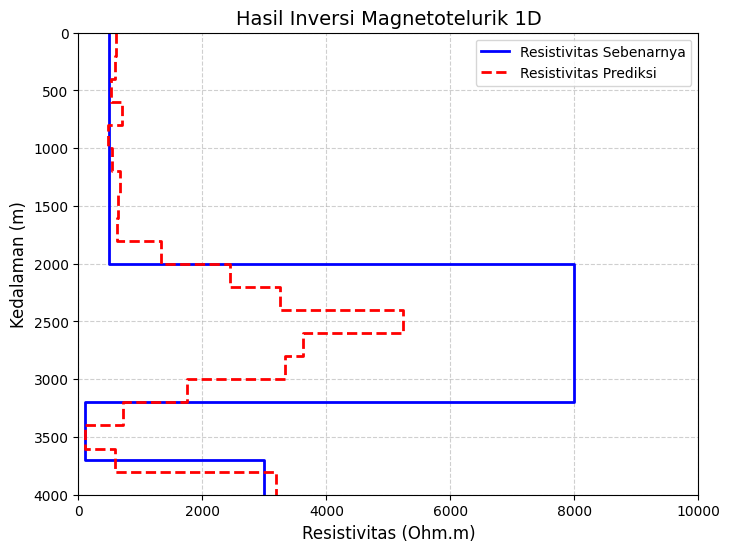

In [ ]:
plot_model_compare(resis_true, ketebalan_true, resis_predict, ketebalan_predict, total_depth)

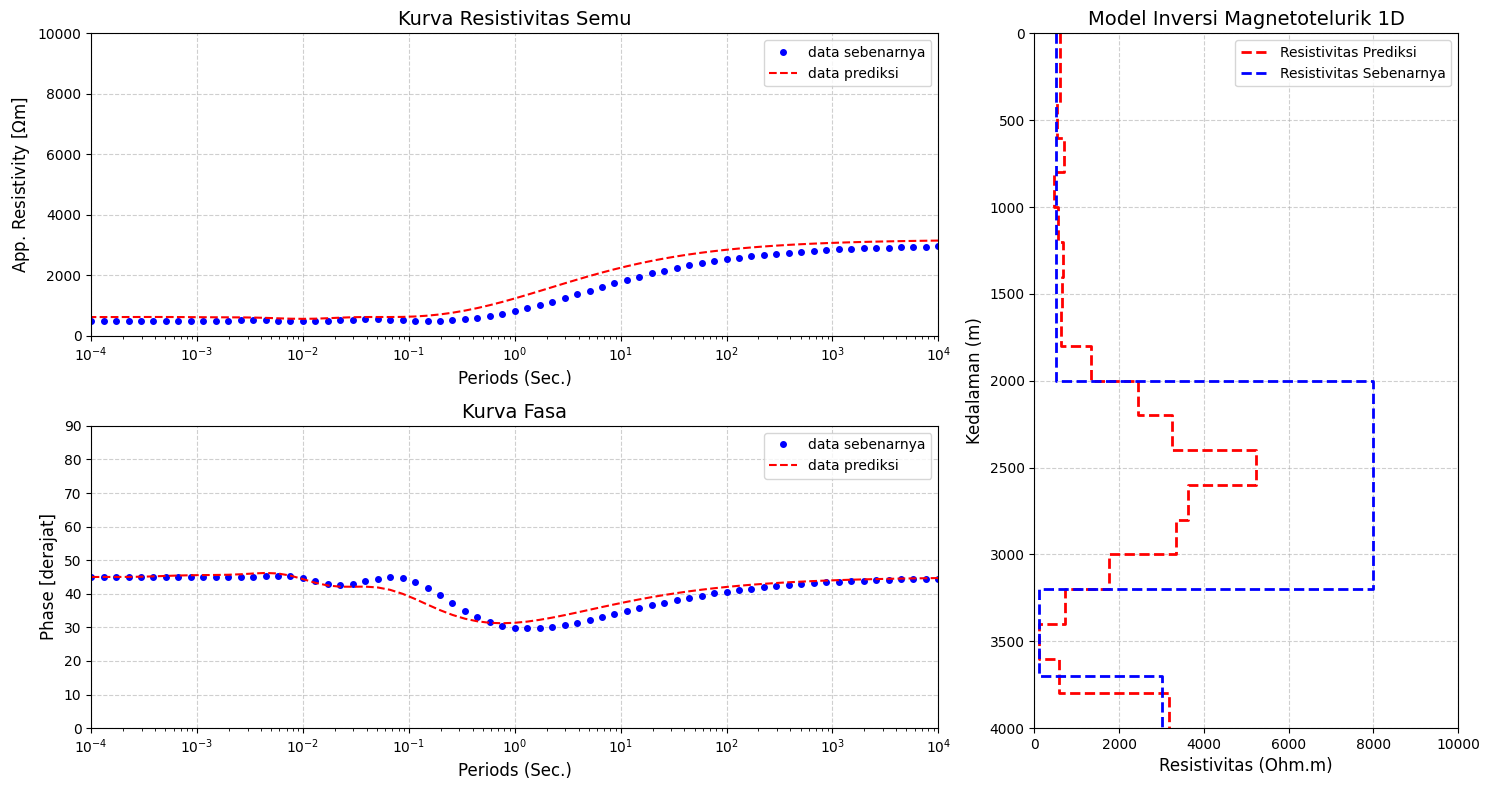

In [ ]:
plot_MT_compare(resis_true, ketebalan_true, resis_predict, ketebalan_predict, period, fasa, resistivitas_semu, fasa_predict,resistivitas_semu_predict, total_depth)

In [ ]:
measure_MSE(resistivitas_semu, fasa, resistivitas_semu_predict, fasa_predict)

MSE Resistivitas Semu: 74728.60
MSE Fasa: 3.76


In [ ]:
measure_MAPE(resistivitas_semu, fasa, resistivitas_semu_predict, fasa_predict)

MAPE resistivitas semu: 14.59%
MAPE fasa: 0.41%


[Interpolated] MSE model resistivitas: 5306338.9482
[Interpolated] MAPE model resistivitas: 247.56%


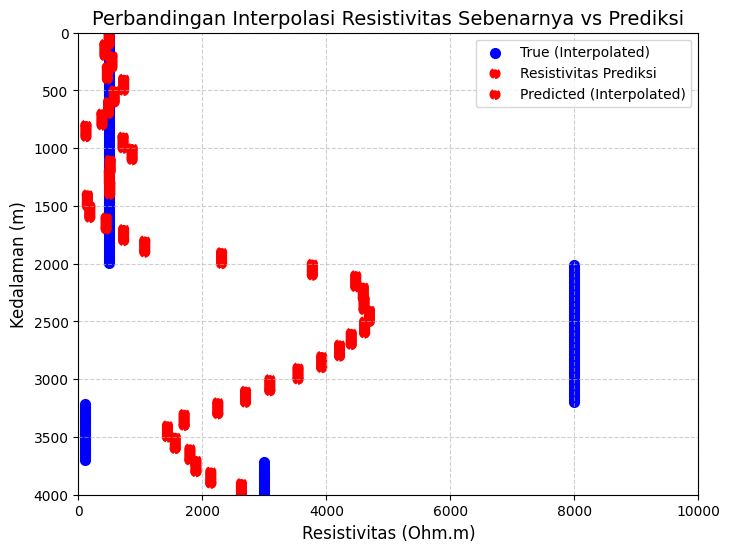

In [ ]:
measure_interpolated_resistivities(resis_true, ketebalan_true, resis_predict, ketebalan_predict, total_depth)